**Innovation Management · A.Y. 2026/27 · Politecnico di Torino** · Project Work · Group 34 · Step 0

| | |
|---|---|
| **Goal** | Build and validate the dataset of the **humanoid-robot** sector (Step 0 of the PW), for the bank's client **Electrolux**. |
| **Based on** | Tutorial 0, notebook `01_patstat_basics` (Prof. G. S. Ascione), adapted to our sector cell by cell. |
| **Design** | A deliberately wide net of candidate families, exact sector rules, and validation on families read blind by a human labeller. |
| **Target** | Precision of the strict sector ≥ 90%, with its 95% interval; recall measured against the wide net. |
| **PATSTAT environment** | TEST to develop the code, PROD for every number in the deck. |

# PATSTAT

PATSTAT has two parts. **PATSTAT Global** holds the bibliographic data of patent applications from offices worldwide: numbers, dates, priorities and families, applicants and inventors with their countries, IPC and CPC codes, citations, titles and abstracts. **PATSTAT EP Register** holds the procedural and legal history of European applications only (examination, opposition, transfers of ownership).

Step 0 uses **PATSTAT Global** only: every table we need to define the sector and describe it (families, years, codes, texts, applicants) is there. The EP Register becomes useful later, if a question is about the legal history of EP patents.

The cells below show the schema and the list of tables. For the precise meaning of a field we always check the PATSTAT Global manual (2026 edition) in the course material.


**Contents**

1. Setup
2. Inspecting the PATSTAT database schema
3. Querying with the ORM (SQLAlchemy): four queries on humanoid robots
4. Querying with raw SQL: the same queries, plus one on legal events
5. Step 0 of the PW: the humanoid-robot sector (definition, wide net, data, statistics on codes and terms, sector rules, validation)
6. Text retrieval: lexical vs semantic search (BM25 vs Patent SBERT) on our sector

## 1. Setup

### Import the libraries

In [1]:
import json
import time
from datetime import date
from pathlib import Path

import numpy as np
import pandas as pd
from sqlalchemy import func, or_

from epo.tipdata.patstat import PatstatClient
from epo.tipdata.patstat.database.models import (
    TLS201_APPLN,               # applications: family, office, dates, type of right, grant
    TLS202_APPLN_TITLE,         # titles
    TLS203_APPLN_ABSTR,         # abstracts
    TLS206_PERSON,              # persons (applicants and inventors)
    TLS207_PERS_APPLN,          # person <-> application links
    TLS209_APPLN_IPC,           # IPC codes (used for families without CPC)
    TLS224_APPLN_CPC,           # CPC codes
    TLS231_INPADOC_LEGAL_EVENT, # legal events (Section 4, example 5)
)

It is also possible to use

```python
from epo.tipdata.patstat.database import models
```

and then use `tab`-based auto-completion to get a hint on the list of the table models.

### Initiate the client object

**Note.** By default the client works on a **test database** (TEST, about 10,000 publications): fast, good for writing and checking code, but its counts are not the size of the sector. We switch to the full database (**PROD**) by changing `ENV` in the cell below; nothing else in the code changes. Only PROD numbers go in the deck.

In [2]:
ENV = "PROD"                       # "TEST" to develop the code, "PROD" for the real numbers

patstat = PatstatClient(env=ENV)   # connection to PATSTAT on TIP
db = patstat.orm()                 # SQLAlchemy session used by all ORM queries below
print(f"PATSTAT environment: {ENV}")

PATSTAT environment: PROD


## 2. Inspecting the PATSTAT database schema

### PATSTAT Global

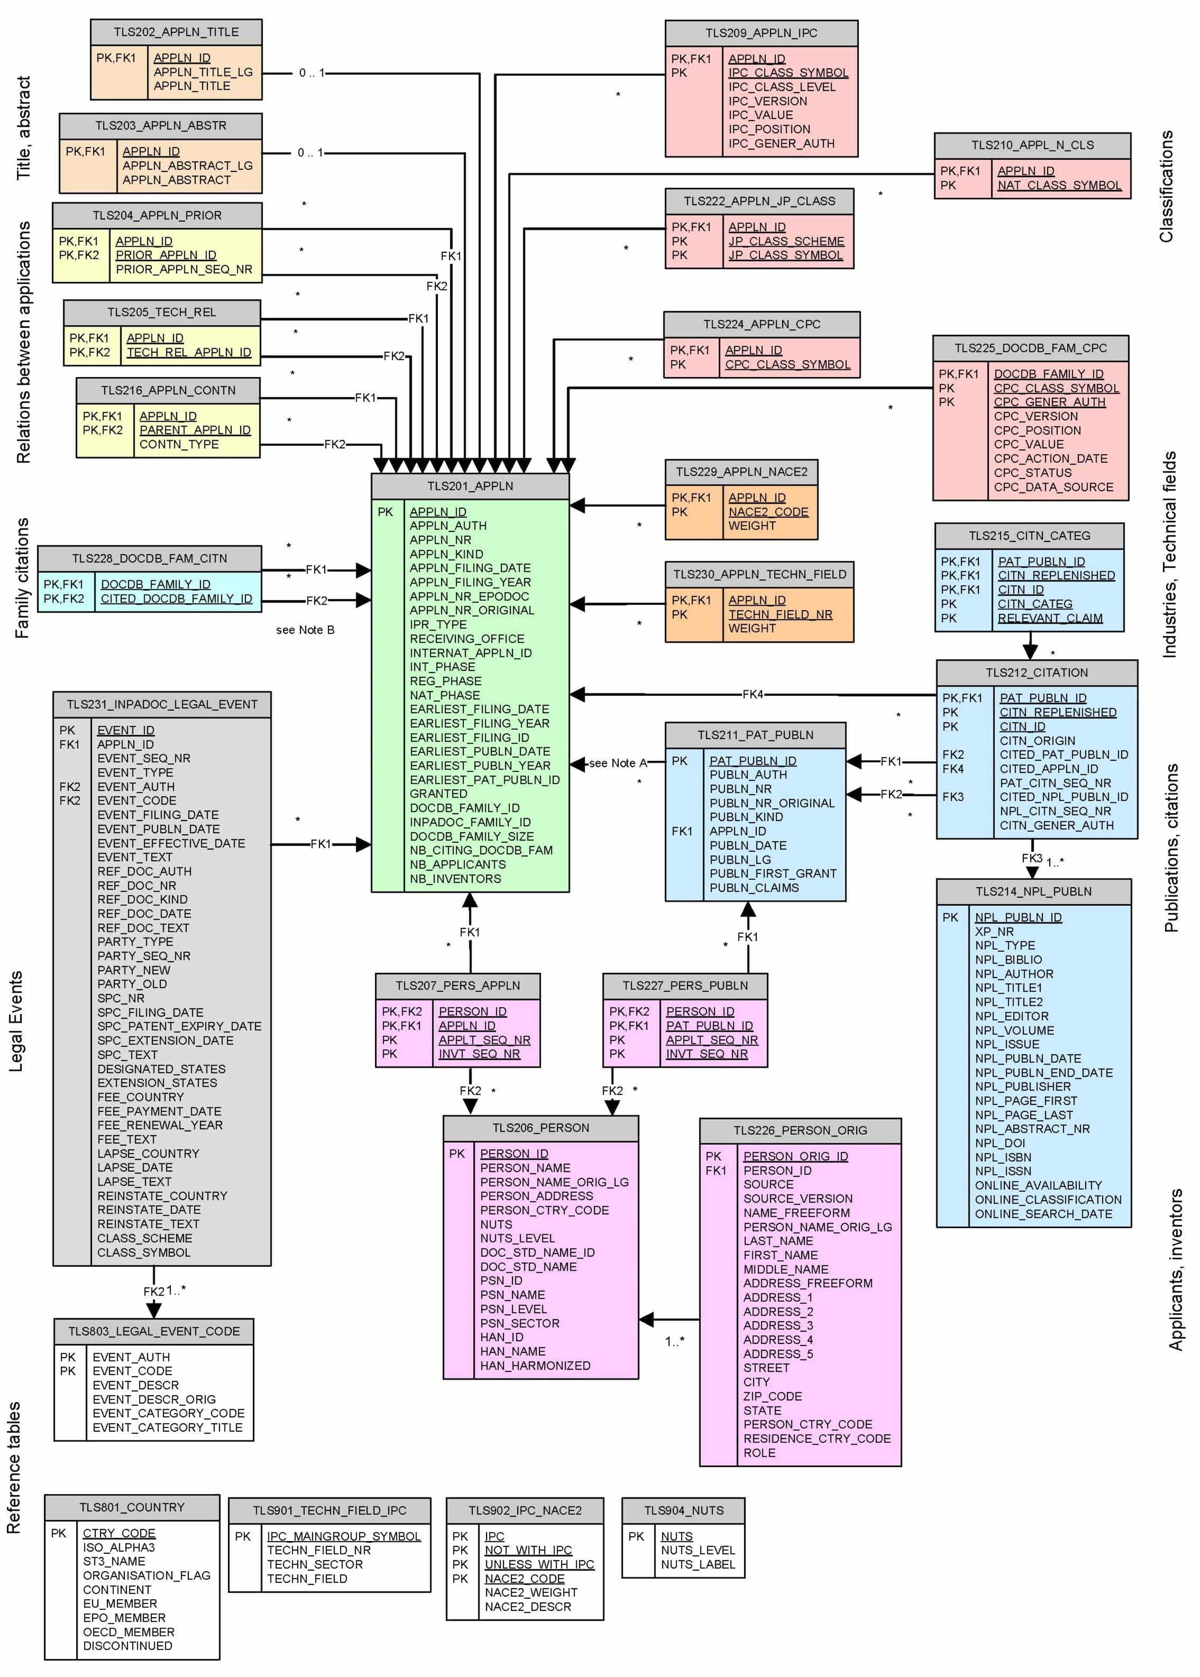

In [3]:
# The schema as a picture, as provided in the official documentation
patstat.global_schema()

In [4]:
# The same list of tables, as a Python list
patstat.list_global_tables()

['tls201_appln',
 'tls204_appln_prior',
 'tls205_tech_rel',
 'tls216_appln_contn',
 'tls209_appln_ipc',
 'tls210_appln_n_cls',
 'tls222_appln_jp_class',
 'tls224_appln_cpc',
 'tls225_docdb_fam_cpc',
 'tls228_docdb_fam_citn',
 'tls231_inpadoc_legal_event',
 'tls211_pat_publn',
 'tls212_citation',
 'tls214_npl_publn',
 'tls215_citn_categ',
 'tls206_person',
 'tls207_pers_appln',
 'tls226_person_orig',
 'tls227_pers_publn',
 'tls801_country',
 'tls803_legal_event_code',
 'tls901_techn_field_ipc',
 'tls902_ipc_nace2',
 'tls904_nuts',
 'tls229_appln_nace2',
 'tls230_appln_techn_field',
 'tls202_appln_title',
 'tls203_appln_abstr']

## 3. Using the ORM

ORM stands for Object-Relational Mapping. It is a programming approach that allows us to interact with a relational database using Python objects and methods instead of writing SQL statements directly. The EPO provides a Python ORM interface that maps these PATSTAT tables and their columns to Python objects.
The ORM then translates the Python instructions into SQL and sends the resulting query to the PATSTAT database.

The PATSTAT client contains an implementation of **SQLAlchemy**, a well-known ORM library for Python. Conceptually, the correspondence is:

| SQL | SQLAlchemy ORM |
|---|---|
| a table | a Python model, e.g. `TLS201_APPLN` |
| a column | an attribute, e.g. `TLS201_APPLN.appln_filing_year` |
| `SELECT` | `db.query(...)` |
| `WHERE` | `.filter(...)` |
| `JOIN` | `.join(...)` |
| `ORDER BY` | `.order_by(...)` |
| `GROUP BY` | `.group_by(...)` |

In the queries below every `JOIN` states its join condition explicitly (`A.appln_id == B.appln_id`): it is more verbose, but it makes each query readable on its own and independent of the foreign keys declared in the models.

`patstat.df(query)` executes a query and returns a `pandas.DataFrame`.

### Four queries on our sector

The four queries of the template, rewritten for humanoid robots. They are also a first look at the data: each one shows a problem that Section 5 has to solve.

#### Example 1: granted EP applications in the walking-machine code

Granted applications filed at the EPO (direct + PCT) between 2015 and 2020 with CPC **B62D57/032** (walking members with alternately lifted legs or feet). PATSTAT stores the symbol with padding blanks (`B62D  57/032`): we remove them before comparing.

This is the core CPC code for legged robots (Giuntelli et al., 2026), but it also holds quadrupeds and other walking machines: Section 5 measures how many of its families are humanoid.

In [5]:
WALKING_CPC = "B62D57/032"   # walking members with alternately lifted legs or feet (checked on the CPC scheme)

q_walking_ep = (
    db.query(
        TLS201_APPLN.appln_id,
        TLS201_APPLN.docdb_family_id,
        TLS201_APPLN.appln_auth,
        TLS201_APPLN.appln_nr,
        TLS201_APPLN.appln_kind,
        TLS201_APPLN.appln_filing_date,
        TLS224_APPLN_CPC.cpc_class_symbol,
    )
    .join(TLS224_APPLN_CPC, TLS201_APPLN.appln_id == TLS224_APPLN_CPC.appln_id)
    .filter(
        TLS201_APPLN.appln_filing_year.between(2015, 2020),
        TLS201_APPLN.appln_auth == "EP",
        TLS201_APPLN.granted == "Y",
        func.replace(TLS224_APPLN_CPC.cpc_class_symbol, " ", "") == WALKING_CPC,  # blanks removed
    )
    .order_by(TLS201_APPLN.appln_filing_date)
)

df_walking_ep = patstat.df(q_walking_ep)
print(f"{len(df_walking_ep)} applications, {df_walking_ep['docdb_family_id'].nunique()} families")
df_walking_ep.head(10)

46 applications, 40 families


,appln_id,docdb_family_id,appln_auth,appln_nr,appln_kind,appln_filing_date,cpc_class_symbol
0,545130679,55163517,EP,21155566,A,2015-06-24,B62D 57/032
1,448880675,55163517,EP,15825127,A,2015-06-24,B62D 57/032
2,561084189,55163531,EP,21208760,A,2015-07-07,B62D 57/032
3,448879541,55163531,EP,15823970,A,2015-07-07,B62D 57/032
4,503360308,55163635,EP,18207362,A,2015-07-21,B62D 57/032
5,448880832,55163635,EP,15825261,A,2015-07-21,B62D 57/032
6,444227262,55347481,EP,15754383,A,2015-08-14,B62D 57/032
7,507100096,55347481,EP,19155331,A,2015-08-14,B62D 57/032
8,445225540,54697516,EP,15382467,A,2015-09-28,B62D 57/032
9,450320201,53052215,EP,16160582,A,2016-03-16,B62D 57/032


#### Example 2: applications with "humanoid" in the title

Applications filed 2015–2020 at any office whose title contains *humanoid*: patents of invention only, without PATSTAT's artificial records (`appln_id` ≥ 900,000,000).

PATSTAT stores one title per application, in English when one exists. A Chinese family is found here only if one of its applications has an English title: Section 5 also searches other languages.

In [6]:
HUMANOID_TERM = "humanoid"

q_humanoid_title = (
    db.query(
        TLS201_APPLN.appln_id,
        TLS201_APPLN.docdb_family_id,
        TLS201_APPLN.appln_auth,
        TLS201_APPLN.appln_filing_year,
        TLS202_APPLN_TITLE.appln_title_lg,
        TLS202_APPLN_TITLE.appln_title,
    )
    .join(TLS202_APPLN_TITLE, TLS201_APPLN.appln_id == TLS202_APPLN_TITLE.appln_id)
    .filter(
        TLS201_APPLN.appln_filing_year.between(2015, 2020),
        TLS201_APPLN.appln_id < 900_000_000,   # no artificial records
        TLS201_APPLN.ipr_type == "PI",         # patents of invention only
        func.lower(TLS202_APPLN_TITLE.appln_title).like(f"%{HUMANOID_TERM}%"),
    )
    .order_by(TLS201_APPLN.appln_filing_year)
)

df_humanoid_title = patstat.df(q_humanoid_title)
print(f"{len(df_humanoid_title)} applications, {df_humanoid_title['docdb_family_id'].nunique()} families")
df_humanoid_title.head(10)

945 applications, 657 families


,appln_id,docdb_family_id,appln_auth,appln_filing_year,appln_title_lg,appln_title
0,450768395,55549064,CN,2015,en,Two-degree-of-freedom series-parallel low-freq...
1,473874291,57734776,KR,2015,en,APPARATUS AND METHOD FOR CONTROLLING POSTURE O...
2,493431580,50628742,BR,2015,pt,método de realizar diálogo multimodal entre um...
3,471219131,50628736,CA,2015,en,"SYSTEM, METHOD AND COMPUTER PROGRAM PRODUCT FO..."
4,441605185,51830406,EP,2015,en,SAFETY OF A HUMANOID-TYPE ROBOT
5,470037072,50639718,SG,2015,en,ACTUATION OF A HAND INTENDED FOR BEING PROVIDE...
6,446988887,54698958,WO,2015,en,"ACTUATOR DEVICE, HUMANOID ROBOT, AND POWER ASS..."
7,475620794,50639718,CN,2015,en,Actuation of a hand intended for being provide...
8,476532479,51059387,US,2015,en,Standby mode of a humanoid robot
9,425732377,50639719,WO,2015,en,HAND INTENDED FOR BEING PROVIDED ON A HUMANOID...


#### Example 3: the applications of one applicant, UBTECH

UBTECH Robotics is one of the largest humanoid-robot applicants. We search the PATSTAT standardised name (`psn_name`) with a wildcard, then count the spellings behind it: the same firm appears under several `person_name` values, and sometimes without a country. This is the "name game" that Step 2 has to solve before any ranking.

In [7]:
APPLICANT_PATTERN = "%UBTECH%"   # psn_name is upper case

q_ubtech = (
    db.query(
        TLS201_APPLN.appln_id,
        TLS201_APPLN.docdb_family_id,
        TLS201_APPLN.appln_auth,
        TLS201_APPLN.appln_filing_year,
        TLS206_PERSON.person_name,
        TLS206_PERSON.psn_name,
        TLS206_PERSON.person_ctry_code,
        TLS202_APPLN_TITLE.appln_title,
    )
    .select_from(TLS201_APPLN)
    .join(TLS207_PERS_APPLN, TLS201_APPLN.appln_id == TLS207_PERS_APPLN.appln_id)
    .join(TLS206_PERSON, TLS207_PERS_APPLN.person_id == TLS206_PERSON.person_id)
    .outerjoin(TLS202_APPLN_TITLE, TLS201_APPLN.appln_id == TLS202_APPLN_TITLE.appln_id)
    .filter(
        TLS206_PERSON.psn_name.like(APPLICANT_PATTERN),
        TLS207_PERS_APPLN.applt_seq_nr > 0,      # as applicant, not as inventor
        TLS201_APPLN.appln_id < 900_000_000,
    )
    .order_by(TLS201_APPLN.appln_filing_year.desc())
)

df_ubtech = patstat.df(q_ubtech)
print(f"{len(df_ubtech)} applications, {df_ubtech['docdb_family_id'].nunique()} families")

# How many spellings hide behind the same standardised name?
(df_ubtech.groupby(["psn_name", "person_name", "person_ctry_code"], dropna=False)
          .size().rename("applications").reset_index()
          .sort_values("applications", ascending=False))

4815 applications, 4016 families


,psn_name,person_name,person_ctry_code,applications
146,UBTECH ROBOTICS CORPORATION,UBTECH ROBOTICS CORP.,,3262
144,UBTECH ROBOTICS CORPORATION,UBTECH ROBOTICS CORP LTD,CN,545
105,NANOLUBTECH (WUXI) SCI&TECH COMPANY,"NANOLUBTECH (WUXI) SCI&TECH CO., LTD.",,188
151,UBTECH ROBOTICS CORPORATION,UBTECH Robotics Corp.,CN,113
150,UBTECH ROBOTICS CORPORATION,UBTECH Robotics Corp,CN,109
...,...,...,...,...
154,UBTECHI ROBOTICS CORP,UBTECHI ROBOTICS CORP LTD,CN,1
155,UBTECHNOLOGY COMPANY,UB TECHNOLOGY,KR,1
156,UBTECHNOLOGY COMPANY,"UBTECHNOLOGY CO., LTD",KR,1
158,WALTHER-STAUBTECHNIK,WALTHER-STAUBTECHNIK G.M.B.H.,DE,1


#### Example 4: a hit list of applicants

The ten applicants with the most **families** (not applications) with *humanoid* in the title, filed 2015–2020. A person is an applicant when `applt_seq_nr > 0` in `TLS207`. We count distinct `docdb_family_id`, so an invention filed at five offices counts once.

In [8]:
n_families = func.count(TLS201_APPLN.docdb_family_id.distinct())   # one invention = one count

q_top_applicants = (
    db.query(
        TLS206_PERSON.psn_name,
        TLS206_PERSON.person_ctry_code,
        n_families.label("families"),
    )
    .select_from(TLS201_APPLN)
    .join(TLS202_APPLN_TITLE, TLS201_APPLN.appln_id == TLS202_APPLN_TITLE.appln_id)
    .join(TLS207_PERS_APPLN, TLS201_APPLN.appln_id == TLS207_PERS_APPLN.appln_id)
    .join(TLS206_PERSON, TLS207_PERS_APPLN.person_id == TLS206_PERSON.person_id)
    .filter(
        TLS207_PERS_APPLN.applt_seq_nr > 0,
        TLS201_APPLN.appln_filing_year.between(2015, 2020),
        TLS201_APPLN.appln_id < 900_000_000,
        func.lower(TLS202_APPLN_TITLE.appln_title).like(f"%{HUMANOID_TERM}%"),
    )
    .group_by(TLS206_PERSON.psn_name, TLS206_PERSON.person_ctry_code)
    .order_by(n_families.desc())
    .limit(10)
)

patstat.df(q_top_applicants)

,psn_name,person_ctry_code,families
0,CHANGZHOU UNIVERSITY,,38
1,BEIJING INSTITUTE OF TECHNOLOGY,,32
2,JIAXING UNIVERSITY,,21
3,UBTECH ROBOTICS CORPORATION,,20
4,SOFTBANK ROBOTICS EUROPE,FR,20
5,SOUTH CHINA UNIVERSITY OF TECHNOLOGY,,20
6,ALDEBARAN ROBOTICS,FR,19
7,HARBIN INSTITUTE OF TECHNOLOGY,,19
8,SOFTBANK ROBOTICS EUROPE,,17
9,UBTECH ROBOTICS CORPORATION,CN,15


## 4. Raw SQL

The same four queries written directly in SQL, without the ORM, plus a fifth one on legal events. Each SQL query is checked against its ORM version: the two must return the same rows.

We write all queries in **standard SQL** (`use_legacy_sql=False`), the current BigQuery dialect. The template shows the legacy dialect too; we do not need it, and standard SQL gives functions such as `REGEXP_CONTAINS` that Section 5 may use.

`patstat.sql_query(...)` returns a list of dictionaries (one per row): we turn it into a `DataFrame`. We do not need to write the project and dataset names: `sql_query` adds them.

### The same queries in SQL, plus one on legal events

#### Example 1 (SQL): granted EP applications in the walking-machine code

In [9]:
sql_walking_ep = """
SELECT tls201_appln.appln_id,
       tls201_appln.docdb_family_id,
       tls201_appln.appln_auth,
       tls201_appln.appln_nr,
       tls201_appln.appln_kind,
       tls201_appln.appln_filing_date,
       tls224_appln_cpc.cpc_class_symbol
FROM   tls201_appln
JOIN   tls224_appln_cpc ON tls201_appln.appln_id = tls224_appln_cpc.appln_id
WHERE  tls201_appln.appln_filing_year BETWEEN 2015 AND 2020                  -- filed 2015-2020
  AND  tls201_appln.appln_auth = 'EP'                                        -- at the EPO (direct + PCT)
  AND  tls201_appln.granted = 'Y'                                            -- granted
  AND  REPLACE(tls224_appln_cpc.cpc_class_symbol, ' ', '') = 'B62D57/032'    -- walking members, blanks removed
ORDER BY tls201_appln.appln_filing_date
"""

df_sql_walking = pd.DataFrame(patstat.sql_query(sql_walking_ep, use_legacy_sql=False))
print(f"{len(df_sql_walking)} applications | same as the ORM query: {len(df_sql_walking) == len(df_walking_ep)}")
df_sql_walking.head(10)

46 applications | same as the ORM query: True


,appln_id,docdb_family_id,appln_auth,appln_nr,appln_kind,appln_filing_date,cpc_class_symbol
0,448880675,55163517,EP,15825127,A,2015-06-24,B62D 57/032
1,545130679,55163517,EP,21155566,A,2015-06-24,B62D 57/032
2,561084189,55163531,EP,21208760,A,2015-07-07,B62D 57/032
3,448879541,55163531,EP,15823970,A,2015-07-07,B62D 57/032
4,503360308,55163635,EP,18207362,A,2015-07-21,B62D 57/032
5,448880832,55163635,EP,15825261,A,2015-07-21,B62D 57/032
6,444227262,55347481,EP,15754383,A,2015-08-14,B62D 57/032
7,507100096,55347481,EP,19155331,A,2015-08-14,B62D 57/032
8,445225540,54697516,EP,15382467,A,2015-09-28,B62D 57/032
9,450320201,53052215,EP,16160582,A,2016-03-16,B62D 57/032


#### Example 2 (SQL): applications with "humanoid" in the title

In [10]:
sql_humanoid_title = """
SELECT tls201_appln.appln_id,
       tls201_appln.docdb_family_id,
       tls201_appln.appln_auth,
       tls201_appln.appln_filing_year,
       tls202_appln_title.appln_title_lg,
       tls202_appln_title.appln_title
FROM   tls201_appln
JOIN   tls202_appln_title ON tls201_appln.appln_id = tls202_appln_title.appln_id
WHERE  tls201_appln.appln_filing_year BETWEEN 2015 AND 2020
  AND  tls201_appln.appln_id < 900000000                 -- no artificial records
  AND  tls201_appln.ipr_type = 'PI'                      -- patents of invention only
  AND  LOWER(tls202_appln_title.appln_title) LIKE '%humanoid%'
ORDER BY tls201_appln.appln_filing_year
"""

df_sql_humanoid = pd.DataFrame(patstat.sql_query(sql_humanoid_title, use_legacy_sql=False))
print(f"{len(df_sql_humanoid)} applications | same as the ORM query: {len(df_sql_humanoid) == len(df_humanoid_title)}")
df_sql_humanoid.head(10)

945 applications | same as the ORM query: True


,appln_id,docdb_family_id,appln_auth,appln_filing_year,appln_title_lg,appln_title
0,445467969,54297538,CN,2015,en,Bionic waist mechanism of humanoid robot and w...
1,483469917,50639718,NZ,2015,en,Actuation of a hand intended for being provide...
2,476532363,51022794,US,2015,en,Humanoid robot with collision avoidance and tr...
3,442643016,53559745,CN,2015,en,Humanoid mechanism displaying platform
4,490579788,51830407,NZ,2015,en,Anti-jamming system in a humanoid-type robot
5,474974489,57950771,JP,2015,en,"MOTOR SAFE STOP STRUCTURE, MOTOR CONTROL SYSTE..."
6,475196232,51894110,US,2015,en,Shock-absorbing device for a humanoid robot
7,443720535,53842544,CN,2015,en,Overload protection device for joint of humano...
8,477595661,50588609,CN,2015,en,Omnidirectional wheeled humanoid robot based o...
9,449743155,55329659,CN,2015,en,Embedded motion controller of humanoid robot


#### Example 3 (SQL): the applications of UBTECH

In [11]:
sql_ubtech = """
SELECT tls201_appln.appln_id,
       tls201_appln.docdb_family_id,
       tls201_appln.appln_auth,
       tls201_appln.appln_filing_year,
       tls206_person.person_name,
       tls206_person.psn_name,
       tls206_person.person_ctry_code
FROM   tls201_appln
JOIN   tls207_pers_appln ON tls201_appln.appln_id = tls207_pers_appln.appln_id
JOIN   tls206_person     ON tls207_pers_appln.person_id = tls206_person.person_id
WHERE  tls206_person.psn_name LIKE '%UBTECH%'
  AND  tls207_pers_appln.applt_seq_nr > 0                -- as applicant
  AND  tls201_appln.appln_id < 900000000
ORDER BY tls201_appln.appln_filing_year DESC
"""

df_sql_ubtech = pd.DataFrame(patstat.sql_query(sql_ubtech, use_legacy_sql=False))
print(f"{len(df_sql_ubtech)} applications | same as the ORM query: {len(df_sql_ubtech) == len(df_ubtech)}")
df_sql_ubtech.head(10)

4815 applications | same as the ORM query: True


,appln_id,docdb_family_id,appln_auth,appln_filing_year,person_name,psn_name,person_ctry_code
0,14846169,1279095,DE,9999,LUEHR H VDI STAUBTECHNIK,LUEHR H VDI STAUBTECHNIK,
1,14841662,1274616,DE,9999,LUEHR H VDI STAUBTECHNIK,LUEHR H VDI STAUBTECHNIK,
2,651343701,100208892,CN,2026,UBTECH ROBOTICS CORP.,UBTECH ROBOTICS CORPORATION,
3,650955823,100098994,CN,2026,UBTECH ROBOTICS CORP.,UBTECH ROBOTICS CORPORATION,
4,650516350,99977803,CN,2026,UBTECH ROBOTICS CORP.,UBTECH ROBOTICS CORPORATION,
5,651575384,100249694,CN,2026,UBTECH ROBOTICS CORP.,UBTECH ROBOTICS CORPORATION,
6,651111442,100135753,CN,2026,UBTECH ROBOTICS CORP.,UBTECH ROBOTICS CORPORATION,
7,648368469,99495209,CN,2026,UBTECH ROBOTICS CORP.,UBTECH ROBOTICS CORPORATION,
8,650512245,99975922,CN,2026,UBTECH ROBOTICS CORP.,UBTECH ROBOTICS CORPORATION,
9,651700858,100297660,CN,2026,UBTECH ROBOTICS CORP.,UBTECH ROBOTICS CORPORATION,


#### Example 4 (SQL): a hit list of applicants, counted in families

In [12]:
sql_top_applicants = """
SELECT tls206_person.psn_name,
       tls206_person.person_ctry_code,
       COUNT(DISTINCT tls201_appln.docdb_family_id) AS families      -- one invention = one count
FROM   tls201_appln
JOIN   tls202_appln_title ON tls201_appln.appln_id = tls202_appln_title.appln_id
JOIN   tls207_pers_appln  ON tls201_appln.appln_id = tls207_pers_appln.appln_id
JOIN   tls206_person      ON tls207_pers_appln.person_id = tls206_person.person_id
WHERE  tls207_pers_appln.applt_seq_nr > 0
  AND  tls201_appln.appln_filing_year BETWEEN 2015 AND 2020
  AND  tls201_appln.appln_id < 900000000
  AND  LOWER(tls202_appln_title.appln_title) LIKE '%humanoid%'
GROUP BY tls206_person.psn_name, tls206_person.person_ctry_code
ORDER BY families DESC
LIMIT 10
"""

pd.DataFrame(patstat.sql_query(sql_top_applicants, use_legacy_sql=False))

,psn_name,person_ctry_code,families
0,CHANGZHOU UNIVERSITY,,38
1,BEIJING INSTITUTE OF TECHNOLOGY,,32
2,JIAXING UNIVERSITY,,21
3,SOFTBANK ROBOTICS EUROPE,FR,20
4,SOUTH CHINA UNIVERSITY OF TECHNOLOGY,,20
5,UBTECH ROBOTICS CORPORATION,,20
6,ALDEBARAN ROBOTICS,FR,19
7,HARBIN INSTITUTE OF TECHNOLOGY,,19
8,SOFTBANK ROBOTICS EUROPE,,17
9,UBTECH ROBOTICS CORPORATION,CN,15


#### Example 5 (SQL): in which European countries are humanoid EP patents kept alive?

After grant, a European patent becomes a bundle of national patents, and the owner pays a renewal fee in each country where it wants protection. The INPADOC legal events table (`tls231_inpadoc_legal_event`) records these payments: event code `PGFP` means that a renewal fee was paid after grant, so the patent was granted and kept alive in that country.

We count, for each country, the EP families with *humanoid* in the title (filed 2010–2020) whose renewal fee was paid there. This is a first look at the **globalization** indicator of Step 3 (the professor uses these events for EP validations).

In [13]:
sql_renewals = """
SELECT tls231_inpadoc_legal_event.fee_country,
       COUNT(DISTINCT tls201_appln.docdb_family_id) AS families
FROM   tls201_appln
JOIN   tls202_appln_title         ON tls201_appln.appln_id = tls202_appln_title.appln_id
JOIN   tls231_inpadoc_legal_event ON tls201_appln.appln_id = tls231_inpadoc_legal_event.appln_id
WHERE  tls201_appln.appln_auth = 'EP'                                 -- EP applications
  AND  tls231_inpadoc_legal_event.event_code = 'PGFP'                 -- renewal fee paid after grant
  AND  tls201_appln.appln_filing_year BETWEEN 2010 AND 2020
  AND  LOWER(tls202_appln_title.appln_title) LIKE '%humanoid%'
GROUP BY tls231_inpadoc_legal_event.fee_country
ORDER BY families DESC
"""

pd.DataFrame(patstat.sql_query(sql_renewals, use_legacy_sql=False))

,fee_country,families
0,DE,24
1,GB,23
2,FR,23
3,BE,18
4,NL,18
5,IT,16
6,ES,6
7,SE,5
8,NO,4
9,DK,4


# 5. Step 0 of the PW: the humanoid-robot sector

### Why one query is not enough

Humanoid robots have no dedicated classification code, and many of their technologies (robot hands, sensors, motion planning, control) are shared with industrial and service robots. The literature therefore delineates fields like this one with a **combination of classification codes and keywords** (Benson & Magee, 2013), possibly checked afterwards by a classifier or a semantic method (Kreuchauff & Korzinov, 2017; Giuntelli et al., 2026).

- Codes alone cannot delineate an emerging field, which official classifications do not cover yet (Kreuchauff & Korzinov, 2017).
- The core code for legged walking, **B62D57/032**, is precise but incomplete: in Giuntelli et al. (2026, Table 3) it finds 7 legged-robot patents, all relevant, out of 66 relevant ones.
- Keywords miss patents that describe a humanoid only with anatomical terms, unless terms such as *humanoid* or *bipedal robot* are part of the query (Giuntelli et al., 2026).
- **B25J11/0015** (face robots) is one of the codes WIPO uses to map robotics patents (Keisner, Raffo & Wunsch-Vincent, 2015, technical annex).

### Definition of a humanoid robot (the labelling rule)

Fixed **before** any query and any reading: every family we read is labelled against this text.

> A **humanoid robot** is a physical robot whose body reproduces the human form (a head, a torso, two arms and/or two legs) and that moves or acts in environments made for people: full-size and small humanoids, biped walking robots, wheeled robots with a human upper body, and android robots with a human-like face. The sector includes the robot itself, the parts designed for a humanoid (legs, feet, hands, arms, torso, head and face, joints and actuators) and the methods to control it (walking, balance, whole-body control, manipulation, interaction, teleoperation, training of its motion policies).

Each family gets two labels. The **strict** label defines the sector and every validation number; the **broad** label is only a sensitivity check. Always strict ≤ broad.

- **Strict = 1** only if a humanoid is the subject of the patent: the robot, a part or a method designed for a humanoid or a biped, named in the title or abstract or evident from the body described. 0 if a humanoid is only mentioned as one possible application.
- **Broad = 1** if the patent matches the definition even partly.

| Case | Strict = 1 | Strict = 0, broad = 1 | Both 0 |
|---|---|---|---|
| Legged robots | biped, two legs | legs with knee and ankle, number not stated | quadrupeds, hexapods, multi-legged robots |
| Wheeled humanoids | head, torso and two arms on a wheeled base | – | – |
| Hands | hand designed for a (named) humanoid | anthropomorphic multi-fingered robot hand, humanoid not named | industrial grippers, prostheses |
| Head and face | robot head or face with human expressions | – | screens showing a drawn face |
| Dual-arm robots | with torso and head (upper body of a humanoid) | – | industrial dual arms without head or torso |
| Components (actuators, reducers, sensors, skin, batteries) | designed for a named humanoid | for robots in general, humanoid cited as a possible use | generic components |
| Software methods (AI, planning) | applied to a humanoid or biped as the subject | humanoid cited among examples | generic robots, no humanoid |
| Simulation | training or testing a physical humanoid | – | avatars, animated characters, digital humans |
| Toys | – | humanoid toys with motorised parts | dolls and figures without motorised parts |
| Social robots | human body or face | – | animal or abstract shape |
| Exoskeletons, prostheses, walking aids | – | – | always 0 (worn by a person) |
| Mannequins, crash-test dummies, silhouettes | – | – | always 0 |
| "Humanoid" in another sense (human shape in an image, person detection) | – | – | always 0 |

### Design: wide net, exact rules, blind validation

| Stage | What it does | Where |
|---|---|---|
| 1 · Wide net | Four SQL blocks (strong keywords, medium keywords, IPC, CPC) collect every family that could belong to the sector | 5.1–5.6 |
| 2 · Data | For every family of the net: applications, titles and abstracts in all languages, CPC and IPC codes | 5.7 |
| 3 · Statistics on codes and terms | Which codes and terms actually carry humanoid families (Benson & Magee, 2013) | 5.8 |
| 4 · Sector rules | Exact rules in Python, whole-word matching, at family level | 5.9–5.10 |
| 5 · Validation | Random samples read blind against the definition: precision by block, period and office, recall against the net | 5.11–5.12 |

SQL `LIKE` matches pieces of words (`'%hip%'` also finds *ship* and *chip*): stage 1 is only a net, and whole-word matching is done in stage 4.

### 5.1 Search definitions

The lists below are the *data* of the search, kept separate from the *code* that runs it. The net has four blocks:

| Block | What enters | Source |
|---|---|---|
| `strong_terms` | a term that names the humanoid, in a title or abstract, in English, other European languages, Chinese, Japanese or Korean | Kim et al. (2016); Giuntelli et al. (2026) |
| `medium_terms` | a term often, but not only, about humanoids (legged robot, dexterous hand, zero moment point…) | Liu & Luo (2007); Kreuchauff & Korzinov (2017) |
| `ipc` | IPC codes for walking machines and robots replicating humans, for families without CPC | CPC/IPC scheme |
| `cpc` | CPC codes for walking machines, face robots, robots replicating humans, human-like hands, walking toy figures | CPC scheme; Keisner et al. (2015); Giuntelli et al. (2026) |

Most families of the medium-terms block will be filtered out: the block exists to find humanoid parts and to measure recall.

In [14]:
# ---------------------------------------------------------------- outputs and counting rules
OUT_DIR = Path("outputs/step0") / ENV.lower()   # every file of Section 5 is saved here
OUT_DIR.mkdir(parents=True, exist_ok=True)

YEAR_MIN, YEAR_MAX = 2000, 2025      # earliest priority year of the family (template of Tutorial 0, notebook 02)
LAST_COMPLETE_YEAR = 2022            # 2023-2025 are incomplete (18-month publication lag): flagged, never read as a decline
IPR_TYPES_NET = ("PI", "UM")         # patents and utility models enter the net; the choice for the sector is made in 5.10
DUMMY_ID_FROM = 900_000_000          # appln_id from this value on are artificial records created by PATSTAT

# ---------------------------------------------------------------- keywords, strong: they name the humanoid directly
STRONG_TERMS = [
    # English ("biped" also finds "bipedal"; "humanoid" also finds "humanoids")
    "humanoid", "biped", "two-legged", "two legged",
    "android robot", "anthropomorphic robot",
    "human-like robot", "humanlike robot", "human like robot",
    "human-shaped robot", "human shaped robot", "human-type robot", "human type robot", "human-form robot",
    # other European languages
    "humanoïde", "humanoider", "umanoide", "zweibeinig", "bipède",
    # Chinese (simplified and traditional)
    "人形机器人", "人形機器人", "仿人机器人", "仿人機器人", "类人机器人", "類人機器人",
    "双足机器人", "雙足機器人", "双足步行", "拟人机器人", "仿人灵巧手", "仿人手", "类人手",
    # Japanese
    "ヒューマノイド", "人型ロボット", "人形ロボット", "人間型ロボット", "二足歩行",
    # Korean
    "휴머노이드", "인간형 로봇", "이족 보행", "이족보행",
]

# ---------------------------------------------------------------- keywords, medium: often but not only about humanoids
MEDIUM_TERMS = [
    "legged robot", "walking robot",
    "dexterous hand", "multi-fingered hand", "multifingered hand", "multi-finger hand",
    "robot hand", "robotic hand",
    "zero moment point", "zero-moment point",       # Liu & Luo (2007): ZMP is the main method to stabilise biped walking
    "whole-body control", "whole body control",
    "robot head", "robot face",
]

In [15]:
# IPC codes: used to catch families that have IPC but no CPC codes (frequent for national filings)
NET_IPC = {
    "B62D57/02":  "vehicles with ground-engaging propulsion means, e.g. walking members (incl. /021-/028)",
    "B62D57/032": "walking members with alternately or sequentially lifted supporting base and legs, or feet",
    "G06N3/008":  "artificial life based on physical entities, e.g. robots replicating pets or humans",
}

In [16]:
# CPC codes. Titles checked on the CPC scheme (cooperativepatentclassification.org), 12 Nov 2026.
NET_CPC = {
    "B62D57/02":   "vehicles with ground-engaging propulsion means, e.g. walking members (incl. /021-/028)",
    "B62D57/032":  "walking members with alternately or sequentially lifted supporting base and legs, or feet",
    "B25J11/0015": "face robots, animated artificial faces for imitating human expressions",
    "G06N3/008":   "artificial life based on physical entities, e.g. robots replicating pets or humans",
    "B25J15/0009": "end effectors with multi-articulated fingers, e.g. resembling a human hand",
    "A63H11/18":   "figure toys which perform a realistic walking motion (incl. /20)",
}

# We save every choice next to the outputs, so each file can be traced back to the settings that made it.
config_used = {
    "env": ENV, "years": [YEAR_MIN, YEAR_MAX], "last_complete_year": LAST_COMPLETE_YEAR,
    "ipr_types_net": IPR_TYPES_NET, "strong_terms": STRONG_TERMS, "medium_terms": MEDIUM_TERMS,
    "net_ipc": NET_IPC, "net_cpc": NET_CPC,
}
(OUT_DIR / "00_config_used.json").write_text(json.dumps(config_used, ensure_ascii=False, indent=2))
print(f"{len(STRONG_TERMS)} strong terms | {len(MEDIUM_TERMS)} medium terms | "
      f"{len(NET_IPC)} IPC codes | {len(NET_CPC)} CPC codes | outputs in {OUT_DIR}")

41 strong terms | 14 medium terms | 3 IPC codes | 6 CPC codes | outputs in outputs/step0/prod


### 5.2 Reusable query builders

Each block is a function that returns the **DOCDB families** it catches (one invention = one family). A family enters through any of its applications: a Chinese priority and its English-language EP application are the same invention, and the English text often sits only on the second one.

- **Keywords** are matched with `LIKE '%term%'` on the lower-cased title and abstract.
- **Classification symbols** are stored with padding blanks (`B62D  57/032`): we remove them before comparing and match by prefix, so a code also selects its subgroups.
- **Common filters** on every block: real applications only, earliest priority year in the window, patents or utility models.

In [17]:
FAMILY = TLS201_APPLN.docdb_family_id.label("docdb_family_id")


def no_blanks(column):
    """Classification symbol without the padding blanks of PATSTAT ('B62D  57/032' -> 'B62D57/032')."""
    return func.replace(column, " ", "")


def symbol_prefix_condition(symbol_column, codes):
    """OR-condition: the blank-stripped symbol starts with one of the codes, so a code also selects its subgroups."""
    symbol = no_blanks(symbol_column)
    return or_(*(symbol.like(code.replace(" ", "") + "%") for code in codes))


def keyword_condition(terms):
    """OR-condition: one of the terms appears in the title or in the abstract (case-insensitive)."""
    title = func.lower(TLS202_APPLN_TITLE.appln_title)
    abstract = func.lower(TLS203_APPLN_ABSTR.appln_abstract)
    return or_(*(column.like(f"%{t.lower()}%") for t in terms for column in (title, abstract)))


def common_filters(q):
    """Filters shared by every block: real applications, priority year in the window, patents or utility models."""
    return q.filter(
        TLS201_APPLN.appln_id < DUMMY_ID_FROM,
        TLS201_APPLN.earliest_filing_year.between(YEAR_MIN, YEAR_MAX),
        TLS201_APPLN.ipr_type.in_(IPR_TYPES_NET),
    )


def query_by_keywords(terms):
    """Families with at least one application whose title or abstract contains one of the terms."""
    q = (
        db.query(FAMILY)
        .select_from(TLS201_APPLN)
        .outerjoin(TLS202_APPLN_TITLE, TLS201_APPLN.appln_id == TLS202_APPLN_TITLE.appln_id)
        .outerjoin(TLS203_APPLN_ABSTR, TLS201_APPLN.appln_id == TLS203_APPLN_ABSTR.appln_id)
        .filter(keyword_condition(terms))
    )
    return common_filters(q).distinct()


def query_by_ipc(codes):
    """Families with at least one application carrying one of the IPC codes."""
    q = (
        db.query(FAMILY)
        .select_from(TLS201_APPLN)
        .join(TLS209_APPLN_IPC, TLS201_APPLN.appln_id == TLS209_APPLN_IPC.appln_id)
        .filter(symbol_prefix_condition(TLS209_APPLN_IPC.ipc_class_symbol, codes))
    )
    return common_filters(q).distinct()


def query_by_cpc(codes):
    """Families with at least one application carrying one of the CPC codes."""
    q = (
        db.query(FAMILY)
        .select_from(TLS201_APPLN)
        .join(TLS224_APPLN_CPC, TLS201_APPLN.appln_id == TLS224_APPLN_CPC.appln_id)
        .filter(symbol_prefix_condition(TLS224_APPLN_CPC.cpc_class_symbol, codes))
    )
    return common_filters(q).distinct()


def run_block(name, query):
    """Run one block of the net and return the set of its families (with the time it took)."""
    t0 = time.time()
    families = set(patstat.df(query)["docdb_family_id"].astype("int64"))
    print(f"{name:14s} {len(families):>9,} families   ({time.time() - t0:.0f} s)")
    return families


def reset_connection():
    """Run this if a query was stopped by hand: the session stays broken (PendingRollbackError) until rolled back."""
    db.rollback()


NET_QUERIES = {}   # block name -> query, filled by the next cells
NET_IDS = {}       # block name -> set of docdb_family_id

### 5.3 Blocks 1 and 2: strong and medium keywords

In [18]:
NET_QUERIES["strong_terms"] = query_by_keywords(STRONG_TERMS)
NET_QUERIES["medium_terms"] = query_by_keywords(MEDIUM_TERMS)
NET_IDS["strong_terms"] = run_block("strong_terms", NET_QUERIES["strong_terms"])
NET_IDS["medium_terms"] = run_block("medium_terms", NET_QUERIES["medium_terms"])

strong_terms       8,022 families   (1 s)
medium_terms      10,577 families   (1 s)


### 5.4 Block 3: IPC codes

In [19]:
NET_QUERIES["ipc"] = query_by_ipc(list(NET_IPC))
NET_IDS["ipc"] = run_block("ipc", NET_QUERIES["ipc"])

ipc               23,523 families   (1 s)


### 5.5 Block 4: CPC codes

In [20]:
NET_QUERIES["cpc"] = query_by_cpc(list(NET_CPC))
NET_IDS["cpc"] = run_block("cpc", NET_QUERIES["cpc"])

cpc               16,590 families   (1 s)


### 5.6 The wide net: union of the four blocks

A family is in the net if at least one block catches it (a `UNION`, as in the template). We keep one True/False column per block, to know later which block brought each family, and we save the queries as SQL text: the repository holds the queries, not the data.

In [21]:
# One row per family of the net, with one True/False column per block.
net = pd.DataFrame({"docdb_family_id": sorted(set().union(*NET_IDS.values()))})
for name, ids in NET_IDS.items():
    net[f"net_{name}"] = net["docdb_family_id"].isin(ids)
print(f"wide net (union of the blocks): {len(net):,} families")

# The queries go in the repository (not the data): we save them as SQL text.
query_dir = OUT_DIR / "queries"
query_dir.mkdir(exist_ok=True)
for name, q in NET_QUERIES.items():
    try:
        sql = str(q.statement.compile(compile_kwargs={"literal_binds": True}))
    except Exception as error:      # some dialects cannot write every value inside the text
        sql = f"-- written without values ({error})\n{q.statement}"
    (query_dir / f"net_{name}.sql").write_text(sql)
net.to_csv(OUT_DIR / "01_net_blocks.csv.gz", index=False)
print(f"saved 01_net_blocks.csv.gz and {len(NET_QUERIES)} queries in {query_dir}")

wide net (union of the blocks): 42,351 families
saved 01_net_blocks.csv.gz and 4 queries in outputs/step0/prod/queries


In [22]:
# How do the blocks overlap? Each row is one combination of blocks.
block_cols = [f"net_{name}" for name in NET_IDS]
overlap = (
    net.groupby(block_cols).size().rename("families").reset_index()
    .sort_values("families", ascending=False)
    .reset_index(drop=True)
)
overlap["share (%)"] = (overlap["families"] / overlap["families"].sum() * 100).round(1)
overlap

,net_strong_terms,net_medium_terms,net_ipc,net_cpc,families,share (%)
0,False,False,True,False,10717,25.3
1,False,False,True,True,10291,24.3
2,False,True,False,False,7812,18.4
3,True,False,False,False,5733,13.5
4,False,False,False,True,3530,8.3
5,False,True,False,True,817,1.9
6,True,False,True,True,711,1.7
7,False,True,True,True,671,1.6
8,True,False,True,False,505,1.2
9,False,True,True,False,491,1.2


### 5.7 Download the data of the net

For every family of the net we download, once, everything the rules and the labelling need: its applications, titles and abstracts **in every language**, and its CPC and IPC codes. Language is never a filter for the sector.

The filter "family in the net" runs inside PATSTAT (`IN (net query)`, as in Tutorial 0, notebook 02): we never send long lists of identifiers.

In [23]:
net_query = (
    NET_QUERIES["strong_terms"]
    .union(NET_QUERIES["medium_terms"], NET_QUERIES["ipc"], NET_QUERIES["cpc"])
    .subquery()
)


def in_net(q):
    """Keep only the applications of the families in the wide net (the filter runs inside PATSTAT)."""
    return q.filter(
        TLS201_APPLN.docdb_family_id.in_(net_query.select()),
        TLS201_APPLN.appln_id < DUMMY_ID_FROM,
    )


def timed_df(label, q):
    t0 = time.time()
    df = patstat.df(q)
    print(f"{label:13s} {len(df):>10,} rows   ({time.time() - t0:.0f} s)")
    return df


apps = timed_df("applications", in_net(db.query(
    TLS201_APPLN.appln_id, TLS201_APPLN.docdb_family_id, TLS201_APPLN.appln_auth,
    TLS201_APPLN.appln_nr_epodoc, TLS201_APPLN.appln_kind, TLS201_APPLN.ipr_type,
    TLS201_APPLN.appln_filing_year, TLS201_APPLN.earliest_filing_year,
    TLS201_APPLN.granted, TLS201_APPLN.docdb_family_size, TLS201_APPLN.nb_citing_docdb_fam,
)))

titles = timed_df("titles", in_net(
    db.query(TLS201_APPLN.docdb_family_id, TLS202_APPLN_TITLE.appln_id,
             TLS202_APPLN_TITLE.appln_title_lg, TLS202_APPLN_TITLE.appln_title)
    .join(TLS202_APPLN_TITLE, TLS201_APPLN.appln_id == TLS202_APPLN_TITLE.appln_id)
))

abstracts = timed_df("abstracts", in_net(
    db.query(TLS201_APPLN.docdb_family_id, TLS203_APPLN_ABSTR.appln_id,
             TLS203_APPLN_ABSTR.appln_abstract_lg, TLS203_APPLN_ABSTR.appln_abstract)
    .join(TLS203_APPLN_ABSTR, TLS201_APPLN.appln_id == TLS203_APPLN_ABSTR.appln_id)
))

# Codes at family level: one row per (family, code), blanks removed.
cpc = timed_df("cpc codes", in_net(
    db.query(TLS201_APPLN.docdb_family_id, no_blanks(TLS224_APPLN_CPC.cpc_class_symbol).label("code"))
    .join(TLS224_APPLN_CPC, TLS201_APPLN.appln_id == TLS224_APPLN_CPC.appln_id)
).distinct())

ipc = timed_df("ipc codes", in_net(
    db.query(TLS201_APPLN.docdb_family_id, no_blanks(TLS209_APPLN_IPC.ipc_class_symbol).label("code"))
    .join(TLS209_APPLN_IPC, TLS201_APPLN.appln_id == TLS209_APPLN_IPC.appln_id)
).distinct())

applications      58,158 rows   (2 s)
titles            57,996 rows   (1 s)
abstracts         56,653 rows   (2 s)
cpc codes        105,671 rows   (2 s)
ipc codes        130,721 rows   (2 s)


**One row per family.** The family year is the earliest priority year (`earliest_filing_year` is the same on every application of a family; we take the minimum to be safe). All the titles and all the abstracts of a family are joined into one text, so a family is judged on every language it has.

In [24]:
def join_unique(values):
    """Sorted distinct values joined with '|' (e.g. the offices of a family: 'CN|EP|US')."""
    return "|".join(sorted({str(v).strip() for v in values if pd.notna(v) and str(v).strip()}))


def family_text(df, column):
    """All the texts of a family (one per application), joined and lower-cased."""
    return df.dropna(subset=[column]).groupby("docdb_family_id")[column].agg(
        lambda s: " | ".join(s.astype(str))).str.lower()


def family_has_english(df, lang_column):
    return set(df.loc[df[lang_column].astype(str).str.strip().str.lower() == "en", "docdb_family_id"])


families = apps.groupby("docdb_family_id").agg(
    year=("earliest_filing_year", "min"),
    n_applications=("appln_id", "nunique"),
    offices=("appln_auth", join_unique),
    ipr_types=("ipr_type", join_unique),
    granted_any=("granted", lambda s: (s.astype(str).str.strip() == "Y").any()),
    family_size=("docdb_family_size", "max"),
    nb_citing_docdb_fam=("nb_citing_docdb_fam", "max"),
).reset_index()

families["title_text"] = families["docdb_family_id"].map(family_text(titles, "appln_title")).fillna("")
families["abstract_text"] = families["docdb_family_id"].map(family_text(abstracts, "appln_abstract")).fillna("")
families["has_en_title"] = families["docdb_family_id"].isin(family_has_english(titles, "appln_title_lg"))
families["has_en_abstract"] = families["docdb_family_id"].isin(family_has_english(abstracts, "appln_abstract_lg"))
families["has_cpc"] = families["docdb_family_id"].isin(set(cpc["docdb_family_id"]))
families["truncated_year"] = families["year"] > LAST_COMPLETE_YEAR
families = families.merge(net, on="docdb_family_id", how="left")

# Checks: every family of the net has its applications, and no family is outside the window.
missing = set(net["docdb_family_id"]) - set(families["docdb_family_id"])
assert not missing, f"{len(missing)} families of the net have no application in the download"
assert families["year"].between(YEAR_MIN, YEAR_MAX).all(), "a family is outside the year window"

print(f"families in the net: {len(families):,}")
print(f"  with an English title: {families['has_en_title'].mean():.1%} | with an English abstract: {families['has_en_abstract'].mean():.1%}")
print(f"  without any CPC code: {(~families['has_cpc']).sum():,} ({(~families['has_cpc']).mean():.1%})")
print(f"  in the incomplete years {LAST_COMPLETE_YEAR + 1}-{YEAR_MAX}: {families['truncated_year'].sum():,}")
print(f"  only utility models: {(families['ipr_types'] == 'UM').sum():,}")

families in the net: 42,351
  with an English title: 98.3% | with an English abstract: 97.5%
  without any CPC code: 18,262 (43.1%)
  in the incomplete years 2023-2025: 12,389
  only utility models: 11,459


In [25]:
outputs = {
    "02_net_families.csv.gz": families,
    "02_net_applications.csv.gz": apps,
    "02_net_titles.csv.gz": titles,
    "02_net_abstracts.csv.gz": abstracts,
    "02_net_cpc.csv.gz": cpc,
    "02_net_ipc.csv.gz": ipc,
}
for name, df in outputs.items():
    df.to_csv(OUT_DIR / name, index=False)
    print(f"saved {name:28s} {len(df):>10,} rows")

saved 02_net_families.csv.gz           42,351 rows
saved 02_net_applications.csv.gz       58,158 rows
saved 02_net_titles.csv.gz             57,996 rows
saved 02_net_abstracts.csv.gz          56,653 rows
saved 02_net_cpc.csv.gz               105,671 rows
saved 02_net_ipc.csv.gz               130,721 rows


In [26]:
import re


def term_pattern(terms, whole_word=False):
    """One regular expression for a list of terms.

    Latin-script terms must start a word: 'biped' finds 'bipedal' but 'hip' does not find 'ship'.
    With whole_word=True they must also end a word ('hip' does not find 'hipped').
    Chinese, Japanese and Korean terms are matched as they are (no spaces between words).
    """
    parts = []
    for term in terms:
        t = re.escape(term.lower())
        if re.search(r"[a-z]", term.lower()):
            parts.append(r"(?<![a-z0-9])" + t + (r"(?![a-z0-9])" if whole_word else ""))
        else:
            parts.append(t)
    return re.compile("|".join(parts))


ROBOT_CONTEXT_CPC = ("B25J", "B62D57", "G05B", "G05D", "G06N3/008", "A63H", "Y10S901")   # robotics classes

all_codes = pd.concat([cpc, ipc], ignore_index=True)    # IPC too, for families without CPC
robot_context_ids = set(all_codes.loc[all_codes["code"].str.startswith(ROBOT_CONTEXT_CPC), "docdb_family_id"])
families["robot_context"] = families["docdb_family_id"].isin(robot_context_ids)
families["strong_in_title"] = families["title_text"].str.contains(term_pattern(STRONG_TERMS))
families["strong_in_abstract"] = families["abstract_text"].str.contains(term_pattern(STRONG_TERMS))

print(f"families with a strong term in the title (whole-word start): {families['strong_in_title'].sum():,}")
print(f"families with a strong term only in the abstract: {(families['strong_in_abstract'] & ~families['strong_in_title']).sum():,}")

families with a strong term in the title (whole-word start): 5,324
families with a strong term only in the abstract: 2,691


### 5.8 Which codes and terms carry humanoid families? (Benson & Magee, 2013)

Benson & Magee (2013) use keywords to find the classes that best represent a technology, and then judge each class by how relevant its patents are. We apply the same idea with two measures, using as a first proxy of "humanoid family" a family with a **strong term in its title** (whole-word start, every language):

- **coverage** of a code = share of the humanoid-title families that carry the code (how much of the sector the code reaches);
- **density** of a code = share of **all** the families of PATSTAT with the code (same window and filters) that have a humanoid term in the title (how specific the code is).

A code with high coverage and high density can define the sector on its own; high coverage and low density means it needs a text condition; low coverage means it adds little. The proxy is a lower bound of density, because a humanoid can be described without any of our terms (Giuntelli et al., 2026): the labelled samples of 5.11 give the real precision of every block.

In [27]:
MIN_HUMANOID_FAMILIES = 5 if ENV == "PROD" else 1   # a code must carry at least this many humanoid-title families
TOP_K_CODES = 30                                     # codes shown and measured against all of PATSTAT

humanoid_ids = set(families.loc[families["strong_in_title"], "docdb_family_id"])
n_humanoid = len(humanoid_ids)

# Coverage: the share of humanoid-title families that carry each CPC code (subgroup level).
coverage = (
    cpc[cpc["docdb_family_id"].isin(humanoid_ids)]
    .groupby("code")["docdb_family_id"].nunique().rename("humanoid_families").reset_index()
)
coverage = coverage[coverage["humanoid_families"] >= MIN_HUMANOID_FAMILIES]
coverage = coverage.sort_values("humanoid_families", ascending=False).head(TOP_K_CODES)
coverage["coverage (%)"] = (coverage["humanoid_families"] / n_humanoid * 100).round(1)


def families_per_code(codes):
    """All the families of PATSTAT (same window and filters as the net) that carry each code exactly.

    BigQuery cannot GROUP BY an expression such as REPLACE(...): we first build the distinct
    (code, family) pairs in a subquery, then group on its column (as in Tutorial 0, notebook 02).
    """
    codes = list(codes)
    if not codes:
        return pd.DataFrame(columns=["code", "all_families"])
    symbol = no_blanks(TLS224_APPLN_CPC.cpc_class_symbol)
    pairs = common_filters(
        db.query(symbol.label("code"), TLS201_APPLN.docdb_family_id.label("family"))
        .select_from(TLS201_APPLN)
        .join(TLS224_APPLN_CPC, TLS201_APPLN.appln_id == TLS224_APPLN_CPC.appln_id)
        .filter(symbol.in_(codes))
    ).distinct().subquery()
    q = (
        db.query(pairs.c.code, func.count(pairs.c.family).label("all_families"))
        .group_by(pairs.c.code)
    )
    return patstat.df(q)


code_stats = coverage.merge(families_per_code(coverage["code"]), on="code", how="left")
# Density: the share of all the families with the code that name a humanoid in the title.
code_stats["density (%)"] = (code_stats["humanoid_families"] / code_stats["all_families"] * 100).round(1)
code_stats["in NET_CPC"] = code_stats["code"].apply(lambda c: any(c.startswith(p) for p in NET_CPC))
code_stats.to_csv(OUT_DIR / "03_code_statistics.csv", index=False)
print(f"humanoid-title families: {n_humanoid:,} | codes shown: {len(code_stats)}")
code_stats

humanoid-title families: 5,324 | codes shown: 30


,code,humanoid_families,coverage (%),all_families,density (%),in NET_CPC
0,B62D57/032,650,12.2,4839,13.4,True
1,B25J11/00,325,6.1,20902,1.6,False
2,B25J9/1664,215,4.0,16262,1.3,False
3,B25J17/00,187,3.5,4028,4.6,False
4,B25J15/0009,185,3.5,2497,7.4,True
5,B25J19/00,151,2.8,11628,1.3,False
6,B25J9/0006,142,2.7,5190,2.7,False
7,B25J9/163,137,2.6,6670,2.1,False
8,B25J9/161,129,2.4,8505,1.5,False
9,B25J9/1602,128,2.4,7939,1.6,False


In [28]:
def families_with_prefix(prefix):
    """Number of families of PATSTAT (same window and filters as the net) with a CPC code starting with prefix."""
    q = common_filters(
        db.query(func.count(TLS201_APPLN.docdb_family_id.distinct()).label("all_families"))
        .select_from(TLS201_APPLN)
        .join(TLS224_APPLN_CPC, TLS201_APPLN.appln_id == TLS224_APPLN_CPC.appln_id)
        .filter(symbol_prefix_condition(TLS224_APPLN_CPC.cpc_class_symbol, [prefix]))
    )
    return int(patstat.df(q)["all_families"].iloc[0])


rows = []
for prefix, title in NET_CPC.items():
    with_code = set(cpc.loc[cpc["code"].str.startswith(prefix), "docdb_family_id"])
    all_families = families_with_prefix(prefix)
    hum = len(with_code & humanoid_ids)
    rows.append({
        "code": prefix, "title": title, "all_families": all_families, "humanoid_families": hum,
        "density (%)": round(hum / all_families * 100, 1) if all_families else np.nan,
        "coverage (%)": round(hum / n_humanoid * 100, 1) if n_humanoid else np.nan,
    })
our_codes = pd.DataFrame(rows)
our_codes.to_csv(OUT_DIR / "03_our_codes_statistics.csv", index=False)
our_codes

,code,title,all_families,humanoid_families,density (%),coverage (%)
0,B62D57/02,vehicles with ground-engaging propulsion means...,7058,97,1.4,1.8
1,B62D57/032,walking members with alternately or sequential...,4839,650,13.4,12.2
2,B25J11/0015,"face robots, animated artificial faces for imi...",354,45,12.7,0.8
3,G06N3/008,"artificial life based on physical entities, e....",2446,54,2.2,1.0
4,B25J15/0009,"end effectors with multi-articulated fingers, ...",2497,185,7.4,3.5
5,A63H11/18,figure toys which perform a realistic walking ...,130,9,6.9,0.2


In [29]:
term_rows = []
for kind, terms in (("strong", STRONG_TERMS), ("medium", MEDIUM_TERMS)):
    for term in terms:
        pattern = term_pattern([term])
        in_title = families["title_text"].str.contains(pattern)
        in_any = in_title | families["abstract_text"].str.contains(pattern)
        n = int(in_any.sum())
        term_rows.append({
            "term": term, "kind": kind,
            "families": n,
            "in title (%)": round(in_title.sum() / n * 100, 1) if n else np.nan,
            "with a robotics code (%)": round((in_any & families["robot_context"]).sum() / n * 100, 1) if n else np.nan,
            "with a strong term in the title (%)": round((in_any & families["strong_in_title"]).sum() / n * 100, 1) if n else np.nan,
        })
term_stats = pd.DataFrame(term_rows).sort_values(["kind", "families"], ascending=[False, False]).reset_index(drop=True)
term_stats.to_csv(OUT_DIR / "03_term_statistics.csv", index=False)
term_stats

,term,kind,families,in title (%),with a robotics code (%),with a strong term in the title (%)
0,humanoid,strong,5996,66.2,71.7,67.0
1,biped,strong,1632,72.2,76.0,74.0
2,anthropomorphic robot,strong,269,40.5,76.6,43.1
3,two-legged,strong,143,35.7,29.4,38.5
4,人形机器人,strong,83,84.3,84.3,84.3
5,휴머노이드,strong,42,7.1,88.1,76.2
6,humanoïde,strong,33,9.1,87.9,78.8
7,人型ロボット,strong,28,57.1,78.6,57.1
8,human-shaped robot,strong,27,22.2,85.2,51.9
9,human type robot,strong,25,40.0,60.0,44.0


### 5.9 Sector rules: what the statistics tell us

The statistics of 5.8 (computed on PROD, files `03_*.csv`) set the rules:

- **No code can define the sector alone.** The densest of our codes, B62D57/032, has a humanoid term in the title in 13.4% of its families; B25J11/0015 12.7%, B25J15/0009 7.4%, G06N3/008 2.2%. Codes enter only together with a text condition.
- **Humanoid patents are spread over robotics.** No code covers more than 12.2% of the families with a humanoid term in the title; the others are generic robot codes (B25J9/16…, B25J11/00) with density below 5%. Keywords are the core of the definition, codes are context, as the literature expects (Benson & Magee, 2013; Kreuchauff & Korzinov, 2017).
- **Some strong terms are weak.** *two-legged*, *two legged*, *zweibeinig* and *umanoide* appear with a robotics code in fewer than 70% of their families (*two legged*: 14%): they count only with a robotics code.
- **Medium terms are not humanoid on their own.** *robot hand* has a humanoid term in the title in 1.3% of its families, *legged robot* in 2.1%: they enter only with evidence of a human body.

All rules use whole-word matching (`term_pattern`) on the texts of the whole family.

| Block | Rule | Why |
|---|---|---|
| A | core term in the title, and a robot (robotics code or the word *robot*); weak terms only with a robotics code | the name of the object; terms in the title were right far more often than terms only in the abstract |
| B | core term only in the abstract, and a robotics code | the abstract alone is weaker evidence |
| C | walking-machine code or term, **and** parts of a human leg or two-legged walking (knee, ankle, hip, sole, ZMP, two legs…), **and** no multi-legged term | bipeds described in anatomical terms without the word *humanoid* (Giuntelli et al., 2026); ZMP is the method of biped walking (Liu & Luo, 2007) |
| D | face-robot code **and** a part of a human face (eyebrow, eyelid, eyeball, facial expression…) | android heads (B25J11/0015, Keisner et al., 2015) |

**Exclusions** (from the definition): exoskeletons, prostheses and walking aids; mannequins and dummies; virtual characters without a robot; toys (broad label only). The exoskeleton code B25J9/0006 is titled *exoskeletons, i.e. resembling a human figure* and also tags humanoids, so it excludes a family only together with an exoskeleton word and when the title does not name a humanoid.

**Type of right.** The sector counts patents of invention (`PI`), as in the professor's template; patents plus utility models are kept as a sensitivity check (`in_sector_all_types`).

In [30]:
# Strong terms split by what the statistics of 5.8 show (03_term_statistics.csv):
# weak terms appear with a robotics code in fewer than 70% of their families, so they need one.
WEAK_TERMS = ["two-legged", "two legged", "zweibeinig", "umanoide"]
CORE_TERMS = [t for t in STRONG_TERMS if t not in WEAK_TERMS]

# The word "robot" in the main languages of the data (start of word: also robots, robotic, roboter).
ROBOT_WORDS = ["robot", "roboter", "robô", "机器人", "機器人", "ロボット", "로봇"]

# Walking machines: block C starts from these terms or from the walking-member code.
LEGGED_TERMS = ["walking robot", "legged robot", "leg type robot", "legged mobile robot", "walking machine",
                "biped gait", "bipedal gait"]
LEGGED_CODES = ("B62D57/032",)

# Parts of a human leg and signs of two-legged walking (whole words: "hip" is not "ship", "sole" is not "solenoid").
HUMAN_LEG_TERMS = ["knee", "knees", "ankle", "ankles", "thigh", "thighs", "shank", "shanks", "calf", "calves",
                   "sole", "soles", "toe", "toes", "hip", "hips", "waist", "pelvis", "torso",
                   "zero moment point", "zero-moment point", "zmp",
                   "two legs", "two feet", "left leg", "right leg", "left foot", "right foot", "both legs", "both feet"]

# Legged but not humanoid (start of word: "quadruped" also finds "quadrupedal").
MULTI_LEG_TERMS = ["quadruped", "four-legged", "four legged", "four-leg", "four leg", "hexapod", "six-legged",
                   "six legged", "multi-legged", "multi legged", "multilegged", "multi-leg", "multiped",
                   "insect", "spider", "crab", "robot dog", "robotic dog", "dog", "animal", "pet"]

# Face robots: block D needs a human face part on top of the face-robot code.
FACE_CODES = ("B25J11/0015",)
FACE_TERMS = ["eyebrow", "eyebrows", "eyelid", "eyelids", "eyeball", "eyeballs", "facial expression",
              "facial expressions", "lip", "lips", "mouth", "cheek", "cheeks", "artificial skin", "face skin",
              "humanlike face", "human-like face", "human face"]

# Exclusions (always 0 in the definition, or broad only for toys).
EXO_CODES = ("B25J9/0006", "A61F2/", "A61H3/")     # exoskeletons, prostheses, walking aids
EXO_TERMS = ["exoskelet", "exo-skelet", "exosuit", "exo-suit", "wearable robot", "wearer", "worn by",
             "orthosis", "orthotic", "prosthe", "walking assist", "walking aid", "power assist suit", "assist suit"]
DUMMY_TERMS = ["mannequin", "manikin", "crash test dummy", "test dummy", "anthropomorphic test device", "dummy"]
VIRTUAL_TERMS = ["avatar", "virtual character", "virtual human", "digital human", "animated character",
                 "game character", "virtual robot", "character animation", "3d character"]
TOY_TERMS = ["toy", "toys", "doll", "dolls", "puppet", "puppets", "plaything"]

IPR_TYPES_SECTOR = ("PI",)   # professor's template and kick-off: patents of invention; utility models as a sensitivity check

In [31]:
def any_code(prefixes):
    """True for the families with at least one CPC or IPC code starting with one of the prefixes."""
    ids = set(all_codes.loc[all_codes["code"].str.startswith(tuple(prefixes)), "docdb_family_id"])
    return families["docdb_family_id"].isin(ids)


def text_has(column, terms, whole_word=False):
    return families[column].str.contains(term_pattern(terms, whole_word=whole_word))


def title_or_abstract_has(terms, whole_word=False):
    return text_has("title_text", terms, whole_word) | text_has("abstract_text", terms, whole_word)


flags = pd.DataFrame({"docdb_family_id": families["docdb_family_id"]})
flags["robot_code"] = families["robot_context"]                                   # robotics class (5.8)
flags["robot_word"] = title_or_abstract_has(ROBOT_WORDS)
flags["core_title"] = text_has("title_text", CORE_TERMS)
flags["weak_title"] = text_has("title_text", WEAK_TERMS)
flags["core_abstract"] = text_has("abstract_text", CORE_TERMS)
flags["legged_start"] = any_code(LEGGED_CODES) | title_or_abstract_has(LEGGED_TERMS)
flags["human_leg"] = title_or_abstract_has(HUMAN_LEG_TERMS, whole_word=True)
flags["multi_leg"] = title_or_abstract_has(MULTI_LEG_TERMS)
flags["face_code"] = any_code(FACE_CODES)
flags["face_part"] = title_or_abstract_has(FACE_TERMS, whole_word=True)
# Exoskeleton code B25J9/0006 is titled "exoskeletons, i.e. resembling a human figure" and also tags humanoids:
# the code with an exoskeleton word in the abstract excludes a family only if its title does not name a humanoid.
flags["exo"] = text_has("title_text", EXO_TERMS) | (
    any_code(EXO_CODES) & text_has("abstract_text", EXO_TERMS) & ~flags["core_title"])
flags["dummy"] = text_has("title_text", DUMMY_TERMS, whole_word=True)
flags["virtual"] = text_has("title_text", VIRTUAL_TERMS) & ~text_has("title_text", ROBOT_WORDS)
flags["toy"] = text_has("title_text", TOY_TERMS, whole_word=True)
flags["is_pi"] = families["ipr_types"].str.contains("PI")

In [32]:
robot = flags["robot_code"] | flags["robot_word"]

flags["block_A"] = (flags["core_title"] & robot) | (flags["weak_title"] & flags["robot_code"])
flags["block_B"] = flags["core_abstract"] & ~flags["core_title"] & flags["robot_code"]
flags["block_C"] = flags["legged_start"] & flags["human_leg"] & ~flags["multi_leg"] & robot
flags["block_D"] = flags["face_code"] & flags["face_part"] & robot

flags["any_block"] = flags[["block_A", "block_B", "block_C", "block_D"]].any(axis=1)
flags["excluded"] = np.select(
    [flags["exo"], flags["dummy"], flags["virtual"], flags["toy"]],
    ["exoskeleton/prosthesis", "mannequin/dummy", "virtual", "toy (broad only)"],
    default="",
)
flags["in_sector_all_types"] = flags["any_block"] & (flags["excluded"] == "")
flags["in_sector"] = flags["in_sector_all_types"] & flags["is_pi"]

sector = families.merge(flags, on="docdb_family_id")

print(f"net: {len(sector):,} families")
for b in ["block_A", "block_B", "block_C", "block_D"]:
    print(f"  {b}: {flags[b].sum():>7,}")
print(f"  in at least one block: {flags['any_block'].sum():,}")
print(f"  removed by the exclusions: {(flags['any_block'] & (flags['excluded'] != '')).sum():,}")
print(flags.loc[flags["any_block"] & (flags["excluded"] != ""), "excluded"].value_counts().to_string())
print(f"sector, patents and utility models: {flags['in_sector_all_types'].sum():,}")
print(f"SECTOR (patents of invention, {IPR_TYPES_SECTOR}): {flags['in_sector'].sum():,}")

net: 42,351 families
  block_A:   4,837
  block_B:   1,403
  block_C:   2,563
  block_D:     163
  in at least one block: 8,069
  removed by the exclusions: 273
excluded
toy (broad only)          174
exoskeleton/prosthesis     92
mannequin/dummy             4
virtual                     3
sector, patents and utility models: 7,796
SECTOR (patents of invention, ('PI',)): 5,808


### 5.10 The sector: routes, years and files

The **route** of a family is the combination of blocks that put it in the sector (e.g. `A`, `A+C`). The validation of 5.11 samples by route, so that every block gets its own precision.

In [33]:
def route(row):
    """The combination of blocks that put a family in the sector (e.g. 'A', 'A+C')."""
    return "+".join(b[-1] for b in ["block_A", "block_B", "block_C", "block_D"] if row[b]) or "none"


sector["route"] = sector.apply(route, axis=1)
in_sector = sector[sector["in_sector"]]

print("families of the sector by route:")
print(in_sector["route"].value_counts().to_string())

per_year = in_sector.groupby("year").size().rename("families")
print(f"\nfamilies per priority year (incomplete after {LAST_COMPLETE_YEAR}):")
print(per_year.to_string())

keep_cols = ["docdb_family_id", "year", "truncated_year", "offices", "ipr_types", "n_applications",
             "family_size", "granted_any", "nb_citing_docdb_fam", "route", "excluded", "in_sector",
             "in_sector_all_types", "block_A", "block_B", "block_C", "block_D"]
sector[keep_cols].to_csv(OUT_DIR / "04_net_with_rules.csv.gz", index=False)
in_sector[keep_cols].to_csv(OUT_DIR / "04_sector_families.csv.gz", index=False)
print(f"\nsaved 04_net_with_rules.csv.gz ({len(sector):,}) and 04_sector_families.csv.gz ({len(in_sector):,})")

families of the sector by route:
route
A        2966
C        1114
B         911
A+C       576
D         127
B+C        80
A+D        27
B+D         2
A+B         2
C+D         2
A+B+C       1

families per priority year (incomplete after 2022):
year
2000      49
2001      44
2002      62
2003      57
2004      64
2005      61
2006      62
2007      76
2008     124
2009     108
2010     113
2011      93
2012     110
2013      86
2014     137
2015     159
2016     251
2017     253
2018     265
2019     297
2020     314
2021     315
2022     270
2023     372
2024     766
2025    1300

saved 04_net_with_rules.csv.gz (42,351) and 04_sector_families.csv.gz (5,808)


### 5.11 Validation design (fixed before reading)

We validate the sector on families **read blind** by one labeller (Imma) against the definition of Section 5, with the strict and the broad label. Only patents of invention are sampled, because the sector counts them. The sample has three purposes (seed 34):

| Purpose | Strata (families read) | What it measures |
|---|---|---|
| Precision | A 40 · B 30 · C 30 · D 15 (each family in the stratum of its first block, A > B > C > D) | share of relevant families in each block and in the sector (weighted by stratum size) |
| Recall | near 40 · legged 30 · rest 30: net families outside the sector with a humanoid term / a walking-machine signal / only codes or medium terms | how many relevant families the rules miss, relative to the wide net |
| Exclusions | 20 families removed by the exclusions | that the exclusions do not remove humanoids |

The families are shuffled and the reading sheet shows no block, route or stratum; the key is saved in a separate file and is opened only after labelling. Precision is measured on the sector **given by the rules**, before any correction from the labels (measuring after would be circular).

**Decision rule.** The sector is accepted if the weighted strict precision is at least 90% and every block is at least 80%. A block under 80% is tightened or removed, and the change is checked on a **new** sample of that block, never on the labels that suggested it.

Limit: one labeller (no inter-rater agreement); stated in the technical appendix.

In [34]:
SEED = 34
PRECISION_SAMPLE = {"A": 40, "B": 30, "C": 30, "D": 15}            # sector strata (one per block, by priority A > B > C > D)
RECALL_SAMPLE = {"near": 40, "legged": 30, "rest": 30}              # net families outside the sector
EXCLUSION_SAMPLE = 20                                                # families removed by the exclusions

pi = sector[sector["is_pi"]].copy()   # the sector counts patents of invention: we validate on them only


def sector_stratum(row):
    """Each family of the sector belongs to one stratum: the first block of its route (A > B > C > D)."""
    for b in ["A", "B", "C", "D"]:
        if row[f"block_{b}"]:
            return b
    return None


def outside_stratum(row):
    """Families of the net outside the sector: how close they are to it."""
    if row["core_title"] or row["core_abstract"] or row["weak_title"]:
        return "near"        # a humanoid term, but the rules did not accept it (e.g. no robotics code)
    if row["legged_start"]:
        return "legged"      # walking machine without human-leg evidence, or with multi-leg terms
    return "rest"            # codes or medium terms only


pi["stratum"] = None
inside = pi["in_sector"]
excluded = pi["any_block"] & (pi["excluded"] != "")
outside = ~pi["any_block"]
pi.loc[inside, "stratum"] = pi[inside].apply(sector_stratum, axis=1)
pi.loc[outside, "stratum"] = pi[outside].apply(outside_stratum, axis=1)
pi.loc[excluded, "stratum"] = "excluded"
pi["purpose"] = np.select([inside, outside, excluded], ["precision", "recall", "exclusion"], default="")

stratum_sizes = pi.groupby(["purpose", "stratum"]).size().rename("families")
print(stratum_sizes.to_string())

plan = [("precision", s, n) for s, n in PRECISION_SAMPLE.items()] \
     + [("recall", s, n) for s, n in RECALL_SAMPLE.items()] \
     + [("exclusion", "excluded", EXCLUSION_SAMPLE)]
parts = []
for purpose, stratum, n in plan:
    pool = pi[(pi["purpose"] == purpose) & (pi["stratum"] == stratum)]
    parts.append(pool.sample(n=min(n, len(pool)), random_state=SEED))
sample = pd.concat(parts, ignore_index=True)

# Shuffle and number the families, so the reader cannot guess the stratum from the order.
sample = sample.sample(frac=1, random_state=SEED).reset_index(drop=True)
sample["sample_id"] = [f"S{i:03d}" for i in range(1, len(sample) + 1)]
print(f"\nsample: {len(sample)} families ({sample['purpose'].value_counts().to_dict()})")

purpose    stratum 
exclusion  excluded      168
precision  A            3572
           B             993
           C            1116
           D             127
recall     legged       5234
           near          960
           rest        18722

sample: 235 families ({'precision': 115, 'recall': 100, 'exclusion': 20})


In [35]:
import html


def pick_text(df, text_col, lang_col):
    """One text per family: the longest English one, otherwise the longest in any language."""
    d = df.dropna(subset=[text_col]).copy()
    d["is_en"] = d[lang_col].astype(str).str.strip().str.lower() == "en"
    d["length"] = d[text_col].astype(str).str.len()
    d = d.sort_values(["docdb_family_id", "is_en", "length"], ascending=[True, False, False])
    first = d.drop_duplicates("docdb_family_id").set_index("docdb_family_id")
    return first[text_col], first[lang_col]


def other_language_titles(df):
    """Titles of the family that are not in English (useful when the English one is a poor translation)."""
    d = df.dropna(subset=["appln_title"])
    d = d[d["appln_title_lg"].astype(str).str.strip().str.lower() != "en"]
    return d.groupby("docdb_family_id")["appln_title"].agg(lambda s: " | ".join(sorted(set(s.astype(str)))))


ids = set(sample["docdb_family_id"])
title, title_lg = pick_text(titles[titles["docdb_family_id"].isin(ids)], "appln_title", "appln_title_lg")
abstract, abstract_lg = pick_text(abstracts[abstracts["docdb_family_id"].isin(ids)], "appln_abstract", "appln_abstract_lg")
other_titles = other_language_titles(titles[titles["docdb_family_id"].isin(ids)])

sheet = pd.DataFrame({
    "sample_id": sample["sample_id"],
    "docdb_family_id": sample["docdb_family_id"],
    "year": sample["year"],
    "offices": sample["offices"],
    "title": sample["docdb_family_id"].map(title).fillna(""),
    "title_lang": sample["docdb_family_id"].map(title_lg).fillna(""),
    "other_titles": sample["docdb_family_id"].map(other_titles).fillna(""),
    "abstract": sample["docdb_family_id"].map(abstract).fillna(""),
    "abstract_lang": sample["docdb_family_id"].map(abstract_lg).fillna(""),
    "label_strict": "",   # 1 = a humanoid is the subject of the patent, 0 = not (see the definition)
    "label_broad": "",    # 1 = matches the definition even partly; always label_strict <= label_broad
    "note": "",           # short reason, especially for grey zones
})
key = sample[["sample_id", "docdb_family_id", "purpose", "stratum", "route", "excluded"]]

sheet.to_csv(OUT_DIR / "05_reading_sheet.csv", index=False, encoding="utf-8-sig")   # utf-8-sig: Excel reads accents
key.to_csv(OUT_DIR / "05_reading_key_DO_NOT_OPEN.csv", index=False)

# The same sheet as a page that is easy to read; labels are written in the CSV.
cards = []
for _, r in sheet.iterrows():
    cards.append(
        f"<div class='card'><h3>{r.sample_id} · family {r.docdb_family_id} · {r.year} · {html.escape(str(r.offices))}</h3>"
        f"<p class='t'>{html.escape(r.title)} <span class='lg'>[{html.escape(str(r.title_lang))}]</span></p>"
        + (f"<p class='o'>Other titles: {html.escape(r.other_titles)}</p>" if r.other_titles else "")
        + f"<p>{html.escape(r.abstract)} <span class='lg'>[{html.escape(str(r.abstract_lang))}]</span></p></div>"
    )
page = ("<html><head><meta charset='utf-8'><title>Reading sheet</title><style>"
        "body{font-family:sans-serif;max-width:900px;margin:auto}.card{border-bottom:1px solid #ccc;padding:8px 0}"
        "h3{font-size:14px;color:#444}.t{font-weight:bold}.o{color:#555;font-size:13px}.lg{color:#999;font-size:11px}"
        "</style></head><body><h1>Step 0 · reading sheet (blind)</h1>" + "".join(cards) + "</body></html>")
(OUT_DIR / "05_reading_sheet.html").write_text(page, encoding="utf-8")
print(f"saved 05_reading_sheet.csv, 05_reading_sheet.html ({len(sheet)} families) and the key (do not open before labelling)")

saved 05_reading_sheet.csv, 05_reading_sheet.html (235 families) and the key (do not open before labelling)


### 5.12 Validation results (run after labelling)

Save the labelled sheet as `05_reading_sheet_labelled.csv` in the same folder. The cell below reports, for the strict and the broad label: precision by stratum with 95% Wilson intervals; the precision of the sector, weighted by stratum size, with a bootstrap interval; the share of relevant families outside the sector and the recall relative to the wide net; the check of the exclusions; and the decision fixed in 5.11.

In [36]:
LABELS_FILE = OUT_DIR / "05_reading_sheet_labelled.csv"   # the sheet with the two label columns filled in
Z = 1.959964   # 97.5th percentile of the standard normal (95% two-sided interval)


def wilson(k, n):
    """95% Wilson interval for a proportion k/n."""
    if n == 0:
        return (np.nan, np.nan)
    p = k / n
    centre = (p + Z**2 / (2 * n)) / (1 + Z**2 / n)
    half = Z * np.sqrt(p * (1 - p) / n + Z**2 / (4 * n**2)) / (1 + Z**2 / n)
    return (centre - half, centre + half)


labels = pd.read_csv(LABELS_FILE, dtype={"sample_id": str})
labels = labels.merge(pd.read_csv(OUT_DIR / "05_reading_key_DO_NOT_OPEN.csv", dtype={"sample_id": str}),
                      on=["sample_id", "docdb_family_id"])
for col in ["label_strict", "label_broad"]:
    labels[col] = pd.to_numeric(labels[col], errors="coerce")
assert labels["label_strict"].notna().all(), "some families have no strict label"
assert (labels["label_strict"] <= labels["label_broad"].fillna(labels["label_strict"])).all(), "strict must be <= broad"

sizes = pi.groupby(["purpose", "stratum"]).size()


def stratum_table(purpose, label_col):
    rows = []
    for stratum, g in labels[labels["purpose"] == purpose].groupby("stratum"):
        k, n = int(g[label_col].sum()), len(g)
        lo, hi = wilson(k, n)
        rows.append({"stratum": stratum, "families": int(sizes[(purpose, stratum)]), "read": n, "relevant": k,
                     "share (%)": round(k / n * 100, 1), "95% CI": f"{lo*100:.0f}-{hi*100:.0f}%"})
    return pd.DataFrame(rows)


def weighted_share(purpose, label_col, n_boot=5000):
    """Share of relevant families in all the strata of a purpose, weighted by stratum size, with a bootstrap CI."""
    rng = np.random.default_rng(SEED)
    groups = {s: g[label_col].to_numpy() for s, g in labels[labels["purpose"] == purpose].groupby("stratum")}
    w = {s: sizes[(purpose, s)] for s in groups}
    total = sum(w.values())
    point = sum(w[s] * groups[s].mean() for s in groups) / total
    boots = [sum(w[s] * rng.choice(groups[s], len(groups[s])).mean() for s in groups) / total for _ in range(n_boot)]
    return point, np.percentile(boots, [2.5, 97.5]), total


for label_col in ["label_strict", "label_broad"]:
    print(f"\n===== {label_col}")
    print("PRECISION by stratum"); print(stratum_table("precision", label_col).to_string(index=False))
    p, ci, n_sector = weighted_share("precision", label_col)
    print(f"precision of the sector (weighted): {p:.1%}  (95% CI {ci[0]:.1%}-{ci[1]:.1%})")
    print("OUTSIDE the sector by stratum"); print(stratum_table("recall", label_col).to_string(index=False))
    q, qci, n_out = weighted_share("recall", label_col)
    found, missed = p * n_sector, q * n_out
    print(f"relevant families in the sector ≈ {found:,.0f}; missed in the net ≈ {missed:,.0f} "
          f"(share outside {q:.1%}, 95% CI {qci[0]:.1%}-{qci[1]:.1%})")
    print(f"recall relative to the wide net ≈ {found / (found + missed):.1%}")
    ex = labels[labels["purpose"] == "exclusion"]
    print(f"exclusions: {int(ex[label_col].sum())} of {len(ex)} removed families were relevant")

# Decision rule fixed before reading: accept if weighted strict precision >= 90% and every block >= 80%.
strict = stratum_table("precision", "label_strict")
p, ci, _ = weighted_share("precision", "label_strict")
weak_blocks = strict.loc[strict["share (%)"] < 80, "stratum"].tolist()
print(f"\nDECISION: precision {p:.1%} {'>=' if p >= 0.9 else '<'} 90%; blocks under 80%: {weak_blocks or 'none'} -> "
      + ("ACCEPT" if p >= 0.9 and not weak_blocks else "REVISE the weak blocks and check them on a new sample"))
labels.to_csv(OUT_DIR / "05_labels_with_key.csv", index=False)


===== label_strict
PRECISION by stratum
stratum  families  read  relevant  share (%) 95% CI
      A      3572    40        37       92.5 80-97%
      B       993    30         6       20.0 10-37%
      C      1116    30         2        6.7  2-21%
      D       127    15         4       26.7 11-52%
precision of the sector (weighted): 62.2%  (95% CI 56.2%-67.5%)
OUTSIDE the sector by stratum
stratum  families  read  relevant  share (%) 95% CI
 legged      5234    30         0        0.0  0-11%
   near       960    40         4       10.0  4-23%
   rest     18722    30         1        3.3  1-17%
relevant families in the sector ≈ 3,611; missed in the net ≈ 720 (share outside 2.9%, 95% CI 0.1%-8.0%)
recall relative to the wide net ≈ 83.4%
exclusions: 0 of 20 removed families were relevant

===== label_broad
PRECISION by stratum
stratum  families  read  relevant  share (%)  95% CI
      A      3572    40        39       97.5 87-100%
      B       993    30        28       93.3  79-98%
   

### 5.13 Final sector: block A

Results of 5.12 (strict label): block A 92.5% (37/40, 95% CI 80–97%); B 20.0%; C 6.7%; D 26.7%; weighted sector 62.2%. None of the 20 excluded families was a humanoid.

Following the rule fixed in 5.11, blocks B, C and D (under 80%) are **removed**. No new reading is needed for this: the precision of block A was measured on its own random sample, which was not used to choose anything.

**Final sector: block A** (a humanoid term in the title, with a robot), patents of invention, exclusions applied. Its recall relative to the wide net is about 76%: it misses the relevant families of B, C and D (about 300) and those outside every block (about 720).

**Limits.** One labeller. In the first reading the families were judged mostly on the title: this is adequate for block A, where the evidence is in the title, but not for B, C and D, where it is in the abstract, so their low precision may be partly due to the reading. The broad label (90.3%) is not used for the sector: it was applied very inclusively (recall 34%).

In [37]:
FINAL_BLOCKS = ["block_A"]   # decision of 5.12: B, C and D are under 80% strict precision and are removed

sector["in_sector_final"] = sector["is_pi"] & (sector["excluded"] == "") & sector[FINAL_BLOCKS].any(axis=1)
final = sector[sector["in_sector_final"]]
print(f"final sector: {len(final):,} families (patents of invention)")
print(f"  of which in complete years (<= {LAST_COMPLETE_YEAR}): {(final['year'] <= LAST_COMPLETE_YEAR).sum():,}")
print(f"  with utility models too (sensitivity): "
      f"{(sector[FINAL_BLOCKS].any(axis=1) & (sector['excluded'] == '')).sum():,}")

final_cols = keep_cols + ["in_sector_final"]
sector[final_cols].to_csv(OUT_DIR / "06_net_with_final_rules.csv.gz", index=False)
final[final_cols].to_csv(OUT_DIR / "06_sector_families_final.csv.gz", index=False)
print("saved 06_net_with_final_rules.csv.gz and 06_sector_families_final.csv.gz")

final sector: 3,572 families (patents of invention)
  of which in complete years (<= 2022): 1,728
  with utility models too (sensitivity): 4,736
saved 06_net_with_final_rules.csv.gz and 06_sector_families_final.csv.gz


### 5.14 Second sample of block A (read title and abstract)

To narrow the interval of the final precision, we draw 40 new families of block A (seed 35), excluding every family already read, and read them with both title and abstract.

In [38]:
SEED_2 = 35                  # a different seed: a new, independent draw
CONFIRM_SIZE = 40

already_read = set(pd.read_csv(OUT_DIR / "05_reading_key_DO_NOT_OPEN.csv")["docdb_family_id"])
pool_a = pi[(pi["purpose"] == "precision") & (pi["stratum"] == "A") & ~pi["docdb_family_id"].isin(already_read)]
sample2 = pool_a.sample(n=min(CONFIRM_SIZE, len(pool_a)), random_state=SEED_2).reset_index(drop=True)
sample2["sample_id"] = [f"T{i:03d}" for i in range(1, len(sample2) + 1)]
print(f"second sample: {len(sample2)} families of block A, none read before: "
      f"{not sample2['docdb_family_id'].isin(already_read).any()}")

ids2 = set(sample2["docdb_family_id"])
title2, title2_lg = pick_text(titles[titles["docdb_family_id"].isin(ids2)], "appln_title", "appln_title_lg")
abstract2, abstract2_lg = pick_text(abstracts[abstracts["docdb_family_id"].isin(ids2)], "appln_abstract", "appln_abstract_lg")
other2 = other_language_titles(titles[titles["docdb_family_id"].isin(ids2)])

sheet2 = pd.DataFrame({
    "sample_id": sample2["sample_id"],
    "docdb_family_id": sample2["docdb_family_id"],
    "year": sample2["year"],
    "offices": sample2["offices"],
    "title": sample2["docdb_family_id"].map(title2).fillna(""),
    "title_lang": sample2["docdb_family_id"].map(title2_lg).fillna(""),
    "other_titles": sample2["docdb_family_id"].map(other2).fillna(""),
    "abstract": sample2["docdb_family_id"].map(abstract2).fillna(""),
    "abstract_lang": sample2["docdb_family_id"].map(abstract2_lg).fillna(""),
    "label_strict": "",
    "label_broad": "",
    "note": "",
})
sheet2.to_csv(OUT_DIR / "07_reading_sheet_A2.csv", index=False, encoding="utf-8-sig")

cards = []
for _, r in sheet2.iterrows():
    cards.append(
        f"<div class='card'><h3>{r.sample_id} · family {r.docdb_family_id} · {r.year} · {html.escape(str(r.offices))}</h3>"
        f"<p class='t'>{html.escape(r.title)} <span class='lg'>[{html.escape(str(r.title_lang))}]</span></p>"
        + (f"<p class='o'>Other titles: {html.escape(r.other_titles)}</p>" if r.other_titles else "")
        + f"<p>{html.escape(r.abstract)} <span class='lg'>[{html.escape(str(r.abstract_lang))}]</span></p></div>"
    )
page = ("<html><head><meta charset='utf-8'><title>Reading sheet A2</title><style>"
        "body{font-family:sans-serif;max-width:900px;margin:auto}.card{border-bottom:1px solid #ccc;padding:8px 0}"
        "h3{font-size:14px;color:#444}.t{font-weight:bold}.o{color:#555;font-size:13px}.lg{color:#999;font-size:11px}"
        "</style></head><body><h1>Step 0 · second reading sheet (read title AND abstract)</h1>" + "".join(cards) + "</body></html>")
(OUT_DIR / "07_reading_sheet_A2.html").write_text(page, encoding="utf-8")
print("saved 07_reading_sheet_A2.csv and 07_reading_sheet_A2.html")

second sample: 40 families of block A, none read before: True
saved 07_reading_sheet_A2.csv and 07_reading_sheet_A2.html


### 5.15 Precision of the final sector

The two samples of block A are pooled (80 families). Both are random samples of the same block, so pooling them gives one estimate with a narrower interval; we also report each sample alone, because they were read differently.

In [39]:
labels_a1 = pd.read_csv(OUT_DIR / "05_labels_with_key.csv", dtype={"sample_id": str})
labels_a1 = labels_a1[(labels_a1["purpose"] == "precision") & (labels_a1["stratum"] == "A")]
labels_a2 = pd.read_csv(OUT_DIR / "07_reading_sheet_A2_labelled.csv", dtype={"sample_id": str})
for col in ["label_strict", "label_broad"]:
    labels_a2[col] = pd.to_numeric(labels_a2[col], errors="coerce")
assert labels_a2["label_strict"].notna().all(), "some families of the second sample have no strict label"

rows = []
for name, d in [("first sample (titles, some abstracts)", labels_a1),
                ("second sample (titles and abstracts)", labels_a2),
                ("both samples", pd.concat([labels_a1, labels_a2]))]:
    for col in ["label_strict", "label_broad"]:
        k, n = int(d[col].sum()), len(d)
        if n == 0:
            continue
        lo, hi = wilson(k, n)
        rows.append({"sample": name, "label": col, "read": n, "relevant": k,
                     "precision (%)": round(k / n * 100, 1), "95% CI": f"{lo*100:.0f}-{hi*100:.0f}%"})
final_precision = pd.DataFrame(rows)
final_precision.to_csv(OUT_DIR / "07_final_precision.csv", index=False)
final_precision

,sample,label,read,relevant,precision (%),95% CI
0,"first sample (titles, some abstracts)",label_strict,40,37,92.5,80-97%
1,"first sample (titles, some abstracts)",label_broad,40,39,97.5,87-100%
2,second sample (titles and abstracts),label_strict,40,34,85.0,71-93%
3,second sample (titles and abstracts),label_broad,40,40,100.0,91-100%
4,both samples,label_strict,80,71,88.8,80-94%
5,both samples,label_broad,80,79,98.8,93-100%


In [40]:
# The families of block A read as NOT humanoid (strict = 0), with their text: is there a common cause?
read_a = pd.concat([labels_a1.assign(reading="first"), labels_a2.assign(reading="second")])
false_pos = read_a[read_a["label_strict"] == 0][["reading", "sample_id", "docdb_family_id", "label_broad", "note"]]
texts = sector.set_index("docdb_family_id")[["title_text", "abstract_text", "route"]]
false_pos = false_pos.join(texts, on="docdb_family_id")
false_pos["abstract_text"] = false_pos["abstract_text"].str.slice(0, 400)
pd.set_option("display.max_colwidth", 400)
false_pos

,reading,sample_id,docdb_family_id,label_broad,note,title_text,abstract_text,route
73,first,S074,38025945,1,NaN,"manipulator, multi-freedom-degree manipulator having the manipulator, 6-freedom-degree manipulator, bipedal robot, motor-driven seat device for vehicle, and position angle sensor","<p>problem to be solved: to provide a 3-freedom-degree manipulator, reducing the size of a rotary actuator and saving the power. <p>solution: the 3-freedom-degree manipulator 1 is formed like a polygonal frame such as hexagonal or more to vary the internal angle. at least three of the rotary joint parts are formed of a rotary actuator, and the others are formed of a rotary joint. especially, i...",A
91,first,S092,52225183,0,revised before opening the key (consistency check with the written definition); first answer 0/1,humanoid intelligent control method for vibration amplitude of coriolis mass flowmeter,the invention relates to the field of flow detection and discloses a humanoid intelligent control method for vibration amplitude of a coriolis mass flowmeter. the humanoid intelligent control method for the vibration amplitude of the coriolis mass flowmeter comprises the following steps: dividing the vibration of a measuring tube of the coriolis mass flowmeter into a vibration starting and amp...,A
211,first,S212,41799463,1,NaN,robot hand and human type robot equipped with robot hand | robot hand and humanoid robot having the same | robot hand and humanoid robot having the same | robot hand and humanoid robot having the same,"purpose: a robot hand and a humanoid robot including the same are provided to precisely control a plurality of joints by adjusting the bending angle of the plurality of joints using a torque limiter. constitution: a robot hand includes a base part(560), finger units, a plurality of link units(610, 620, 630), a plurality of joints(710, 720), a power transmitting units and a torque limiter(900)....",A
1,second,T002,60287098,1,NaN,novel two-degree-of-freedom parallel robot with humanoid wrist joint,"the invention relates to a novel two-degree-of-freedom parallel robot with a humanoid wrist joint. the novel two-degree-of-freedom parallel robot comprises a base, a transition mounting plate, motor assemblies, gears and following pointing mechanisms. the novel two-degree-of-freedom parallel robot is characterized in that the two groups of motor assemblies are mounted in the middle of the base...",A
12,second,T013,90822583,1,NaN,fish hook wire binding machine with humanoid robot arm,"the present invention relates to a fish hook wire binding machine with a humanoid robot arm, which comprises a clamping mechanism, a wire feeding mechanism and a winding mechanism. the wire feeding mechanism is provided with a movable rail on which a wire guide unit is assembled. the wire guide unit is provided with a detachable threading seat at the front end thereof, as concurrently as with ...",A
13,second,T014,67796740,1,NaN,humanoid manipulator control system based on in-depth learning and control method thereof,"the invention discloses a humanoid manipulator control system based on in-depth learning and a control method thereof. the system comprises an image acquisition module, an object detection and recognition module and a humanoid manipulator control and decision-making module, wherein the image acquisition module is used for achieving an image acquisition and image pretreatment function for a wor...",A
15,second,T016,93156843,1,NaN,simulated meat high polymer material for humanoid robot,"the invention discloses a simulated meat high polymer material for a humanoid robot, and relates to the technical field of high polymer materials. the invention comprises the following components in percentage by mass: 30-50% of matrix material which is a high-molecular polymer with flexibility and biocompatibility; the plasticizer is used for improving the flexibility and machinability of the...",A
28,second,T029,94109740,1,NaN,underwater humanoid de

### 5.16 Tightened block A

Of the 9 false positives of block A (80 families read), 5 use *humanoid* only as an adjective of a body part (humanoid wrist, arm, dexterous hand, manipulator): an anthropomorphic part, not a humanoid robot. One uses *humanoid intelligent control*, a control-theory method. Two of the 9 contradict the written definition (a hand and a material designed for a named humanoid robot); they are **not** corrected, because the results had already been seen, so the estimates are conservative.

We add two exclusions to block A: (1) every humanoid term of the title is part of a body-part phrase; (2) the title contains *humanoid intelligent*. The 80 labels suggested these rules, so they cannot validate them: we test the tightened block on a **third, independent sample** of 40 families (seed 35 → 36), read with title and abstract.

**Decision rule, fixed before the third reading:** the tightened block is accepted if its precision on the third sample is at least 90%; otherwise we keep block A and report 88.8% (95% CI 80–94%).

In [41]:
import re

# "Humanoid" used only as an adjective of a body part (humanoid wrist / arm / dexterous hand / manipulator):
# an anthropomorphic part, not a humanoid robot. 5 of the 9 false positives of block A are of this kind.
PART_WORDS = ["arm", "arms", "hand", "hands", "wrist", "wrists", "finger", "fingers", "manipulator", "manipulators",
              "gripper", "grippers", "palm", "elbow", "shoulder"]
PART_MODIFIERS = ["robot", "robotic", "dexterous", "mechanical", "flexible", "bionic", "multi-finger", "multi-fingered",
                  "five-finger", "five-fingered", "soft"]
PART_PHRASE = re.compile(
    r"(?<![a-z0-9])(?:humanoid|anthropomorphic|human-like|humanlike)\s+"
    r"(?:(?:" + "|".join(map(re.escape, PART_MODIFIERS)) + r")\s+)*"
    r"(?:" + "|".join(PART_WORDS) + r")(?![a-z0-9])"
    r"|仿人灵巧手|仿人手|类人手")
CORE_RE = term_pattern(CORE_TERMS)
# "Humanoid intelligent control" is a control-theory method, not a robot (1 of the 9 false positives).
OTHER_SENSE = re.compile(r"(?<![a-z0-9])humanoid intelligen")


def humanoid_only_as_part(title):
    """True if every humanoid term of the title is part of a body-part phrase (nothing is left once they are removed)."""
    if not PART_PHRASE.search(title):
        return False
    return not CORE_RE.search(PART_PHRASE.sub(" ", title))


sector["part_only"] = sector["title_text"].apply(humanoid_only_as_part)
sector["other_sense"] = sector["title_text"].str.contains(OTHER_SENSE)
sector["in_sector_final_v2"] = sector["in_sector_final"] & ~sector["part_only"] & ~sector["other_sense"]

a1 = sector["in_sector_final"]
print(f"block A: {a1.sum():,} families")
print(f"  removed, humanoid only as a body-part adjective: {(a1 & sector['part_only']).sum():,}")
print(f"  removed, 'humanoid intelligent' control: {(a1 & sector['other_sense'] & ~sector['part_only']).sum():,}")
print(f"tightened block A: {sector['in_sector_final_v2'].sum():,} families")

# Effect on the 80 families already read. OPTIMISTIC: these labels suggested the rule, so they cannot validate it.
check = read_a.merge(sector[["docdb_family_id", "in_sector_final_v2"]], on="docdb_family_id")
removed = check[~check["in_sector_final_v2"]]
kept = check[check["in_sector_final_v2"]]
print(f"\nread families removed by the new rules: {len(removed)} "
      f"(not humanoid: {int((removed['label_strict'] == 0).sum())}, humanoid: {int(removed['label_strict'].sum())})")
print(f"in-sample precision of the tightened block (optimistic): {kept['label_strict'].mean():.1%} on {len(kept)} families")

sector[final_cols + ["part_only", "other_sense", "in_sector_final_v2"]].to_csv(OUT_DIR / "08_net_with_rules_v2.csv.gz", index=False)
sector[sector["in_sector_final_v2"]][final_cols + ["in_sector_final_v2"]].to_csv(OUT_DIR / "08_sector_families_final_v2.csv.gz", index=False)
print("saved 08_net_with_rules_v2.csv.gz and 08_sector_families_final_v2.csv.gz")

block A: 3,572 families
  removed, humanoid only as a body-part adjective: 252
  removed, 'humanoid intelligent' control: 22
tightened block A: 3,298 families

read families removed by the new rules: 8 (not humanoid: 6, humanoid: 2)
in-sample precision of the tightened block (optimistic): 95.8% on 72 families
saved 08_net_with_rules_v2.csv.gz and 08_sector_families_final_v2.csv.gz


In [42]:
def write_reading_sheet(sample_df, file_stem, heading):
    """Reading sheet (CSV to fill in, HTML to read) for a sample of families: one title and one abstract each."""
    ids_ = set(sample_df["docdb_family_id"])
    t, t_lg = pick_text(titles[titles["docdb_family_id"].isin(ids_)], "appln_title", "appln_title_lg")
    a, a_lg = pick_text(abstracts[abstracts["docdb_family_id"].isin(ids_)], "appln_abstract", "appln_abstract_lg")
    o = other_language_titles(titles[titles["docdb_family_id"].isin(ids_)])
    sh = pd.DataFrame({
        "sample_id": sample_df["sample_id"], "docdb_family_id": sample_df["docdb_family_id"],
        "year": sample_df["year"], "offices": sample_df["offices"],
        "title": sample_df["docdb_family_id"].map(t).fillna(""), "title_lang": sample_df["docdb_family_id"].map(t_lg).fillna(""),
        "other_titles": sample_df["docdb_family_id"].map(o).fillna(""),
        "abstract": sample_df["docdb_family_id"].map(a).fillna(""), "abstract_lang": sample_df["docdb_family_id"].map(a_lg).fillna(""),
        "label_strict": "", "label_broad": "", "note": "",
    })
    sh.to_csv(OUT_DIR / f"{file_stem}.csv", index=False, encoding="utf-8-sig")
    cards = [
        f"<div class='card'><h3>{r.sample_id} · family {r.docdb_family_id} · {r.year} · {html.escape(str(r.offices))}</h3>"
        f"<p class='t'>{html.escape(r.title)} <span class='lg'>[{html.escape(str(r.title_lang))}]</span></p>"
        + (f"<p class='o'>Other titles: {html.escape(r.other_titles)}</p>" if r.other_titles else "")
        + f"<p>{html.escape(r.abstract)} <span class='lg'>[{html.escape(str(r.abstract_lang))}]</span></p></div>"
        for _, r in sh.iterrows()
    ]
    (OUT_DIR / f"{file_stem}.html").write_text(
        "<html><head><meta charset='utf-8'><style>body{font-family:sans-serif;max-width:900px;margin:auto}"
        ".card{border-bottom:1px solid #ccc;padding:8px 0}h3{font-size:14px;color:#444}.t{font-weight:bold}"
        ".o{color:#555;font-size:13px}.lg{color:#999;font-size:11px}</style></head><body>"
        f"<h1>{html.escape(heading)}</h1>" + "".join(cards) + "</body></html>", encoding="utf-8")
    print(f"saved {file_stem}.csv and {file_stem}.html ({len(sh)} families)")
    return sh


SEED_3 = 36
read_before = set(read_a["docdb_family_id"]) | already_read
pool_a2 = sector[sector["in_sector_final_v2"] & ~sector["docdb_family_id"].isin(read_before)]
sample3 = pool_a2.sample(n=min(40, len(pool_a2)), random_state=SEED_3).reset_index(drop=True)
sample3["sample_id"] = [f"U{i:03d}" for i in range(1, len(sample3) + 1)]
print(f"third sample: {len(sample3)} families of the tightened block, none read before: "
      f"{not sample3['docdb_family_id'].isin(read_before).any()}")
sheet3 = write_reading_sheet(sample3, "08_reading_sheet_A3", "Step 0 · third reading sheet (read title AND abstract)")

third sample: 40 families of the tightened block, none read before: True
saved 08_reading_sheet_A3.csv and 08_reading_sheet_A3.html (40 families)


In [43]:
labels_a3 = pd.read_csv(OUT_DIR / "08_reading_sheet_A3_labelled.csv", dtype={"sample_id": str})
for col in ["label_strict", "label_broad"]:
    labels_a3[col] = pd.to_numeric(labels_a3[col], errors="coerce")
assert labels_a3["label_strict"].notna().all(), "some families of the third sample have no strict label"

earlier_in_v2 = check[check["in_sector_final_v2"]]   # earlier readings of families still in the tightened block
rows = []
for name, d in [("third sample: independent test of the tightened block", labels_a3),
                ("earlier samples, families still in the block (used to design the rule)", earlier_in_v2),
                ("all three samples", pd.concat([labels_a3, earlier_in_v2]))]:
    for col in ["label_strict", "label_broad"]:
        k, n = int(d[col].sum()), len(d)
        if n == 0:
            continue
        lo, hi = wilson(k, n)
        rows.append({"sample": name, "label": col, "read": n, "relevant": k,
                     "precision (%)": round(k / n * 100, 1), "95% CI": f"{lo*100:.0f}-{hi*100:.0f}%"})
final_precision_v2 = pd.DataFrame(rows)
final_precision_v2.to_csv(OUT_DIR / "08_final_precision_v2.csv", index=False)
p3 = labels_a3["label_strict"].mean()
print(f"DECISION (fixed before the third reading): tightened block accepted if its precision on the third sample is >= 90%: "
      f"{p3:.1%} -> {'ACCEPT' if p3 >= 0.9 else 'NOT REACHED: keep block A and report 88.8%'}")
final_precision_v2

DECISION (fixed before the third reading): tightened block accepted if its precision on the third sample is >= 90%: 87.5% -> NOT REACHED: keep block A and report 88.8%


,sample,label,read,relevant,precision (%),95% CI
0,third sample: independent test of the tightened block,label_strict,40,35,87.5,74-95%
1,third sample: independent test of the tightened block,label_broad,40,40,100.0,91-100%
2,"earlier samples, families still in the block (used to design the rule)",label_strict,72,69,95.8,88-99%
3,"earlier samples, families still in the block (used to design the rule)",label_broad,72,72,100.0,95-100%
4,all three samples,label_strict,112,104,92.9,87-96%
5,all three samples,label_broad,112,112,100.0,97-100%


In [44]:
# The families of the third sample read as NOT humanoid (strict = 0), with their text: is there another common cause?
fp3 = labels_a3[labels_a3["label_strict"] == 0][["sample_id", "docdb_family_id", "label_broad", "note"]]
fp3 = fp3.join(sector.set_index("docdb_family_id")[["title_text", "abstract_text"]], on="docdb_family_id")
fp3["abstract_text"] = fp3["abstract_text"].str.slice(0, 400)
pd.set_option("display.max_colwidth", 400)
fp3

,sample_id,docdb_family_id,label_broad,note,title_text,abstract_text
4,U005,38684517,1,NaN,connection mechanism of coupling member for robot and walking type robot | linking mechanism of interlock members for robot and biped robot | linking mechanism of interlock members for robot | linking mechanism of interlock members for robot and dual-feet robot,"a linking mechanism of interlock members of a robot and a biped robot are provided to prevent external force exerted on frames or arms of the robot from damaging a servo device by allowing instantaneously release of the coupling between the interlock member and the servo device upon external force. a linking mechanism of interlock members of a robot includes a servo device, a servo horn(12) co..."
16,U017,82669443,1,NaN,coupling self-adaptive humanoid under-actuated hand,"the invention discloses a coupling self-adaptive human-simulated under-actuated hand which simulates a human hand structure and is mainly composed of five fingers and a palm. the five fingers are designed in a modular mode and are in combined transmission through mechanisms such as a gear transmission mechanism, a connecting rod mechanism and a rolling gear and rack mechanism, and the coupling..."
31,U032,38814677,1,NaN,"apparatus for joint and apparatus for hand of robot by using the same | articulation device for use as humanoid articulation in robot system, has articulation unit which is formed to convert torque into rotating motion using sliding frictional force produced at close lying surfaces | joint apparatus and hand apparatus for robot using the same","an approach is disclosed for providing a humanoid joint for a robotic system. a joint apparatus includes a supporting part, a rotating part and a pair of joint part, wherein the supporting part and the rotating part are coupled in which the joint part is disposed, wherein a rotational force is initially driven by a joint part and the rotational force is transmitted to the other joint part usin..."
33,U034,99175799,1,NaN,hand multi-modal information sensing device and robot humanoid skill learning method,"the invention provides a hand multi-mode information sensing device and a robot humanoid skill learning method, and the device comprises a multi-mode touch sensor module which is used for sensing a hand multi-mode touch signal; the flexible strain sensor module is used for sensing a hand joint bending signal; the multi-modal motion capture module is used for sensing hand motion and posture sig..."
38,U039,45873962,1,NaN,humanoid electric hand | humanoid electric hand | 人間型電動ハンド,"指を駆動するための指用モーター（１６）がウォーム減速機構（１７）に連結されている。ウォーム減速機構（１７）の出力ギアであるウォームホイール（１９）が回動して、中手指関節（１５）が屈曲／伸展する。また、第１駆動リンク（２１）及び第２駆動リンク（２３）の２つのリンク機構を介して、中手指関節（１５）が近位指節関節（２０）及び遠位指節関節（２２）に連結されている。これにより、中手指関節（１５）の屈曲／伸展動作に連動して、近位指節関節（２０）及び遠位指節関節（２２）が屈曲／伸展する。 | a finger motor (16) for driving a finger is linked to a worm reduction mechanism (17). a worm wheel (19), which is the output gear of the worm reduction m..."


### 5.19 Block A, version 3: the humanoid term must name the robot

Of the 14 false positives of the three readings, 12 use *humanoid* (or *anthropomorphic*) for something that is not a humanoid robot: a hand, a wrist, a joint, a skill, a control method. Version 3 keeps a family of block A only if, in its title, the humanoid term **names the robot**: the term followed by *robot(s)* with at most one word in between (*humanoid robot*, *biped walking robot*, *android robot*), or a Chinese, Japanese or Korean compound that already contains *robot*; the exclusions of version 2 stay.

The labels read so far suggested the rule, so they cannot validate it: version 3 is tested on a **fourth, independent sample** of 40 families (seed 37), read with title and abstract. **Decision rule, fixed before the fourth reading:** version 3 is accepted if its precision on the fourth sample is at least 90%; otherwise we keep block A (88.8%). Every attempt is reported in `09_all_attempts.csv`.

In [45]:
# The humanoid term must name the robot: directly followed by "robot(s)", with at most one word in between
# ("humanoid robot", "biped walking robot", "android robot"); compound terms in Chinese, Japanese and Korean
# already contain "robot". 12 of the 14 false positives of the three readings use "humanoid" for something else.
TERM_ROBOT = re.compile(
    r"(?<![a-z0-9])(?:humanoid|biped|bipedal|android|anthropomorphic|human-like|humanlike|human like|"
    r"human-shaped|human shaped|human-type|human type|human-form|two-legged|two legged)"
    r"\s+(?:[a-z0-9-]+\s+)?robots?(?![a-z0-9])"
    r"|人形机器人|人形機器人|仿人机器人|仿人機器人|类人机器人|類人機器人|双足机器人|雙足機器人|拟人机器人"
    r"|人型ロボット|人形ロボット|人間型ロボット|인간형 로봇|휴머노이드 로봇")

sector["term_robot_title"] = sector["title_text"].str.contains(TERM_ROBOT)
sector["in_sector_final_v3"] = (sector["in_sector_final"] & sector["term_robot_title"]
                                & ~sector["part_only"] & ~sector["other_sense"])

print(f"block A: {sector['in_sector_final'].sum():,} families -> version 3: {sector['in_sector_final_v3'].sum():,}")

# Effect on the 120 families of block A read so far. OPTIMISTIC: these labels suggested the rule.
read_all = pd.concat([read_a[["docdb_family_id", "label_strict"]], labels_a3[["docdb_family_id", "label_strict"]]])
check3 = read_all.merge(sector[["docdb_family_id", "in_sector_final_v3"]], on="docdb_family_id")
out3, in3 = check3[~check3["in_sector_final_v3"]], check3[check3["in_sector_final_v3"]]
print(f"read families removed by version 3: {len(out3)} "
      f"(not humanoid: {int((out3['label_strict'] == 0).sum())}, humanoid: {int(out3['label_strict'].sum())})")
print(f"in-sample precision of version 3 (optimistic): {in3['label_strict'].mean():.1%} on {len(in3)} families")
print(f"share of the humanoids read that version 3 keeps: {in3['label_strict'].sum() / check3['label_strict'].sum():.1%}")

sector[sector["in_sector_final_v3"]][final_cols + ["in_sector_final_v3"]].to_csv(
    OUT_DIR / "09_sector_families_final_v3.csv.gz", index=False)

# Fourth sample: 40 new families of version 3, never read before (seed 37).
SEED_4 = 37
read_before_4 = read_before | set(labels_a3["docdb_family_id"])
pool_v3 = sector[sector["in_sector_final_v3"] & ~sector["docdb_family_id"].isin(read_before_4)]
sample4 = pool_v3.sample(n=min(40, len(pool_v3)), random_state=SEED_4).reset_index(drop=True)
sample4["sample_id"] = [f"V{i:03d}" for i in range(1, len(sample4) + 1)]
print(f"fourth sample: {len(sample4)} families, none read before: {not sample4['docdb_family_id'].isin(read_before_4).any()}")
sheet4 = write_reading_sheet(sample4, "09_reading_sheet_A4", "Step 0 · fourth reading sheet (read title AND abstract)")

block A: 3,572 families -> version 3: 2,907
read families removed by version 3: 19 (not humanoid: 10, humanoid: 9)
in-sample precision of version 3 (optimistic): 96.0% on 101 families
share of the humanoids read that version 3 keeps: 91.5%
fourth sample: 40 families, none read before: True
saved 09_reading_sheet_A4.csv and 09_reading_sheet_A4.html (40 families)


In [46]:
labels_a4 = pd.read_csv(OUT_DIR / "09_reading_sheet_A4_labelled.csv", dtype={"sample_id": str})
for col in ["label_strict", "label_broad"]:
    labels_a4[col] = pd.to_numeric(labels_a4[col], errors="coerce")
assert labels_a4["label_strict"].notna().all(), "some families of the fourth sample have no strict label"

k4, n4 = int(labels_a4["label_strict"].sum()), len(labels_a4)
assert n4 > 0, "the labelled fourth sample is empty"
lo4, hi4 = wilson(k4, n4)
print(f"version 3, fourth sample (independent): {k4}/{n4} = {k4 / n4:.1%}  (95% CI {lo4:.1%}-{hi4:.1%})")
print("DECISION (fixed before the fourth reading): version 3 accepted if its precision on the fourth sample is >= 90%: "
      + ("ACCEPT" if k4 / n4 >= 0.9 else "NOT REACHED: keep block A (88.8%)"))
pd.DataFrame([{"version": "block A", "families": int(sector["in_sector_final"].sum()), "test": "first + second samples",
               "read": 80, "relevant": 71},
              {"version": "A, tightened (part / other sense)", "families": int(sector["in_sector_final_v2"].sum()),
               "test": "third sample", "read": len(labels_a3), "relevant": int(labels_a3["label_strict"].sum())},
              {"version": "A, version 3 (term + robot in the title)", "families": int(sector["in_sector_final_v3"].sum()),
               "test": "fourth sample", "read": n4, "relevant": k4}]).to_csv(OUT_DIR / "09_all_attempts.csv", index=False)

version 3, fourth sample (independent): 37/40 = 92.5%  (95% CI 80.1%-97.4%)
DECISION (fixed before the fourth reading): version 3 accepted if its precision on the fourth sample is >= 90%: ACCEPT


### 5.21 Recovery block R: the first sentence of the abstract names the humanoid robot

Version 3 is accepted (fourth sample: 37/40 = 92.5%, 95% CI 80–97%), but it is smaller than block A: it drops humanoids whose title does not say *humanoid robot*. The first sentence of an abstract states the object of the invention ("The invention discloses a humanoid robot…"), so we recover the families of the net outside version 3 whose **first abstract sentence names a humanoid or biped robot** (same expression as version 3), with a robotics code, without exclusions. A humanoid cited as an example later in the abstract does not count.

**Decision rule, fixed before reading:** R joins the sector if its precision on its own sample of 40 new families (seed 38) is at least 90%. The precision of the final sector is the size-weighted mean of its parts, each measured on its own independent sample.

In [47]:
def first_sentence(text):
    """First sentence of an abstract, lower-cased, without HTML tags (where the object of the invention is named)."""
    text = re.sub(r"<[^>]+>", " ", str(text)).strip().lower()
    return re.split(r"(?<=[.;。；])\s*", text, maxsplit=1)[0]


abs_first = abstracts.dropna(subset=["appln_abstract"]).copy()
abs_first["first"] = abs_first["appln_abstract"].map(first_sentence)
first_names_robot = set(abs_first.loc[abs_first["first"].str.contains(TERM_ROBOT), "docdb_family_id"])

sector["first_sentence_robot"] = sector["docdb_family_id"].isin(first_names_robot)
sector["block_R"] = (sector["is_pi"] & (sector["excluded"] == "") & ~sector["in_sector_final_v3"]
                     & sector["robot_code"] & sector["first_sentence_robot"] & ~sector["other_sense"])
print(f"version 3: {sector['in_sector_final_v3'].sum():,} families | recovery block R: {sector['block_R'].sum():,} families")
print("where R comes from (old route):")
print(sector.loc[sector["block_R"], "route"].value_counts().to_string())

# Families already read that fall in R. OPTIMISTIC only in part: R was not designed on these labels,
# but the term-robot rule was. The decision is taken on a new sample.
read_every = pd.concat([labels[["docdb_family_id", "label_strict"]],
                        labels_a2[["docdb_family_id", "label_strict"]],
                        labels_a3[["docdb_family_id", "label_strict"]],
                        labels_a4[["docdb_family_id", "label_strict"]]]).drop_duplicates("docdb_family_id")
in_r = read_every.merge(sector.loc[sector["block_R"], ["docdb_family_id"]], on="docdb_family_id")
if len(in_r):
    print(f"\nfamilies already read that fall in R: {len(in_r)}, humanoid: {int(in_r['label_strict'].sum())} "
          f"({in_r['label_strict'].mean():.0%})")

# Sample of R: 40 families never read (seed 38).
SEED_R = 38
read_before_r = set(read_every["docdb_family_id"])
pool_r = sector[sector["block_R"] & ~sector["docdb_family_id"].isin(read_before_r)]
sample_r = pool_r.sample(n=min(40, len(pool_r)), random_state=SEED_R).reset_index(drop=True)
sample_r["sample_id"] = [f"R{i:03d}" for i in range(1, len(sample_r) + 1)]
print(f"\nsample of R: {len(sample_r)} families, none read before: {not sample_r['docdb_family_id'].isin(read_before_r).any()}")
sheet_r = write_reading_sheet(sample_r, "10_reading_sheet_R", "Step 0 · recovery block R (read title AND abstract)")

version 3: 2,907 families | recovery block R: 452 families
where R comes from (old route):
route
B        293
A         88
B+C       41
A+C       22
D          3
none       2
A+B+C      1
C          1
B+D        1

families already read that fall in R: 10, humanoid: 4 (40%)

sample of R: 40 families, none read before: True
saved 10_reading_sheet_R.csv and 10_reading_sheet_R.html (40 families)


In [51]:
labels_r = pd.read_csv(OUT_DIR / "10_reading_sheet_R_labelled.csv", dtype={"sample_id": str})
for col in ["label_strict", "label_broad"]:
    labels_r[col] = pd.to_numeric(labels_r[col], errors="coerce")
assert labels_r["label_strict"].notna().all() and len(labels_r) > 0, "the labelled sample of R is empty or incomplete"

kr, nr = int(labels_r["label_strict"].sum()), len(labels_r)
lor, hir = wilson(kr, nr)
r_ok = kr / nr >= 0.9
print(f"block R: {kr}/{nr} = {kr / nr:.1%} (95% CI {lor:.1%}-{hir:.1%}) -> "
      + ("ACCEPTED (>= 90%, rule fixed before reading)" if r_ok else "NOT ACCEPTED (< 90%)"))

parts = {"version 3": (int(sector["in_sector_final_v3"].sum()), k4, n4)}
if r_ok:
    parts["block R"] = (int(sector["block_R"].sum()), kr, nr)
sector["in_sector_FINAL"] = sector["in_sector_final_v3"] | (sector["block_R"] if r_ok else False)
if len(parts) == 1:                      # one part only: its own Wilson interval, as everywhere else
       lo, hi = wilson(k4, n4)
else:                                    # several parts: bootstrap of the size-weighted mean
       rng = np.random.default_rng(SEED)
       boots = [sum(size * rng.binomial(n, k / n) / n for size, k, n in parts.values()) / total for _ in range(5000)]
       lo, hi = np.percentile(boots, [2.5, 97.5])
# Precision of the final sector: each part weighted by its size, each measured on its own independent sample.
total = sum(size for size, _, _ in parts.values())
point = sum(size * k / n for size, k, n in parts.values()) / total

print(f"\nFINAL SECTOR: {int(sector['in_sector_FINAL'].sum()):,} families | precision {point:.1%} (95% CI {lo:.1%}-{hi:.1%})")
for name, (size, k, n) in parts.items():
    print(f"  {name}: {size:,} families, {k}/{n} = {k / n:.1%}")

sector[final_cols + ["in_sector_final_v3", "block_R", "in_sector_FINAL"]].to_csv(OUT_DIR / "11_net_final.csv.gz", index=False)
sector[sector["in_sector_FINAL"]][final_cols + ["in_sector_final_v3", "block_R"]].to_csv(
    OUT_DIR / "11_sector_families_FINAL.csv.gz", index=False)
print("saved 11_net_final.csv.gz and 11_sector_families_FINAL.csv.gz (the file Step 1 reads)")

block R: 27/40 = 67.5% (95% CI 52.0%-79.9%) -> NOT ACCEPTED (< 90%)

FINAL SECTOR: 2,907 families | precision 92.5% (95% CI 80.1%-97.4%)
  version 3: 2,907 families, 37/40 = 92.5%
saved 11_net_final.csv.gz and 11_sector_families_FINAL.csv.gz (the file Step 1 reads)


### 5.23 Summary of Step 0

**Final sector:** the DOCDB families (patents of invention, earliest priority year 2000–2025) whose title names a humanoid robot (a humanoid term followed by *robot*, or a Chinese, Japanese or Korean compound), with a robot, without the exclusions. **2,907 families; strict precision 92.5% (37/40, 95% Wilson CI 80–97%)**, measured on an independent random sample read blind against the written definition.

| Attempt | Families | Strict precision | Decision (rule fixed before each reading) |
|---|---|---|---|
| Blocks A + B + C + D

In [52]:
final_sector = sector[sector["in_sector_FINAL"]]
summary = pd.DataFrame([
    {"item": "wide net (families)", "value": len(sector)},
    {"item": "final sector (families, patents of invention)", "value": len(final_sector)},
    {"item": "final sector, complete years (<= %d)" % LAST_COMPLETE_YEAR,
     "value": int((final_sector["year"] <= LAST_COMPLETE_YEAR).sum())},
    {"item": "strict precision, independent sample", "value": f"{k4}/{n4} = {k4 / n4:.1%} (95% CI {lo4:.1%}-{hi4:.1%})"},
    {"item": "families labelled by the team (all readings)",
     "value": len(labels) + len(labels_a2) + len(labels_a3) + len(labels_a4) + len(labels_r)},
])
summary.to_csv(OUT_DIR / "12_step0_summary.csv", index=False)
print(summary.to_string(index=False))

per_year_final = final_sector.groupby("year").size().rename("families")
print(f"\nfamilies of the final sector per priority year (incomplete after {LAST_COMPLETE_YEAR}):")
print(per_year_final.to_string())

                                         item                              value
                          wide net (families)                              42351
final sector (families, patents of invention)                               2907
       final sector, complete years (<= 2022)                               1281
         strict precision, independent sample 37/40 = 92.5% (95% CI 80.1%-97.4%)
 families labelled by the team (all readings)                                395

families of the final sector per priority year (incomplete after 2022):
year
2000     24
2001     15
2002     25
2003     23
2004     24
2005     22
2006     23
2007     30
2008     44
2009     45
2010     47
2011     29
2012     36
2013     38
2014     62
2015     76
2016     99
2017     93
2018    100
2019    109
2020    103
2021    128
2022     86
2023    166
2024    493
2025    967


### References

- Ascione, G. S., & Sterzi, V. (2024). A comparative analysis of embedding models for patent similarity. arXiv:2403.16630.
- Benson, C. L., & Magee, C. L. (2013). A hybrid keyword and patent class methodology for selecting relevant sets of patents for a technological field. *Scientometrics, 96*(1), 69–82. https://doi.org/10.1007/s11192-012-0930-3
- European Patent Office (2026). *PATSTAT Global: Data Catalog* (2026 edition). EPO.
- Giuntelli, G., Spreafico, C., Precorvi, A., & Russo, D. (2026). Patent intelligence in the age of AI: Unlocking strategic insights through granular classification. *World Patent Information, 85*, 102454. https://doi.org/10.1016/j.wpi.2026.102454
- Keisner, C. A., Raffo, J., & Wunsch-Vincent, S. (2015). *Breakthrough technologies: Robotics, innovation and intellectual property* (Economic Research Working Paper No. 30). World Intellectual Property Organization.
- Kim, J., Lee, J., Kim, G., Park, S., & Jang, D. (2016). A hybrid method of analyzing patents for sustainable technology management in humanoid robot industry. *Sustainability, 8*(5), 474. https://doi.org/10.3390/su8050474
- Kreuchauff, F., & Korzinov, V. (2017). A patent search strategy based on machine learning for the emerging field of service robotics. *Scientometrics, 111*, 743–772.
- Kumari, R., Jeong, J.-Y., Lee, B.-H., Choi, K. N., & Choi, K. (2021). Topic modelling and social network analysis of publications and patents in humanoid robot technology. *Journal of Information Science, 47*(5), 658–676. https://doi.org/10.1177/0165551519887878
- Liu, C.-Y., & Luo, S.-Y. (2007). Applying patent information to tracking a specific technology. *Data Science Journal, 6*, 114–120. https://doi.org/10.2481/dsj.6.114
- Liu, N., Shapira, P., Yue, X., & Guan, J. (2021). Mapping technological innovation dynamics in artificial intelligence domains: Evidence from a global patent analysis. *PLoS ONE, 16*(12), e0262050. https://doi.org/10.1371/journal.pone.0262050
- Wilson, E. B. (1927). Probable inference, the law of succession, and statistical inference. *Journal of the American Statistical Association, 22*(158), 209–212.

# 6. Text retrieval on our sector: lexical vs semantic search

### What we test

Our sector is defined by transparent rules (Section 5). Here we ask what the two retrieval methods of the template add, on our own data:

1. **BM25**, a lexical method that ranks texts by the words they share with a query (template recipe: all the words of the query);
2. **Patent SBERT-adapt-ub**, a sentence transformer adapted to patents (Ascione & Sterzi, 2024), that ranks texts by cosine similarity with the query.

The query is a written description of a humanoid robot, taken from the definition of Section 5 **before** computing any score. The candidates are the patents of invention of the net that entered any block or were read by the team, with an English abstract.

We use the methods in three ways: (1) how well each score separates the humanoid families from the others, measured with the AUC on the team's labels, compared with the rules; (2) how much the two methods agree; (3) as a **safety net**: the families SBERT ranks highest that the rules leave out are listed for a possible reading, never added automatically, because outside the sector only part of what SBERT ranks high is relevant.

### 6.0 Install and import the NLP libraries

In [53]:
%pip install -q rank-bm25 sentence-transformers umap-learn


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [54]:
import re

import matplotlib.pyplot as plt
import numpy as np
import umap
from rank_bm25 import BM25Okapi
from sentence_transformers import SentenceTransformer

### 6.1 Configuration



In [55]:
SBERT_MODEL = "graziasveva93/sbert-adapt-ub"   # Patent SBERT-adapt-ub (Ascione & Sterzi, 2024)
TOP_N_DISPLAY = 5                              # rows shown in the ranking tables
TOP_K = 200                                    # size of the top lists compared in the overlap and the maps
DISCOVERY_K = 30                               # top families outside the sector listed for a possible reading
RANDOM_STATE = 42                              # reproducible UMAP projection

# Written from the definition of Section 5, before computing any score.
HUMANOID_DESCRIPTION = """
A humanoid robot: a physical robot whose body reproduces the human form, with a head, a torso,
two arms and two legs, that walks on two legs as a biped or moves on a wheeled base with a human
upper body, and acts in environments made for people. The invention concerns the humanoid robot
itself, a part designed for it such as a leg, foot, hip, knee, ankle, waist, arm, hand, head or face
with its joints and actuators, or a method to control it, such as biped walking, balance, whole-body
motion control, manipulation, human-robot interaction and teleoperation of the humanoid robot.
"""

### 6.2 Candidate space

Patents of invention of the net that entered any block (A–D or R) or were read by the team, with an English abstract. Each text is the English title plus the English abstract of the family.

In [56]:
# Candidates: patents of invention of the net that entered any block (A-D or R) or were read by the team,
# with an English text. The team's labels are used to evaluate the two methods.
all_labels = pd.concat([labels[["docdb_family_id", "label_strict"]], labels_a2[["docdb_family_id", "label_strict"]],
                        labels_a3[["docdb_family_id", "label_strict"]], labels_a4[["docdb_family_id", "label_strict"]],
                        labels_r[["docdb_family_id", "label_strict"]]]).drop_duplicates("docdb_family_id")

pool_ids = set(sector.loc[sector["is_pi"] & (sector["any_block"] | sector["block_R"]), "docdb_family_id"]) \
           | set(all_labels["docdb_family_id"])
en_titles = titles[titles["appln_title_lg"].astype(str).str.strip().str.lower() == "en"]
en_abstracts = abstracts[abstracts["appln_abstract_lg"].astype(str).str.strip().str.lower() == "en"]
t_en, _ = pick_text(en_titles[en_titles["docdb_family_id"].isin(pool_ids)], "appln_title", "appln_title_lg")
a_en, _ = pick_text(en_abstracts[en_abstracts["docdb_family_id"].isin(pool_ids)], "appln_abstract", "appln_abstract_lg")

candidates = pd.DataFrame({"docdb_family_id": sorted(set(a_en.index))})
candidates["appln_title"] = candidates["docdb_family_id"].map(t_en).fillna("")
candidates["appln_abstract"] = candidates["docdb_family_id"].map(a_en)
candidates["text"] = (candidates["appln_title"] + ". " + candidates["appln_abstract"]).str.replace(r"<[^>]+>", " ", regex=True)
candidates = candidates.merge(sector[["docdb_family_id", "year", "in_sector_FINAL"]], on="docdb_family_id", how="left")
candidates["in_sector_FINAL"] = candidates["in_sector_FINAL"].fillna(False).astype(bool)
candidates = candidates.merge(all_labels, on="docdb_family_id", how="left")
print(f"candidates with an English abstract: {len(candidates):,} "
      f"(in the final sector: {int(candidates['in_sector_FINAL'].sum()):,}; labelled: {int(candidates['label_strict'].notna().sum())})")
  

candidates with an English abstract: 5,992 (in the final sector: 2,872; labelled: 391)


### 6.3 Shared helpers

Both methods produce one score per abstract. The helpers below turn a score into a ranking and display the top results in the same format, so the two methods are compared on equal terms.

In [57]:
def rank_by(df, score_col):
    """Return a copy of df sorted by score_col (descending) with a 1-based rank column."""
    ranked = df.sort_values(score_col, ascending=False).reset_index(drop=True)
    ranked.insert(0, "rank", np.arange(1, len(ranked) + 1))
    return ranked


def top_table(ranked, score_col, n=TOP_N_DISPLAY):
    """The n best-ranked families, with the columns needed to judge them."""
    cols = ["rank", "docdb_family_id", "appln_title", "year", score_col, "in_sector_FINAL"]
    return ranked[cols].head(n)


def top_k_ids(ranked, k=TOP_K):
    """The set of docdb_family_id among the k best-ranked families."""
    return set(ranked["docdb_family_id"].head(k))


def auc(scores, labels_01):
    """Area under the ROC curve (Mann-Whitney): probability that a humanoid family scores above a non-humanoid one."""
    ranks = pd.Series(scores).rank().to_numpy()
    y = np.asarray(labels_01).astype(int)
    n1, n0 = y.sum(), len(y) - y.sum()
    return (ranks[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0) if n1 and n0 else np.nan

### 6.4 Method 1: BM25 (lexical)

In [58]:
TOKEN_PATTERN = re.compile(r"\b[a-zA-Z0-9]+\b")


def tokenize(text):
    """Lower-case alphanumeric tokens."""
    return TOKEN_PATTERN.findall(str(text).lower())


bm25 = BM25Okapi([tokenize(t) for t in candidates["text"]])
candidates["bm25_score"] = bm25.get_scores(tokenize(HUMANOID_DESCRIPTION))
ranked_bm25 = rank_by(candidates, "bm25_score")
top_table(ranked_bm25, "bm25_score")

,rank,docdb_family_id,appln_title,year,bm25_score,in_sector_FINAL
0,1,19014754,HUMAN FORM ROBOT OF TWO-LEG WALKING TYPE,2001,178.334163,True
1,2,19014753,"APPARATUS WALKING WITH TWO LEGS, WALKING CONTROL APPARATUS, AND WALKING CONTROL METHOD THEREOF",2001,177.839607,False
2,3,39218889,WHEEL-BASED HUMANOID ROBOT,2006,176.214868,True
3,4,67418182,Variable-topology multi-joint cooperative follow-up robot,2019,174.267294,False
4,5,90647439,Humanoid robot for high-altitude operation,2024,172.855721,True


### 6.5 Method 2: Patent SBERT-adapt-ub (semantic)

With `normalize_embeddings=True` every vector has unit length, so the dot product is the cosine similarity. The embeddings are saved, so they do not need to be computed again.

In [59]:
model = SentenceTransformer(SBERT_MODEL)
t0 = time.time()
text_embeddings = model.encode(candidates["text"].tolist(), batch_size=32, show_progress_bar=True,
                               convert_to_numpy=True, normalize_embeddings=True)
description_embedding = model.encode(HUMANOID_DESCRIPTION, convert_to_numpy=True, normalize_embeddings=True)
np.save(OUT_DIR / "13_sbert_embeddings.npy", text_embeddings.astype("float32"))
print("embedding matrix:", text_embeddings.shape, f"({time.time() - t0:.0f} s)")

modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/4.99k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/678 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (7 outputs left out)

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/188 [00:00<?, ?it/s]

embedding matrix: (5992, 384) (147 s)


In [60]:
candidates["sbert_similarity"] = text_embeddings @ description_embedding   # cosine similarity
ranked_sbert = rank_by(candidates, "sbert_similarity")
top_table(ranked_sbert, "sbert_similarity")

,rank,docdb_family_id,appln_title,year,sbert_similarity,in_sector_FINAL
0,1,96847855,HUMANOID ROBOT WITH ADVANCED KINEMATICS,2024,0.976307,True
1,2,56873642,HUMANOID ROBOT,2015,0.973184,True
2,3,45805567,HUMANOID ROBOTICS SYSTEM AND METHODS,2010,0.970355,False
3,4,48016785,Humanoid robot,2012,0.969396,True
4,5,77137249,Humanoid quadruped robot,2021,0.967803,True


### 6.6 Comparing the two rankings

In [61]:
n = TOP_N_DISPLAY
pd.DataFrame({
    "rank": range(1, n + 1),
    "BM25 title": ranked_bm25["appln_title"].head(n).values,
    "SBERT title": ranked_sbert["appln_title"].head(n).values,
})

,rank,BM25 title,SBERT title
0,1,HUMAN FORM ROBOT OF TWO-LEG WALKING TYPE,HUMANOID ROBOT WITH ADVANCED KINEMATICS
1,2,"APPARATUS WALKING WITH TWO LEGS, WALKING CONTROL APPARATUS, AND WALKING CONTROL METHOD THEREOF",HUMANOID ROBOT
2,3,WHEEL-BASED HUMANOID ROBOT,HUMANOID ROBOTICS SYSTEM AND METHODS
3,4,Variable-topology multi-joint cooperative follow-up robot,Humanoid robot
4,5,Humanoid robot for high-altitude operation,Humanoid quadruped robot


How much do the two methods agree, how much of their top lists is in our sector, and how well does each score separate the families the team labelled as humanoid? The AUC is computed on the labelled families, which come from stratified samples: it compares the methods with each other and with the rules, it is not a population estimate.

In [62]:
k = min(TOP_K, len(candidates))
bm25_top, sbert_top = top_k_ids(ranked_bm25, k), top_k_ids(ranked_sbert, k)
print(f"top-{k} overlap between BM25 and SBERT: {len(bm25_top & sbert_top) / k:.1%}")
print(f"share of the final sector in the top-{k}: BM25 {ranked_bm25['in_sector_FINAL'].head(k).mean():.1%} | "
      f"SBERT {ranked_sbert['in_sector_FINAL'].head(k).mean():.1%}")

labelled = candidates[candidates["label_strict"].notna()]
evaluation = pd.DataFrame([
    {"method": "BM25 (template recipe)", "AUC on the team's labels": round(auc(labelled["bm25_score"], labelled["label_strict"]), 3)},
    {"method": "Patent SBERT-adapt-ub", "AUC on the team's labels": round(auc(labelled["sbert_similarity"], labelled["label_strict"]), 3)},
    {"method": "rules: final sector (0/1)", "AUC on the team's labels": round(auc(labelled["in_sector_FINAL"].astype(float), labelled["label_strict"]), 3)},
])
evaluation.to_csv(OUT_DIR / "13_text_methods_evaluation.csv", index=False)
print(f"\nevaluation on {len(labelled)} labelled families ({int(labelled['label_strict'].sum())} humanoid):")
print(evaluation.to_string(index=False))

# Discovery: the families SBERT ranks highest that the rules leave out. Listed for a possible reading, never added automatically.
discovery = ranked_sbert[~ranked_sbert["in_sector_FINAL"] & ranked_sbert["label_strict"].isna()].head(DISCOVERY_K)
discovery[["rank", "docdb_family_id", "year", "appln_title", "sbert_similarity"]].to_csv(
    OUT_DIR / "13_discovery_outside_sector.csv", index=False)
print(f"\nsaved 13_discovery_outside_sector.csv ({len(discovery)} families SBERT ranks high but the rules leave out)")

candidates["in_bm25_top"] = candidates["docdb_family_id"].isin(bm25_top)
candidates["in_sbert_top"] = candidates["docdb_family_id"].isin(sbert_top)

top-200 overlap between BM25 and SBERT: 15.0%
share of the final sector in the top-200: BM25 66.5% | SBERT 93.0%

evaluation on 391 labelled families (187 humanoid):
                   method  AUC on the team's labels
   BM25 (template recipe)                     0.659
    Patent SBERT-adapt-ub                     0.752
rules: final sector (0/1)                     0.841

saved 13_discovery_outside_sector.csv (30 families SBERT ranks high but the rules leave out)


### 6.7 Visualising the semantic space with UMAP

UMAP projects the embeddings to 2 dimensions. The technology description is projected **together with** the abstracts (it is the last row of the input matrix), so it can be shown on the same map.

In [63]:
umap_input = np.vstack([text_embeddings, description_embedding.reshape(1, -1)])
reducer = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1, metric="cosine", random_state=RANDOM_STATE)
coords = reducer.fit_transform(umap_input)
candidates[["UMAP_1", "UMAP_2"]] = coords[:-1]
description_xy = coords[-1]                             # the technology description

/opt/conda/lib/python3.12/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
/opt/conda/lib/python3.12/site-packages/umap/umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


In [64]:
def plot_map(df, highlight_col, highlight_label, title, query_xy=description_xy):
    """UMAP map of all candidates, highlighting one group of families."""
    selected = df[df[highlight_col].astype(bool)]
    background = df[~df[highlight_col].astype(bool)]
    fig, ax = plt.subplots(figsize=(11, 7))
    ax.scatter(background["UMAP_1"], background["UMAP_2"], s=6, alpha=0.15, color="grey", label="other candidates")
    ax.scatter(selected["UMAP_1"], selected["UMAP_2"], s=10, alpha=0.6, label=highlight_label)
    ax.scatter(*query_xy, marker="*", s=300, color="black", label="humanoid robot description")
    ax.set(xlabel="UMAP dimension 1", ylabel="UMAP dimension 2", title=title)
    ax.legend(loc="best", fontsize=9)
    plt.show()

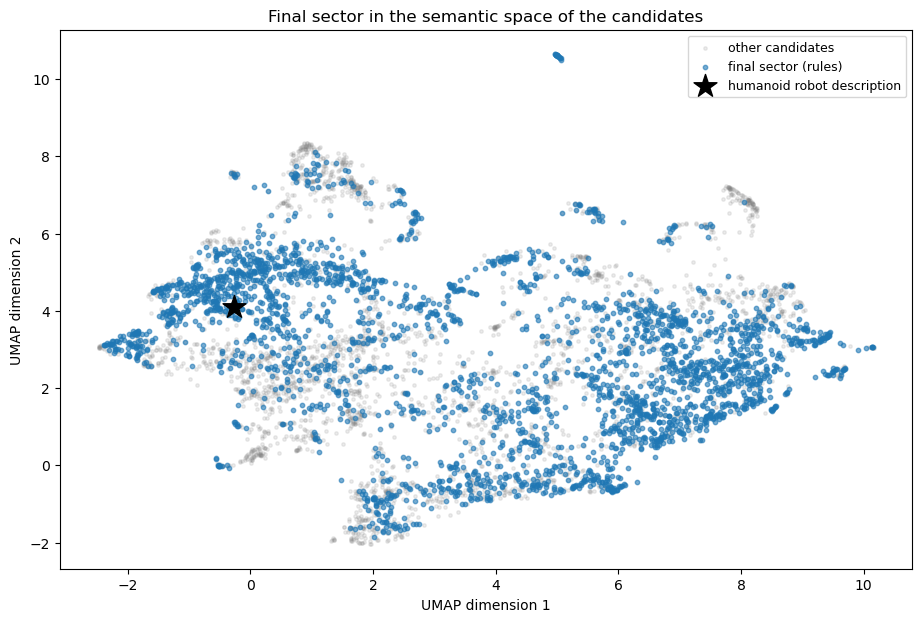

In [65]:
plot_map(candidates, "in_sector_FINAL", "final sector (rules)", "Final sector in the semantic space of the candidates")

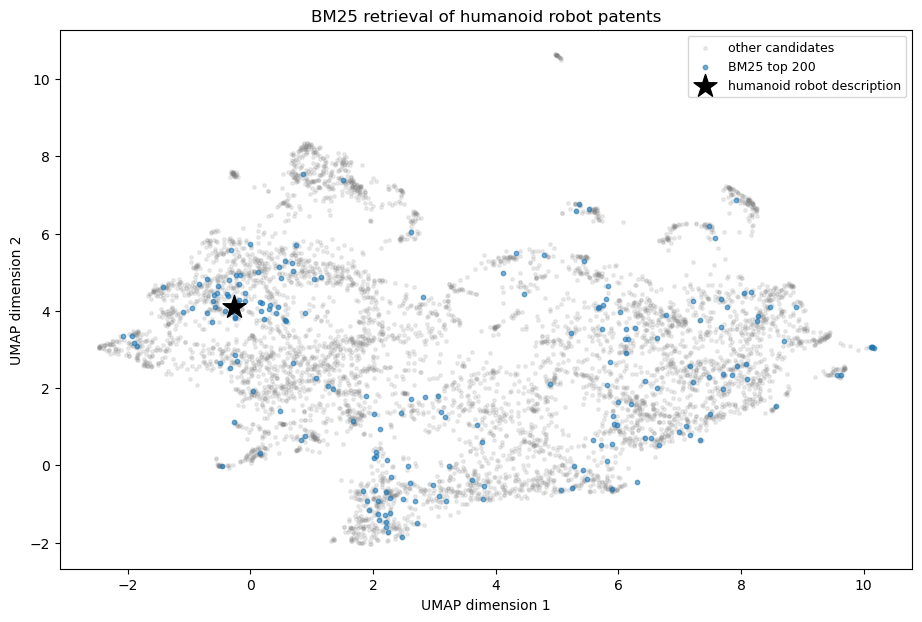

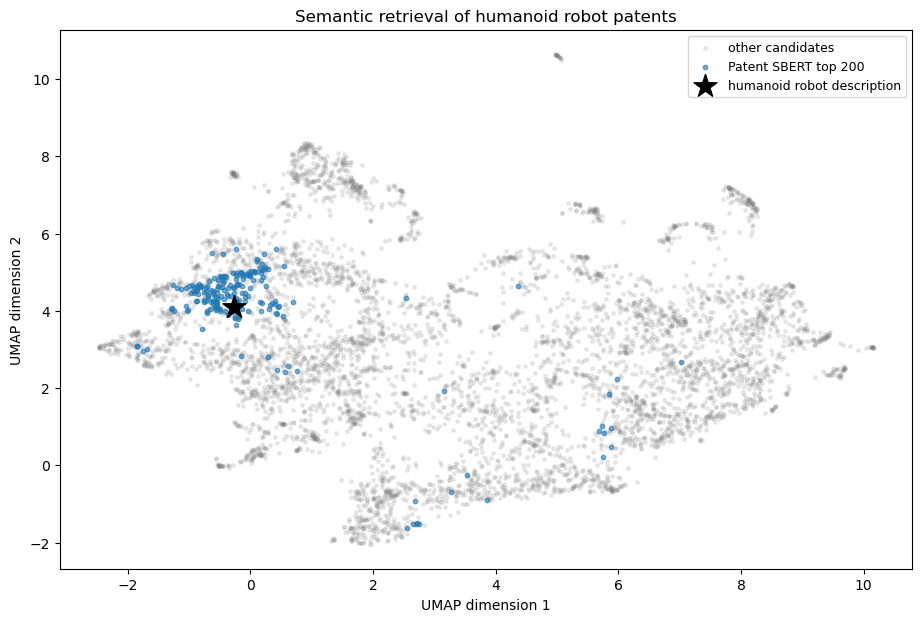

In [66]:
plot_map(candidates, "in_bm25_top", f"BM25 top {k}", "BM25 retrieval of humanoid robot patents")
plot_map(candidates, "in_sbert_top", f"Patent SBERT top {k}", "Semantic retrieval of humanoid robot patents")

### 6.8 Which humanoids do the rules miss? (check after Section 6)

The labelled families let us see which humanoid families the final rules leave out. They are lost more often in 2000–2009, so the growth of the sector is partly overstated. We tested one extension (block W) with a rule and a threshold fixed before reading 40 new families: it was not accepted (16/40). The final sector does not change.

In [67]:
# Which humanoid families do the rules miss? Families the team labelled humanoid (strict) but outside the final sector.
# The labels come from stratified samples, so this shows the kind of families missed, not the recall.
humanoid_read = candidates[candidates["label_strict"] == 1]
missed = humanoid_read[~humanoid_read["in_sector_FINAL"]]
print(f"labelled humanoid: {len(humanoid_read)} | outside the final sector: {len(missed)}")

period = pd.cut(candidates["year"], [1999, 2009, 2016, 2022, 2025], labels=["2000-09", "2010-16", "2017-22", "2023-25"])
print(pd.DataFrame({"missed humanoid": period[missed.index].value_counts(),
                    "kept humanoid": period[humanoid_read[humanoid_read["in_sector_FINAL"]].index].value_counts()}).sort_index())

# Title wordings that may describe a humanoid without the words our rule requires:
# PI families of the net outside the final sector, by period.
outside = sector[sector["is_pi"] & ~sector["in_sector_FINAL"]]
outside_period = pd.cut(outside["year"], [1999, 2009, 2016, 2022, 2025], labels=["2000-09", "2010-16", "2017-22", "2023-25"])
wordings = {"legged": r"\blegged\b", "walking robot": r"\bwalking robot", "leg type": r"\blegs? type\b",
            "two legs": r"\btwo legs\b", "biped (any)": r"\bbiped"}
print(pd.DataFrame({name: outside["title_text"].str.contains(p, case=False, regex=True, na=False).groupby(outside_period).sum()
                    for name, p in wordings.items()}))
missed[["docdb_family_id", "year", "appln_title"]].sort_values("year")

labelled humanoid: 187 | outside the final sector: 53
         missed humanoid  kept humanoid
year                                   
2000-09               15             13
2010-16                7             20
2017-22               11             28
2023-25               20             73
         legged  walking robot  leg type  two legs  biped (any)
year                                                           
2000-09     158            155        47         1           68
2010-16     140            210        24         3           61
2017-22     335            370        40         2           47
2023-25     210            152        31         0           21


/tmp/ipykernel_954/1031076222.py:17: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(pd.DataFrame({name: outside["title_text"].str.contains(p, case=False, regex=True, na=False).groupby(outside_period).sum()


,docdb_family_id,year,appln_title
96,27603225,2001,VOICE RESPONSE ROBOT
139,32265755,2002,STEERING-MECHANISM OF BIPEDAL LOCOMOTION
447,39721329,2007,"GAIT GENERATING DEVICE, WALKING BODY DEVICE HAVING SAME, AND GAIT GENERATING METHOD"
483,40220902,2007,Statically stable biped robotic mechanism and method of actuating
511,40588945,2007,ROBOT
589,41330802,2007,THE ATM WHERE THE ROBOT IS ESTABLISHED AND THE FINANCIAL TRANSACTIONS METHOD WHICH IT USES
518,40614010,2008,Modular six freedom-degree initiative joint type bipod walking robot
503,40536571,2008,Foot shock absorption mechanims of human imitating robot
536,40725942,2008,Motion programming method and apparatus for preventing human imitating robert from leaning one way or another
561,41067819,2008,"APPARATUS, METHOD AND PROGRAM FOR ROBOT CONTROL"


In [68]:
# Fixed BEFORE reading any new family. Suggested by the 53 humanoid families the rules left out (Section 6 check),
# so it is tested only on a new sample of families never read before.
BIPED_ANYWHERE = re.compile(r"(?<![a-z0-9])(?:biped|bipedal|bipeds)(?![a-z0-9])|二足|双足|雙足")
HUMAN_FORM_WIDE = re.compile(
    r"(?<![a-z0-9])(?:humanoid|anthropomorphic|human-like|humanlike|human-shaped|human shaped|"
    r"human-imitating|human imitating|humanoid-type)"
    r"\s+(?:[a-z0-9-]+\s+){0,2}(?:robots?|robotic)(?![a-z0-9])")
# Only "humanoid intelligent control" is a control-theory method; "humanoid intelligent robot" is a robot.
OTHER_SENSE_V4 = re.compile(r"(?<![a-z0-9])humanoid intelligen(?:t|ce) control")

w_biped = sector["title_text"].str.contains(BIPED_ANYWHERE)
w_wide = sector["title_text"].str.contains(HUMAN_FORM_WIDE)
w_sense = sector["term_robot_title"] & sector["other_sense"] & ~sector["title_text"].str.contains(OTHER_SENSE_V4)
sector["block_W"] = (sector["is_pi"] & (sector["excluded"] == "") & ~sector["in_sector_FINAL"]
                     & (w_biped | w_wide | w_sense) & ~sector["part_only"]
                     & ~sector["title_text"].str.contains(OTHER_SENSE_V4))

w = sector[sector["block_W"]]
print(f"final sector: {sector['in_sector_FINAL'].sum():,} families | extension block W: {len(w):,} families")
print(f"  'biped' anywhere in the title: {int(w_biped[w.index].sum())}")
print(f"  humanoid term up to two words before 'robot/robotic': {int(w_wide[w.index].sum())}")
print(f"  'humanoid intelligent robot' wrongly excluded before: {int(w_sense[w.index].sum())}")
w_period = pd.cut(w["year"], [1999, 2009, 2016, 2022, 2025], labels=["2000-09", "2010-16", "2017-22", "2023-25"])
print("\nblock W by period:")
print(w_period.value_counts(sort=False).to_string())

# Families already read that fall in W. OPTIMISTIC: these labels suggested the rule, so they cannot validate it.
read_ids = set(all_labels["docdb_family_id"])
in_w = all_labels[all_labels["docdb_family_id"].isin(set(w["docdb_family_id"]))]
print(f"\nfamilies already read in W: {len(in_w)} (humanoid: {int(in_w['label_strict'].sum())}) - optimistic, not a test")

# Fifth sample: 40 new families of block W, never read before (seed 41). Read blind, title AND abstract.
SEED_W = 41
pool_w = w[~w["docdb_family_id"].isin(read_ids)]
sample_w = pool_w.sample(n=min(40, len(pool_w)), random_state=SEED_W).reset_index(drop=True)
sample_w["sample_id"] = [f"W{i:03d}" for i in range(1, len(sample_w) + 1)]
print(f"fifth sample: {len(sample_w)} families, none read before: {not sample_w['docdb_family_id'].isin(read_ids).any()}")
sheet_w = write_reading_sheet(sample_w, "12_reading_sheet_W", "Step 0 · fifth reading sheet (read title AND abstract)")

final sector: 2,907 families | extension block W: 228 families
  'biped' anywhere in the title: 157
  humanoid term up to two words before 'robot/robotic': 72
  'humanoid intelligent robot' wrongly excluded before: 9

block W by period:
year
2000-09    59
2010-16    59
2017-22    67
2023-25    43

families already read in W: 9 (humanoid: 6) - optimistic, not a test
fifth sample: 40 families, none read before: True
saved 12_reading_sheet_W.csv and 12_reading_sheet_W.html (40 families)


In [69]:
labels_w = pd.read_csv(OUT_DIR / "12_reading_sheet_W_labelled.csv", dtype={"sample_id": str})
assert set(labels_w["docdb_family_id"]) == set(sample_w["docdb_family_id"]), "the labels must match the fifth sample"

kw, bw, nw = int(labels_w["label_strict"].sum()), int(labels_w["label_broad"].sum()), len(labels_w)
lo_w, hi_w = wilson(kw, nw)
w_ok = kw >= 36                                   # threshold fixed before the reading: at least 36 of 40
print(f"block W, fifth sample: strict {kw}/{nw} = {kw / nw:.1%} (95% CI {lo_w:.1%}-{hi_w:.1%}) | broad {bw}/{nw} = {bw / nw:.1%}")
print(f"decision (threshold 36/40 fixed before reading): {'ACCEPTED' if w_ok else 'NOT ACCEPTED'}")

# Description by wording, AFTER seeing the labels: it explains the result, it does not validate any sub-rule.
lw = labels_w.merge(sector[["docdb_family_id", "title_text"]], on="docdb_family_id")
human_wording = lw["title_text"].str.contains(HUMAN_FORM_WIDE) | lw["title_text"].str.contains(TERM_ROBOT)
lw["wording"] = np.where(human_wording, "humanoid wording", "'biped' only")
print("\nby wording (post hoc, description only):")
print(lw.groupby("wording")["label_strict"].agg(families="size", humanoid="sum").assign(
    share=lambda d: (d["humanoid"] / d["families"]).round(3)).to_string())

sector["in_sector_FINAL"] = sector["in_sector_final_v3"] | (sector["block_R"] if r_ok else False) | (sector["block_W"] if w_ok else False)
print(f"\nfinal sector: {sector['in_sector_FINAL'].sum():,} families (unchanged unless block W was accepted)")

block W, fifth sample: strict 16/40 = 40.0% (95% CI 26.3%-55.4%) | broad 27/40 = 67.5%
decision (threshold 36/40 fixed before reading): NOT ACCEPTED

by wording (post hoc, description only):
                  families  humanoid  share
wording                                    
'biped' only            26         4  0.154
humanoid wording        14        12  0.857

final sector: 2,907 families (unchanged unless block W was accepted)


In [70]:
def attempt(version, families, test, k, n, decision):
    """One row of the attempts table: precision (strict) on the sample that tested the version, with its Wilson CI."""
    lo_, hi_ = wilson(k, n)
    return {"version": version, "families": int(families), "test": test, "read": n, "humanoid (strict)": k,
            "precision": round(k / n, 3) if n else np.nan, "CI low": round(lo_, 3), "CI high": round(hi_, 3), "decision": decision}

p_ad, ci_ad, _ = weighted_share("precision", "label_strict")
n_ad = int((labels["purpose"] == "precision").sum())
attempts = pd.DataFrame([
    {"version": "blocks A-D", "families": int(sector["in_sector"].sum()), "test": "first sample (4 strata, size-weighted)",
     "read": n_ad, "humanoid (strict)": np.nan, "precision": round(p_ad, 3), "CI low": round(ci_ad[0], 3),
     "CI high": round(ci_ad[1], 3), "decision": "not accepted (size-weighted precision < 90%)"},
    attempt("block A", sector["in_sector_final"].sum(), "first + second samples",
            int(read_a["label_strict"].sum()), len(read_a), "replaced by version 3"),
    attempt("block A tightened (part / other sense)", sector["in_sector_final_v2"].sum(), "third sample",
            int(labels_a3["label_strict"].sum()), len(labels_a3), "not accepted (< 90%)"),
    attempt("version 3 (humanoid term names the robot in the title)", sector["in_sector_final_v3"].sum(), "fourth sample",
            k4, n4, "ACCEPTED: final sector"),
    attempt("recovery block R (first sentence of the abstract)", sector["block_R"].sum(), "R sample",
            kr, nr, "not accepted (< 90%)"),
    attempt("extension block W ('biped', wider humanoid wording)", sector["block_W"].sum(), "fifth sample",
            kw, nw, "not accepted (< 36/40)"),
])
attempts.to_csv(OUT_DIR / "12_all_attempts.csv", index=False)
print(attempts.to_string(index=False))

# Humanoid families read by the team that the final rules leave out, by period. Step 1 uses it to qualify the trend.
# Stratified samples: the shares describe where the rules lose humanoids, they are not recall estimates.
lost = pd.DataFrame({"humanoid read": period[humanoid_read.index].value_counts(),
                     "outside the final sector": period[missed.index].value_counts()}).sort_index()
lost["share lost"] = (lost["outside the final sector"] / lost["humanoid read"]).round(3)
lost.to_csv(OUT_DIR / "12_humanoids_lost_by_period.csv")
print("\n", lost.to_string())
print("\nsaved 12_all_attempts.csv and 12_humanoids_lost_by_period.csv")

                                               version  families                                   test  read  humanoid (strict)  precision  CI low  CI high                                     decision
                                            blocks A-D      5808 first sample (4 strata, size-weighted)   115                NaN      0.622   0.562    0.675 not accepted (size-weighted precision < 90%)
                                               block A      3572                 first + second samples    80               71.0      0.887   0.800    0.940                        replaced by version 3
                block A tightened (part / other sense)      3298                           third sample    40               35.0      0.875   0.739    0.945                         not accepted (< 90%)
version 3 (humanoid term names the robot in the title)      2907                          fourth sample    40               37.0      0.925   0.801    0.974                       ACCEPTED: fin

Two extensions of the sector were tested on new samples and rejected: block R (27/40) and block W (16/40). The rules lose more humanoid families in 2000–2009 than later (see 6.8), so the growth of the sector is partly overstated; Step 1 reports it.

# 7. Outputs for Step 1

Step 1 reads the sector from tables saved here, so that the two notebooks always describe the same families. We save the same tables, with the same names and columns, as the team's Step 0, computed on our final sector (2,907 patent-of-invention families): in this way the team's Step 1 can run on either definition of the sector. The tables go to a separate folder (`data/<ENV>/humanoid_robots_v2`), so nothing of the team's Step 0 is overwritten.

| Table | One row per | Used in Step 1 for |
|---|---|---|
| `families` | family | volume, PCT, offices of the family |
| `applications` | application (PI) | filing offices, grants, the example family |
| `family_cpc` | family × CPC symbol | CPC subclass mix |
| `family_wipo` | family × WIPO field (weights sum to 1) | technology fields |
| `family_inventors` | family × inventor country (weights sum to 1) | inventor countries |
| `family_applicants` | family × applicant (weights sum to 1) | applicant countries and types |
| `baseline_year` | priority year | all PI families of PATSTAT: growth and share of the sector |
| `baseline_b25j_year` | priority year | PI families with a B25J code: the robotics benchmark |
| `baseline_office` | IP5 office × filing year | weight of the sector inside each office |
| family_ipc | family × IPC symbol | technology mix, for the families without CPC |.

In [71]:
from epo.tipdata.patstat.database.models import (
    TLS206_PERSON,              # persons: name, country, sector (company, university...)
    TLS207_PERS_APPLN,          # who is applicant or inventor of which application
    TLS230_APPLN_TECHN_FIELD,   # WIPO technology field of each application, with a weight
    TLS901_TECHN_FIELD_IPC,     # names of the 35 WIPO fields and of the 5 technology sectors
)

# Same tables, names and columns that Step 1 (merged) reads, computed on OUR final sector.
# A separate folder, so that the tables of the team's Step 0 are never overwritten.
DATA_DIR = Path("data") / ENV / "humanoid_robots_v2"
DATA_DIR.mkdir(parents=True, exist_ok=True)
IP5_OFFICES = ["EP", "US", "CN", "JP", "KR"]

final = sector[sector["in_sector_FINAL"]]
SECTOR_IDS = sorted(int(f) for f in final["docdb_family_id"])


def sector_query(q):
    """Applications of the final sector only: real applications, patents of invention (as the sector).
    The 2,907 family ids travel as one array parameter (no dependence on the net subquery)."""
    return q.filter(
        TLS201_APPLN.docdb_family_id.in_(SECTOR_IDS),
        TLS201_APPLN.appln_id < DUMMY_ID_FROM,
        TLS201_APPLN.ipr_type == "PI",
    )
t0 = time.time()
sector_apps = patstat.df(sector_query(db.query(
    TLS201_APPLN.docdb_family_id, TLS201_APPLN.appln_id, TLS201_APPLN.appln_auth, TLS201_APPLN.appln_kind,
    TLS201_APPLN.appln_filing_date, TLS201_APPLN.appln_filing_year, TLS201_APPLN.earliest_filing_year,
    TLS201_APPLN.granted, TLS201_APPLN.docdb_family_size)))
sector_persons = patstat.df(sector_query(db.query(
    TLS201_APPLN.docdb_family_id, TLS207_PERS_APPLN.applt_seq_nr, TLS207_PERS_APPLN.invt_seq_nr,
    TLS206_PERSON.person_name, TLS206_PERSON.psn_name, TLS206_PERSON.person_ctry_code, TLS206_PERSON.psn_sector)
    .join(TLS207_PERS_APPLN, TLS201_APPLN.appln_id == TLS207_PERS_APPLN.appln_id)
    .join(TLS206_PERSON, TLS207_PERS_APPLN.person_id == TLS206_PERSON.person_id)))
sector_fields = patstat.df(sector_query(db.query(
    TLS201_APPLN.docdb_family_id, TLS230_APPLN_TECHN_FIELD.techn_field_nr, TLS230_APPLN_TECHN_FIELD.weight)
    .join(TLS230_APPLN_TECHN_FIELD, TLS201_APPLN.appln_id == TLS230_APPLN_TECHN_FIELD.appln_id)))
field_names = patstat.df(db.query(TLS901_TECHN_FIELD_IPC.techn_field_nr, TLS901_TECHN_FIELD_IPC.techn_sector,
                                  TLS901_TECHN_FIELD_IPC.techn_field).distinct())
print(f"sector: {len(SECTOR_IDS):,} families | applications {len(sector_apps):,}, person links {len(sector_persons):,}, "
      f"field rows {len(sector_fields):,} ({time.time() - t0:.0f} s)")

sector: 2,907 families | applications 3,714, person links 17,890, field rows 5,233 (3 s)


In [72]:
# All PATSTAT families of the same type of right (PI), dated by their earliest priority year.
# These queries scan the whole of PATSTAT: about a minute each on PROD.
pi_real = (TLS201_APPLN.ipr_type == "PI", TLS201_APPLN.appln_id < DUMMY_ID_FROM)
family_year = (db.query(TLS201_APPLN.docdb_family_id.label("fam"),
                        func.min(TLS201_APPLN.earliest_filing_year).label("priority_year"))
               .filter(*pi_real).group_by(TLS201_APPLN.docdb_family_id).subquery())


def families_per_year(subq):
    """Number of families per priority year in the window, for a subquery with columns fam and priority_year."""
    return patstat.df(db.query(subq.c.priority_year, func.count().label("families"))
                      .filter(subq.c.priority_year.between(YEAR_MIN, YEAR_MAX))
                      .group_by(subq.c.priority_year).order_by(subq.c.priority_year))


t0 = time.time()
baseline_year = families_per_year(family_year)

# Robotics benchmark: PI families with at least one B25J code (manipulators, the home class of robots).
# We use IPC, not CPC: every office classifies its applications in IPC, while CPC is missing on many older
# applications filed only in Asia, so a CPC count would inflate the growth of robotics. We print both to show it.
def b25j_families_per_year(code_table, symbol_column):
    fams = (db.query(TLS201_APPLN.docdb_family_id.label("fam"))
            .join(code_table, TLS201_APPLN.appln_id == code_table.appln_id)
            .filter(*pi_real, symbol_column.like("B25J%")).distinct().subquery())
    dated = (db.query(family_year.c.fam, family_year.c.priority_year)
             .join(fams, family_year.c.fam == fams.c.fam).subquery())
    return families_per_year(dated)


baseline_b25j_year = b25j_families_per_year(TLS209_APPLN_IPC, TLS209_APPLN_IPC.ipc_class_symbol)    # the benchmark
b25j_cpc_check = b25j_families_per_year(TLS224_APPLN_CPC, TLS224_APPLN_CPC.cpc_class_symbol)        # only to compare
b25j_compare = b25j_cpc_check.merge(baseline_b25j_year, on="priority_year", suffixes=(" (CPC)", " (IPC)"))
print("robotics families by priority year, CPC vs IPC:")
print(b25j_compare[b25j_compare["priority_year"].isin([2000, 2005, 2010, 2015, 2020, 2022])].to_string(index=False))

robotics families by priority year, CPC vs IPC:
 priority_year  families (CPC)  families (IPC)
          2000             472            1674
          2005             969            1928
          2010            1510            3230
          2015            3311            6750
          2020           14441           16158
          2022           13826           17475


In [73]:
# The office benchmark for Step 1 (Section 9): for each IP5 office and filing year, the number of PI families of the
# whole of PATSTAT with at least one application filed there. Same rule as the sector's office counts in Step 1.
t0 = time.time()
baseline_office = patstat.df(
    db.query(TLS201_APPLN.appln_auth.label("office"), TLS201_APPLN.appln_filing_year.label("filing_year"),
             func.count(TLS201_APPLN.docdb_family_id.distinct()).label("families"))
    .filter(TLS201_APPLN.ipr_type == "PI", TLS201_APPLN.appln_id < DUMMY_ID_FROM,
            TLS201_APPLN.appln_auth.in_(IP5_OFFICES),
            TLS201_APPLN.appln_filing_year.between(YEAR_MIN, YEAR_MAX))
    .group_by(TLS201_APPLN.appln_auth, TLS201_APPLN.appln_filing_year))
print(f"office benchmark: {len(baseline_office):,} office-year rows "
      f"(expected about {len(IP5_OFFICES) * (YEAR_MAX - YEAR_MIN + 1)}), {time.time() - t0:.0f} s")
baseline_office.pivot(index="filing_year", columns="office", values="families").tail(5)

office benchmark: 130 office-year rows (expected about 130), 0 s


office,CN,EP,JP,KR,US
filing_year,,,,,
2021,1608730,167810,253528,200185,426789
2022,1673107,170369,252105,193611,426145
2023,1759888,164711,255773,194495,396764
2024,1897150,134343,237928,191302,331438
2025,1755001,39563,67579,53640,238818


In [74]:
def most_common_country(s):
    """The most frequent non-empty country of a person across the applications of a family ('' if none)."""
    s = s[s != ""]
    return s.mode().iloc[0] if len(s) else ""


apps_ = sector_apps.copy()
apps_["appln_auth"] = apps_["appln_auth"].astype(str).str.strip()
apps_["granted"] = apps_["granted"].astype(str).str.strip()
national = apps_[apps_["appln_auth"] != "WO"]                     # the PCT application is not an office
fam = pd.DataFrame({"docdb_family_id": SECTOR_IDS})
fam["priority_year"] = fam["docdb_family_id"].map(final.set_index("docdb_family_id")["year"]).astype(int)
fam["has_pct"] = fam["docdb_family_id"].isin(set(apps_.loc[apps_["appln_auth"] == "WO", "docdb_family_id"]))
fam["n_applns"] = fam["docdb_family_id"].map(apps_.groupby("docdb_family_id")["appln_id"].nunique()).fillna(0).astype(int)
offices_of = national.groupby("docdb_family_id")["appln_auth"].agg(lambda s: ";".join(sorted(set(s))))
fam["jurisdictions"] = fam["docdb_family_id"].map(offices_of).fillna("")
fam["n_jurisdictions"] = fam["jurisdictions"].map(lambda j: len(j.split(";")) if j else 0)

# Codes: from the CPC download of Section 5 (blanks already removed). Y = tagging symbols (Y02, Y10...), not technologies.
family_cpc = cpc[cpc["docdb_family_id"].isin(SECTOR_IDS)].rename(columns={"code": "cpc_symbol"}).drop_duplicates()
family_cpc["subclass"] = family_cpc["cpc_symbol"].str[:4]
family_cpc["is_tagging"] = family_cpc["cpc_symbol"].str.startswith("Y")

# WIPO fields: the weights of the applications are summed by family and normalised, so every family sums to 1.
fw = sector_fields.groupby(["docdb_family_id", "techn_field_nr"], as_index=False)["weight"].sum()
fw["weight"] = fw["weight"] / fw.groupby("docdb_family_id")["weight"].transform("sum")
family_wipo = fw.merge(field_names, on="techn_field_nr", how="left")[
    ["docdb_family_id", "techn_field_nr", "techn_field", "techn_sector", "weight"]]

# Persons: one person per family and name (the same inventor appears once per application and office);
# the country is the most frequent known one across the family, because national records often leave it empty.
pp = sector_persons.copy()
pp["name"] = pp["psn_name"].fillna(pp["person_name"]).astype(str).str.strip().str.upper()
pp["ctry"] = pp["person_ctry_code"].fillna("").astype(str).str.strip()
pp["sector_type"] = pp["psn_sector"].fillna("").astype(str).str.strip().replace("", "UNKNOWN")

inv = (pp[pp["invt_seq_nr"] > 0].groupby(["docdb_family_id", "name"])["ctry"].agg(most_common_country).reset_index())
inv["inventor_country"] = inv["ctry"].replace("", "??")
family_inventors = (inv.groupby(["docdb_family_id", "inventor_country"]).size().rename("weight").reset_index())
family_inventors["weight"] = family_inventors["weight"] / family_inventors.groupby("docdb_family_id")["weight"].transform("sum")

app_ = pp[pp["applt_seq_nr"] > 0].groupby(["docdb_family_id", "name"]).agg(
    country=("ctry", most_common_country), applicant_type=("sector_type", lambda s: s.mode().iloc[0])).reset_index()
family_applicants = app_.rename(columns={"name": "applicant"})
family_applicants["weight"] = 1.0 / family_applicants.groupby("docdb_family_id")["applicant"].transform("size")

tables_out = {
    "families": fam,
    "applications": apps_[["docdb_family_id", "appln_id", "appln_auth", "appln_kind", "appln_filing_date",
                           "appln_filing_year", "earliest_filing_year", "granted", "docdb_family_size"]],
    "family_cpc": family_cpc[["docdb_family_id", "cpc_symbol", "subclass", "is_tagging"]],
    "family_wipo": family_wipo,
    "family_inventors": family_inventors,
    "family_applicants": family_applicants[["docdb_family_id", "applicant", "country", "applicant_type", "weight"]],
    "baseline_year": baseline_year,
    "baseline_b25j_year": baseline_b25j_year,
    "baseline_office": baseline_office,
}

# Checks before saving: every family is there, and every weight sums to 1 by family.
assert fam["n_applns"].gt(0).all(), "a family of the sector has no PI application in the download"
for name in ["family_wipo", "family_inventors", "family_applicants"]:
    sums = tables_out[name].groupby("docdb_family_id")["weight"].sum()
    assert np.allclose(sums, 1), f"{name}: the weights of a family do not sum to 1"

for name, df in tables_out.items():
    try:
        df.to_parquet(DATA_DIR / f"{name}.parquet", index=False)
    except ImportError:                       # pyarrow missing: pickle, which Step 1 also reads
        df.to_pickle(DATA_DIR / f"{name}.pkl")
    print(f"saved {name:20s} {len(df):>9,} rows")

meta = {"sector": "Humanoid robots", "client": "Electrolux", "env": ENV, "window": [YEAR_MIN, YEAR_MAX],
        "last_complete_year": LAST_COMPLETE_YEAR, "ipr_type": "PI", "families": len(SECTOR_IDS),
        "precision_strict": f"{k4}/{n4}", "definition": "Step 0 v2, version 3 (humanoid term names the robot in the title)"}
(DATA_DIR / "dataset_metadata.json").write_text(json.dumps(meta, indent=2))
print(f"\nsaved dataset_metadata.json in {DATA_DIR}")
print(f"families with a known applicant country: {family_applicants.loc[family_applicants['country'] != '', 'docdb_family_id'].nunique() / len(fam):.1%}"
      f" | with a WIPO field: {family_wipo['docdb_family_id'].nunique() / len(fam):.1%}"
      f" | via PCT: {fam['has_pct'].mean():.1%} | filed in >= 2 offices: {(fam['n_jurisdictions'] >= 2).mean():.1%}")

saved families                 2,907 rows
saved applications             3,714 rows
saved family_cpc               7,251 rows
saved family_wipo              4,091 rows
saved family_inventors         3,057 rows
saved family_applicants        3,432 rows
saved baseline_year               26 rows
saved baseline_b25j_year          26 rows
saved baseline_office            130 rows

saved dataset_metadata.json in data/PROD/humanoid_robots_v2
families with a known applicant country: 16.6% | with a WIPO field: 99.8% | via PCT: 5.9% | filed in >= 2 offices: 6.1%


In [75]:
# IPC subclasses of the sector, saved for Step 1: the families without CPC (about half of those of 2000-2016,
# mostly filed only in Asia) take their IPC subclasses in the technology mix (Step 1, Section 8).
ipc_codes = pd.read_csv(OUT_DIR / "02_net_ipc.csv.gz")
family_ipc = (ipc_codes[ipc_codes["docdb_family_id"].isin(SECTOR_IDS)]
              .rename(columns={"code": "ipc_symbol"}).drop_duplicates())
family_ipc["subclass"] = family_ipc["ipc_symbol"].astype(str).str[:4]
try:
    family_ipc.to_parquet(DATA_DIR / "family_ipc.parquet", index=False)
except ImportError:
    family_ipc.to_pickle(DATA_DIR / "family_ipc.pkl")
print(f"saved family_ipc: {len(family_ipc):,} rows, {family_ipc['docdb_family_id'].nunique():,} families")

saved family_ipc: 8,162 rows, 2,902 families


In [76]:
# All the families read by the team that are in the final sector. Only the fourth sample (V) is an independent test:
# the earlier labels helped to choose the rules, so the "all labels" columns are optimistic. Descriptive, wide intervals.
read_in = (all_labels.merge(sector.loc[sector["in_sector_FINAL"], ["docdb_family_id", "year", "offices"]], on="docdb_family_id")
           .assign(independent=lambda d: d["docdb_family_id"].isin(set(labels_a4["docdb_family_id"]))))
read_in["period"] = pd.cut(read_in["year"], [1999, 2009, 2016, 2022, 2025], labels=["2000-09", "2010-16", "2017-22", "2023-25"])
offices_set = read_in["offices"].fillna("").str.split("|").map(lambda o: set(o) - {"WO", ""})
read_in["office group"] = np.select([offices_set.map(lambda o: o == {"CN"}), offices_set.map(lambda o: "CN" in o)],
                                    ["CN only", "CN and abroad"], default="no CN")


def precision_by(col):
    """Strict precision by group: on all the labels in the sector (optimistic) and on the independent sample only."""
    rows = []
    for g, d in read_in.groupby(col, observed=True):
        k, n = int(d["label_strict"].sum()), len(d)
        lo_, hi_ = wilson(k, n)
        di = d[d["independent"]]
        rows.append({col: g, "read": n, "humanoid": k, "precision": f"{k / n:.0%}", "95% CI": f"{lo_:.0%}-{hi_:.0%}",
                     "independent sample": f"{int(di['label_strict'].sum())}/{len(di)}"})
    return pd.DataFrame(rows).set_index(col)


print(f"families of the final sector read by the team: {len(read_in)} (independent sample: {int(read_in['independent'].sum())})\n")
by_period, by_office = precision_by("period"), precision_by("office group")
print(by_period.to_string(), "\n")
print(by_office.to_string())
pd.concat({"period": by_period, "office group": by_office}).to_csv(OUT_DIR / "12_precision_by_period_office.csv")
print("\nsaved 12_precision_by_period_office.csv")

families of the final sector read by the team: 141 (independent sample: 40)

         read  humanoid precision    95% CI independent sample
period                                                        
2000-09    16        13       81%   57%-93%                3/3
2010-16    21        20       95%   77%-99%                7/8
2017-22    30        28       93%   79%-98%               8/10
2023-25    74        73       99%  93%-100%              19/19 

               read  humanoid precision   95% CI independent sample
office group                                                       
CN and abroad    10         8       80%  49%-94%                2/2
CN only         100        96       96%  90%-98%              25/28
no CN            31        30       97%  84%-99%              10/10

saved 12_precision_by_period_office.csv


outcome
not humanoid, left out                          197
humanoid, in the sector                         134
humanoid, left out (missed)                      53
not humanoid, in the sector (false positive)      7 



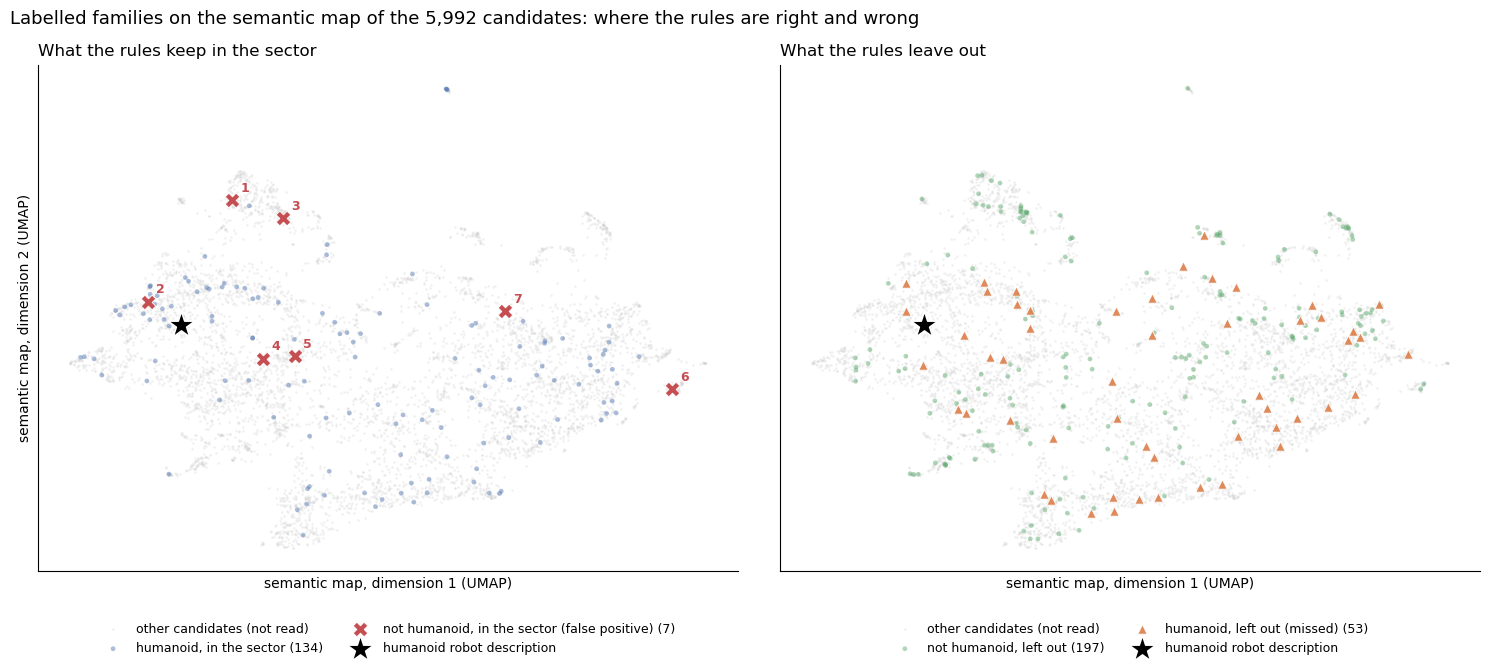

false positives of the final sector among the families read: 7 (of which in the independent sample: 3)


,map id,docdb_family_id,year,office group,independent,appln_title,sbert_similarity
0,1,75589514,2021,CN only,True,Humanoid parallel robot dexterous hand,0.886661
1,2,55184655,2015,CN only,True,Humanoid robot capable of fitting human torso shape,0.853585
2,3,41799463,2008,CN and abroad,False,ROBOT HAND AND HUMAN TYPE ROBOT EQUIPPED WITH ROBOT HAND,0.782922
3,4,38025945,2005,no CN,False,"MANIPULATOR, MULTI-FREEDOM-DEGREE MANIPULATOR HAVING THE MANIPULATOR, 6-FREEDOM-DEGREE MANIPULATOR, BIPEDAL ROBOT, MOTOR-DRIVEN SEAT DEVICE FOR VEHICLE, AND POSITION ANGLE SENSOR",0.738538
4,5,38684517,2006,CN and abroad,False,CONNECTION MECHANISM OF COUPLING MEMBER FOR ROBOT AND WALKING TYPE ROBOT,0.719583
5,6,67960393,2019,CN only,True,Method for achieving teaching function of mechanical arm based on instruction of PLC humanoid robot,0.613539
6,7,93156843,2024,CN only,False,Simulated meat high polymer material for humanoid robot,0.544722


In [77]:
# Four groups of labelled families: humanoid in the sector (true positive), not humanoid in the sector (false positive),
# humanoid outside (missed), not humanoid outside (correctly left out). Families without an English abstract are not on the map.
lab = candidates[candidates["label_strict"].notna()].copy()
lab["outcome"] = np.select(
    [lab["in_sector_FINAL"] & (lab["label_strict"] == 1), lab["in_sector_FINAL"] & (lab["label_strict"] == 0),
     ~lab["in_sector_FINAL"] & (lab["label_strict"] == 1)],
    ["humanoid, in the sector", "not humanoid, in the sector (false positive)", "humanoid, left out (missed)"],
    default="not humanoid, left out")
print(lab["outcome"].value_counts().to_string(), "\n")

# The false positives of the final sector, one by one, numbered as on the map (independent = from the fourth sample).
fp = (lab[lab["outcome"].str.contains("false positive")]
      .merge(read_in[["docdb_family_id", "independent", "office group"]], on="docdb_family_id", how="left")
      .sort_values("sbert_similarity", ascending=False).reset_index(drop=True))
fp.insert(0, "map id", range(1, len(fp) + 1))

# Two panels with the same axes: left, what the rules KEEP (right vs wrong); right, what the rules LEAVE OUT.
# Correct decisions are small and light, errors are large and dark, so the eye goes to the errors.
panels = [
    ("What the rules keep in the sector",
     [("humanoid, in the sector", "o", "#4C72B0", 12, 0.45), ("not humanoid, in the sector (false positive)", "X", "#C44E52", 110, 1.0)]),
    ("What the rules leave out",
     [("not humanoid, left out", "o", "#55A868", 12, 0.45), ("humanoid, left out (missed)", "^", "#DD8452", 45, 0.95)]),
]
fig, axes = plt.subplots(1, 2, figsize=(15, 6.8), sharex=True, sharey=True)
for ax, (title, groups) in zip(axes, panels):
    ax.scatter(candidates["UMAP_1"], candidates["UMAP_2"], s=3, color="lightgrey", alpha=0.35, linewidths=0,
               label="other candidates (not read)", zorder=1)
    for outcome, marker, colour, size, alpha in groups:
        d = lab[lab["outcome"] == outcome]
        ax.scatter(d["UMAP_1"], d["UMAP_2"], marker=marker, s=size, color=colour, alpha=alpha,
                   edgecolor="white" if marker != "o" else "none", linewidth=0.6, label=f"{outcome} ({len(d)})", zorder=3)
    ax.scatter(*description_xy, marker="*", s=420, color="black", edgecolor="white", linewidth=1.2,
               label="humanoid robot description", zorder=4)
    ax.set_title(title, fontsize=12, loc="left")
    ax.set(xticks=[], yticks=[], xlabel="semantic map, dimension 1 (UMAP)")
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=2, fontsize=9, frameon=False)
axes[0].set_ylabel("semantic map, dimension 2 (UMAP)")
for _, r in fp.iterrows():          # number each false positive, as in the table below
    axes[0].annotate(str(r["map id"]), (r["UMAP_1"], r["UMAP_2"]), xytext=(6, 6), textcoords="offset points",
                     fontsize=9, fontweight="bold", color="#C44E52", zorder=5)
fig.suptitle(f"Labelled families on the semantic map of the {len(candidates):,} candidates: "
             "where the rules are right and wrong", fontsize=13, x=0.01, ha="left")
plt.tight_layout()
fig.savefig(OUT_DIR / "13_errors_on_map.png", dpi=200, bbox_inches="tight")   # for the technical appendix
plt.show()

fp = fp[["map id", "docdb_family_id", "year", "office group", "independent", "appln_title", "sbert_similarity"]]
fp.to_csv(OUT_DIR / "13_false_positives_final.csv", index=False)
print(f"false positives of the final sector among the families read: {len(fp)} "
      f"(of which in the independent sample: {int(fp['independent'].sum())})")
fp

### 7.2 Applicants: harmonizing the names

Before any ranking of applicants, the names must be harmonised: the same organisation appears in PATSTAT under many spellings, and a firm split into many names makes every concentration measure wrong. We build four definitions of "applicant", from the finest to the coarsest, and measure each one on the gold standard of the course (Tutorial 1): A, the name of PATSTAT with the legal forms removed (the prof's method A); B, cleanco and an extended list of legal forms (`applicant_norm`); C, our main version, a brand key with a few certain aliases (`applicant`); D, a coarse key that merges too much on purpose (`applicant_auto`), used only as a sensitivity check in Step 2.

In [78]:
%pip install -q cleanco

import re
import unicodedata
from math import comb
from cleanco import basename

# Legal forms and company words that do not identify the organisation (dictionary of the prof's method A, extended
# with the forms of the countries of our sector: China, Japan, Korea, Taiwan).
LEGAL_FORMS = {
    "INC", "INCORPORATED", "CORP", "CORPORATION", "CO", "COMPANY", "LTD", "LIMITED", "LLC", "LP", "PLC",
    "GMBH", "AG", "KG", "MBH", "SE", "SA", "SAS", "SPA", "SRL", "BV", "NV", "AB", "AS", "ASA", "OY", "OYJ",
    "KK", "KABUSHIKI", "KAISHA", "LTDA", "PTY", "THE", "AKTIENGESELLSCHAFT", "GESELLSCHAFT",
    "SARL", "SNC", "GIE", "EV", "UG", "COOP", "HOLDING", "HOLDINGS", "GROUP",
}


def clean_with_dictionary(name):
    "Prof's method A: upper-case, letters and digits only, legal-form words dropped at the start and at the end."
    words = re.sub(r"[^A-Z0-9 ]", " ", str(name).upper()).split()
    while words and words[-1] in LEGAL_FORMS:
        words.pop()
    while words and words[0] in LEGAL_FORMS:
        words.pop(0)
    return " ".join(words)


def normalise(name):
    "applicant_norm: cleanco first (abbreviations with dots, e.g. S.p.A.), then method A; non-Latin names kept as they are."
    s = unicodedata.normalize("NFKC", str(name)).strip()    # full-width letters (Ｓ) become plain letters (S)
    key = clean_with_dictionary(basename(s)) if s else ""
    return key if key else s.upper()


def pairs_inside(group_sizes):
    return sum(comb(int(n), 2) for n in group_sizes)


def precision_recall_f1(gold_groups, predicted_groups):
    "Pairwise precision, recall and F1 (the prof's function)."
    df = pd.DataFrame({"gold": list(gold_groups), "pred": list(predicted_groups)})
    tp = pairs_inside(df.groupby(["gold", "pred"]).size())
    tp_fp = pairs_inside(df.groupby("pred").size())
    tp_fn = pairs_inside(df.groupby("gold").size())
    precision = tp / tp_fp if tp_fp else 1.0
    recall = tp / tp_fn
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return {"groups found": df["pred"].nunique(), "precision": precision, "recall": recall, "F1": f1}


# ---------------------------------------------------------------- brand key (main version) and coarse key
# Chinese names start with the city or province ("SHENZHEN UBTECH ROBOTICS"): the place is skipped.
PLACES = {
    "BEIJING", "SHANGHAI", "SHENZHEN", "GUANGZHOU", "HANGZHOU", "TIANJIN", "CHONGQING", "NANJING", "SUZHOU", "WUHAN",
    "CHENGDU", "XIAN", "XI", "AN", "HEFEI", "JINAN", "QINGDAO", "DALIAN", "SHENYANG", "HARBIN", "CHANGSHA", "CHANGZHOU",
    "NINGBO", "XIAMEN", "FUZHOU", "ZHENGZHOU", "KUNMING", "NANCHANG", "TAIYUAN", "SHIJIAZHUANG", "WUXI", "DONGGUAN",
    "FOSHAN", "ZHUHAI", "WENZHOU", "JIAXING", "SHAOXING", "YANGZHOU", "XUZHOU", "NANTONG", "CHANGCHUN", "LANZHOU",
    "GUIYANG", "NANNING", "HAIKOU", "URUMQI", "HOHHOT", "YINCHUAN", "XINING", "LHASA", "TANGSHAN", "BAODING", "LUOYANG",
    "ZHEJIANG", "JIANGSU", "GUANGDONG", "SHANDONG", "HUBEI", "HUNAN", "HENAN", "HEBEI", "SICHUAN", "FUJIAN", "ANHUI",
    "JIANGXI", "SHAANXI", "SHANXI", "LIAONING", "JILIN", "HEILONGJIANG", "YUNNAN", "GUIZHOU", "GUANGXI", "HAINAN",
    "GANSU", "QINGHAI", "NINGXIA", "XINJIANG", "TIBET", "INNER", "MONGOLIA",
    "CHINA", "CHINESE", "JAPAN", "KOREA", "KOREAN", "TAIWAN", "HONG", "KONG", "SEOUL", "TOKYO", "OSAKA",
}
# A name whose distinctive word is generic needs one more word ("GENERAL ELECTRIC" is not "GENERAL MOTORS").
GENERIC = {
    "GENERAL", "INTERNATIONAL", "NATIONAL", "UNITED", "AMERICAN", "ADVANCED", "NEW", "FIRST", "GLOBAL", "SMART",
    "INTELLIGENT", "INTELLIGENCE", "ROBOT", "ROBOTS", "ROBOTIC", "ROBOTICS", "TECHNOLOGY", "TECHNOLOGIES", "TECH",
    "ELECTRIC", "ELECTRONIC", "ELECTRONICS", "INDUSTRIAL", "INDUSTRIES", "INDUSTRY", "SCIENCE", "SCIENCES", "DIGITAL",
    "AUTOMATION", "MACHINE", "MACHINERY", "POWER", "ENERGY", "MEDICAL", "DATA", "SYSTEMS", "SYSTEM", "STATE", "ROYAL",
    "INSTITUTE", "UNIVERSITY", "ACADEMY", "CENTRE", "CENTER", "RESEARCH", "LAB", "LABORATORY", "NORTH", "SOUTH",
    "EAST", "WEST", "NORTHWESTERN", "SOUTHEAST", "SOUTHWEST", "NORTHEAST", "NORTHEASTERN", "CENTRAL", "EUROPEAN",
    "DEUTSCHE", "ITALIANA", "FRANCAISE", "NIPPON", "INTERNATIONALE", "GENERALE", "NOUVELLE", "INDUSTRIE", "FOURIER",   # checked by hand: SHANGHAI FOURIER INTELLIGENT and FOURIER POWER (BEIJING) are two companies
}
# Universities, institutes, labs, hospitals keep their whole name (otherwise all "INSTITUTE ..." would merge).
INSTITUTION_WORDS = re.compile(r"\b(UNIV\w*|INST\w*|ACADEM\w*|COLLEGE|SCHOOL|HOSPITAL|LAB\w*|CENT(?:ER|RE)|"
                                  r"FRAUNHOFER|CNRS|CNR|CSIC|RIKEN|AIST|KIST|ETRI|KAIST|"
                                  r"DAXUE|XUEYUAN|YANJIUYUAN|YANJIUSUO)\b")      # university, college, institute in pinyin
# Words that open many European firm names without identifying them ("SOCIETE L'OREAL", "COMPAGNIE IBM").
LEADING_WORDS = {"SOCIETE", "SOCIETA", "SOCIEDAD", "COMPAGNIE", "COMPANIA", "COMPANHIA", "ETABLISSEMENTS", "ETS",
                 "FABBRICA", "FIRMA", "DITE", "SOC", "CIE", "STE", "ANONIMA", "ANONYME", "DE", "DES", "DU", "DI", "DELLA"}

# Explicit aliases: the same company under different names (renamed, or a Latin and a pinyin name).
# Only certain cases; probable ones are noted in Step 2 and NOT merged. Parent and subsidiary with different
# names stay apart (Boston Dynamics is not Google nor Hyundai): the applicant is the owner named on the patent.
ALIASES = {
    "YOUBIXUAN": "UBTECH",          # Youbixuan is the Chinese name of UBTECH Robotics
    "YUSHU": "UNITREE",             # Hangzhou Yushu Technology trades as Unitree (founded as Hangzhou Unitree Technology)
    "ALDEBARAN": "SOFTBANK",        # Aldebaran (Paris) was SoftBank Robotics Europe from 2016 to 2022: the same company
    "FOURIER INTELLIGENCE": "FOURIER INTELLIGENT",   # Fourier Intelligence is the English name of Shanghai Fourier Intelligent
}


def distinctive_words(norm):
    "The words of a firm name without the opening place names and opening legal words; initials joined."
    merged = []
    for w in str(norm).split():                       # F I L A -> FILA
        if len(w) == 1 and merged and merged[-1][1]:
            merged[-1] = (merged[-1][0] + w, True)
        else:
            merged.append((w, len(w) == 1))
    words = [w for w, _ in merged]
    while len(words) > 1 and (words[0] in PLACES or words[0] in LEADING_WORDS):
        words.pop(0)
    return words


def brand_key(norm, is_individual=False):
    """The brand of an organisation: the key that groups its spellings and its subsidiaries by name.
    Individuals and institutions keep their whole normalised name; for firms, the first word that is not a place,
    plus the next one if it is generic."""
    norm = str(norm)
    if is_individual or INSTITUTION_WORDS.search(norm):
        return norm
    words = distinctive_words(norm)
    if not words:
        return norm
    if len(words[0]) == 1 and len(words) > 1:          # "L OREAL" -> "LOREAL"
        return words[0] + words[1]
    return " ".join(words[:2]) if words[0] in GENERIC else words[0]


def applicant_key(norm, is_individual=False):
    "applicant (main version, C): the brand key, then the explicit aliases."
    key = brand_key(norm, is_individual)
    return ALIASES.get(key, key)


def coarse_key(norm, is_individual=False):
    "applicant_auto (D): for firms, the first distinctive word even when it is generic (merges too much on purpose)."
    norm = str(norm)
    if is_individual or INSTITUTION_WORDS.search(norm):
        return norm
    words = distinctive_words(norm)
    if not words:
        return norm
    key = "".join(words[:2]) if len(words[0]) == 1 and len(words) > 1 else words[0]
    return ALIASES.get(key, key)


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [79]:
# the gold standard of Tutorial 1: next to this notebook, or anywhere in the home folder (e.g. the prof's tutorial_1/)
GOLD_NAME = "PATSTAT_500_label_datav4.csv"
gold_path = Path(GOLD_NAME) if Path(GOLD_NAME).exists() else next(Path.home().rglob(GOLD_NAME), None)
assert gold_path is not None, f"{GOLD_NAME} not found: copy it from the prof's tutorial_1 folder next to this notebook"
print("gold standard read from:", gold_path)

gold = pd.read_csv(gold_path).rename(columns={"comp": "name", "Group": "gold_group"})
gold["norm"] = gold["name"].map(normalise)
gold_check = pd.DataFrame({
    "A. legal forms removed (prof's method A)": precision_recall_f1(gold["gold_group"], gold["name"].map(clean_with_dictionary)),
    "B. cleanco + extended legal forms (applicant_norm)": precision_recall_f1(gold["gold_group"], gold["norm"]),
    "C. brand key + aliases (applicant, main)": precision_recall_f1(gold["gold_group"], gold["norm"].map(applicant_key)),
    "D. coarse key (applicant_auto)": precision_recall_f1(gold["gold_group"], gold["norm"].map(coarse_key)),
}).T
gold_check.to_csv(OUT_DIR / "14_names_gold_standard.csv")
print(f"gold standard: {len(gold):,} names of {gold['gold_group'].nunique():,} organisations")
gold_check.round(3)

gold standard read from: ~/innovation-management-datascience26/tutorial_1/PATSTAT_500_label_datav4.csv
gold standard: 3,192 names of 481 organisations


,groups found,precision,recall,F1
A. legal forms removed (prof's method A),2981.0,0.992,0.003,0.005
B. cleanco + extended legal forms (applicant_norm),2955.0,0.993,0.003,0.006
"C. brand key + aliases (applicant, main)",647.0,0.964,0.876,0.918
D. coarse key (applicant_auto),640.0,0.964,0.876,0.918


In [80]:
from epo.tipdata.patstat.database.models import TLS228_DOCDB_FAM_CITN   # citations between DOCDB families

persons = patstat.df(sector_query(db.query(
    TLS201_APPLN.docdb_family_id, TLS206_PERSON.person_id, TLS206_PERSON.psn_id, TLS206_PERSON.han_id,
    TLS206_PERSON.han_name, TLS206_PERSON.psn_name, TLS206_PERSON.doc_std_name, TLS206_PERSON.person_name,
    TLS206_PERSON.person_ctry_code, TLS206_PERSON.psn_sector)
    .join(TLS207_PERS_APPLN, TLS201_APPLN.appln_id == TLS207_PERS_APPLN.appln_id)
    .join(TLS206_PERSON, TLS207_PERS_APPLN.person_id == TLS206_PERSON.person_id)
    .filter(TLS207_PERS_APPLN.applt_seq_nr > 0)).distinct())


def text(col):
    return persons[col].fillna("").astype(str).str.strip()


# 1. the best name of each person record: HAN if it was really harmonised, then PSN, then the name standardised
#    from the document, then the name as printed (name_source says which one)
han_ok = (persons["han_id"].fillna(0) > 0) & (text("han_name") != "")
persons["name_raw"] = np.select([han_ok, text("psn_name") != "", text("doc_std_name") != ""],
                                [text("han_name"), text("psn_name"), text("doc_std_name")], default=text("person_name"))
persons["name_source"] = np.select([han_ok, text("psn_name") != "", text("doc_std_name") != ""],
                                   ["HAN", "PSN", "doc_std_name"], default="person_name")
persons["country"] = text("person_ctry_code")
persons["applicant_type"] = text("psn_sector").replace("", "UNKNOWN")
individual = persons["applicant_type"].str.contains("INDIVIDUAL")

# 2. the definitions of applicant (A is name_raw itself)
persons["applicant_norm"] = persons["name_raw"].map(normalise)
persons["applicant"] = [applicant_key(n, i) for n, i in zip(persons["applicant_norm"], individual)]
persons["applicant_auto"] = [coarse_key(n, i) for n, i in zip(persons["applicant_norm"], individual)]


def mode_known(s):
    "The most frequent non-empty value ('' if none)."
    s = s[s != ""]
    return s.mode().iloc[0] if len(s) else ""

# readable labels for the deck: each applicant (and each coarse key) is shown with its most frequent full name
def readable(key_column):
    counts = persons.groupby([key_column, "applicant_norm"])["docdb_family_id"].nunique().reset_index()
    best = counts.sort_values("docdb_family_id", ascending=False).drop_duplicates(key_column)
    return persons[key_column].map(best.set_index(key_column)["applicant_norm"])


persons["applicant"] = readable("applicant")
persons["applicant_auto"] = readable("applicant_auto")

# one row per family and name (Step 2 counts the families under each definition from this table)
applicant_names = (persons.groupby(["docdb_family_id", "name_raw"])
                   .agg(name_source=("name_source", "first"), applicant_norm=("applicant_norm", "first"),
                        applicant=("applicant", "first"), applicant_auto=("applicant_auto", "first"),
                        country=("country", mode_known), applicant_type=("applicant_type", mode_known))
                   .reset_index())

# one row per family and applicant (main version), the table Step 2 uses; the weights sum to 1 by family
family_applicants_grouped = (applicant_names.groupby(["docdb_family_id", "applicant"])
                             .agg(country=("country", mode_known), applicant_type=("applicant_type", mode_known))
                             .reset_index())
family_applicants_grouped["weight"] = 1.0 / family_applicants_grouped.groupby("docdb_family_id")["applicant"].transform("size")

# 3. citations between DOCDB families, in both directions (Step 2 keeps those between families of the sector)
cit_back = patstat.df(db.query(TLS228_DOCDB_FAM_CITN.docdb_family_id.label("citing"),
                               TLS228_DOCDB_FAM_CITN.cited_docdb_family_id.label("cited"))
                      .filter(TLS228_DOCDB_FAM_CITN.docdb_family_id.in_(SECTOR_IDS)))
cit_fwd = patstat.df(db.query(TLS228_DOCDB_FAM_CITN.docdb_family_id.label("citing"),
                              TLS228_DOCDB_FAM_CITN.cited_docdb_family_id.label("cited"))
                     .filter(TLS228_DOCDB_FAM_CITN.cited_docdb_family_id.in_(SECTOR_IDS)))
family_citations = pd.concat([cit_back.assign(direction="backward"), cit_fwd.assign(direction="forward")],
                             ignore_index=True).drop_duplicates()

for name, df in {"applicant_names": applicant_names, "family_applicants_grouped": family_applicants_grouped,
                 "family_citations": family_citations}.items():
    try:
        df.to_parquet(DATA_DIR / f"{name}.parquet", index=False)
    except ImportError:
        df.to_pickle(DATA_DIR / f"{name}.pkl")
    print(f"saved {name:26s} {len(df):>8,} rows")

within = family_citations[family_citations["citing"].isin(SECTOR_IDS) & family_citations["cited"].isin(SECTOR_IDS)]
print(f"\nnames: {applicant_names['name_raw'].nunique():,} -> normalised {applicant_names['applicant_norm'].nunique():,}"
      f" -> applicants {applicant_names['applicant'].nunique():,} (coarse key {applicant_names['applicant_auto'].nunique():,})")
print("name source:", persons.drop_duplicates("person_id")["name_source"].value_counts().to_dict())
print(f"families with an applicant: {family_applicants_grouped['docdb_family_id'].nunique():,} of {len(SECTOR_IDS):,}")
print(f"citations between families of the sector: {within[['citing', 'cited']].drop_duplicates().shape[0]:,}")
top = family_applicants_grouped.groupby("applicant")["docdb_family_id"].nunique().nlargest(20)
spellings = applicant_names.groupby("applicant")["name_raw"].nunique()
pd.DataFrame({"families": top, "names merged": spellings.reindex(top.index)})

saved applicant_names               3,670 rows
saved family_applicants_grouped     3,409 rows
saved family_citations             28,856 rows

names: 1,412 -> normalised 1,308 -> applicants 1,239 (coarse key 1,235)
name source: {'HAN': 1656, 'PSN': 1}
families with an applicant: 2,895 of 2,907
citations between families of the sector: 2,750


,families,names merged
applicant,,
UBTECH ROBOTICS,94,5
GUANGZHOU LIGONG INDUSTRIAL,92,1
SHANGHAI FOURIER INTELLIGENT TECHNOLOGY,91,2
BEIJING INSTITUTE OF TECHNOLOGY,87,1
ZHEJIANG UNIVERSITY,67,2
SHENZHEN ZHUJI POWER TECHNOLOGY,59,1
HARBIN INSTITUTE OF TECHNOLOGY,50,2
ZHEJIANG LAB,46,1
FIGURE AI,44,3


In [81]:
%pip install -q numba sentence-transformers
import itertools
import subprocess
TERRORIZER_DIR = Path.home() / "Terrorizer"
if not TERRORIZER_DIR.exists():                          # the course's package, cloned once into the home folder
    subprocess.run(["git", "clone", "--depth", "1", "https://github.com/graziasveva/Terrorizer.git", str(TERRORIZER_DIR)], check=True)
from sentence_transformers import SentenceTransformer
NAME_MODEL = "Vsevolod/company-names-similarity-sentence-transformer"   # the encoder used by Terrorizer's NameVectorizer
name_model = SentenceTransformer(NAME_MODEL)


def encode_words(words):
    "Vector of each word with Terrorizer's company-name encoder."
    return name_model.encode(list(words), batch_size=256, show_progress_bar=False, convert_to_numpy=True)


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/2.35k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/720 [00:00<?, ?B/s]

... (6 outputs left out)

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/712k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

### 7.3 Terrorizer: the entity-linking method of the course

Terrorizer (github.com/graziasveva/Terrorizer) links names in four stages: cleaning; a vector for each name (the mean of the vectors of its words, from a sentence transformer trained on company names, weighted so that rare words count more than common ones); a network where two names are linked when a score, the cosine similarity plus a bonus for a word in common and for the same first word, passes a threshold; and community detection (Louvain) after removing the edges of "bridge" nodes. The package cannot be installed from PyPI, so we rebuild the four stages as they are written in its code, with its encoder and its bridgeness function. We do not use its knowledge base. The weights and thresholds are chosen on one half of the organisations of the gold standard and measured on the other half, where we also measure our brand key.

In [82]:
import sys
from collections import Counter

import networkx as nx
import numpy as np
from sklearn.feature_extraction.text import CountVectorizer

sys.path.insert(0, str(TERRORIZER_DIR))                 # the clone of github.com/graziasveva/Terrorizer
from bridges import bridgeness_centrality                # Terrorizer's own bridgeness (Morini et al.)


def term_weights(names):
    """Terrorizer's weight of each word (NameVectorizer.total_score): log(frequency) x idf, rescaled to [0, 1]
    and reversed, so that the words shared by many names (TECHNOLOGY, ROBOT) weigh less than rare ones (UBTECH)."""
    docs = [str(n).split() for n in names]
    df = Counter(w for d in docs for w in set(d))
    tf = Counter(w for d in docs for w in d)
    raw = {w: np.log(tf[w]) * np.log(len(docs) / df[w]) for w in tf}
    lo, hi = min(raw.values()), max(raw.values()) - 1e-4
    return {w: abs(1 - (v - lo) / (hi - lo)) if hi > lo else 1.0 for w, v in raw.items()}


def name_vectors(names, encode_words):
    """Terrorizer's vector of a name: the mean of the vectors of its words, each multiplied by its weight.
    encode_words(list of words) -> array (words x dimensions)."""
    weights = term_weights(names)
    vocab = sorted({w for n in names for w in str(n).split()})
    word_vec = dict(zip(vocab, encode_words(vocab)))
    dim = len(next(iter(word_vec.values())))
    out = np.zeros((len(names), dim), dtype="float32")
    for i, n in enumerate(names):
        words = str(n).split()
        if words:
            out[i] = np.mean([word_vec[w] * weights[w] for w in words], axis=0)
    norms = np.linalg.norm(out, axis=1, keepdims=True)
    return out / np.where(norms == 0, 1, norms)


def terrorizer_groups(names, vectors, w_sim=1.0, w_same=0.25, w_first=0.25, threshold=1.0,
                      resolution=1.0, bridgeness_threshold=0.1, seed=42, max_component=None):
    """Terrorizer's matching and network stages.
    score(i, j) = w_sim x cosine + w_same x (a word in common) + w_first x (same first word);
    pairs with score >= threshold are edges; the edges of the nodes with a high bridgeness (nodes that join two
    groups) are removed; Louvain community detection gives the groups. Returns one group id per name.
    max_component: if a connected component is larger, return None instead (used only in the grid search, where
    Terrorizer's bridgeness, written in plain Python, takes minutes on a component of a thousand names)."""
    names = [str(n) for n in names]
    tokens = CountVectorizer(tokenizer=str.split, lowercase=False, binary=True, token_pattern=None).fit_transform(names)
    shared = (tokens @ tokens.T).toarray() > 0                                    # at least one word in common
    first = np.array([n.split()[0] if n.split() else f"_{i}" for i, n in enumerate(names)])
    same_first = first[:, None] == first[None, :]
    score = w_sim * (vectors @ vectors.T) + w_same * shared + w_first * same_first
    np.fill_diagonal(score, -np.inf)
    i, j = np.where(np.triu(score >= threshold, k=1))
    g = nx.Graph()
    g.add_nodes_from(range(len(names)))
    g.add_weighted_edges_from(zip(i.tolist(), j.tolist(), score[i, j].tolist()))
    components = list(nx.connected_components(g))
    if max_component is not None and max(map(len, components)) > max_component:
        return None
    for component in [c for c in components if len(c) > 2]:                    # bridgeness only where it can matter
        sub = g.subgraph(component)
        bridges = [v for v, b in bridgeness_centrality(sub).items() if b > bridgeness_threshold]
        g.remove_edges_from([e for v in bridges for e in list(g.edges(v))])
    groups = np.empty(len(names), dtype=int)
    for k, community in enumerate(nx.community.louvain_communities(g, weight="weight", resolution=resolution, seed=seed)):
        groups[list(community)] = k
    return groups

In [83]:
# The organisations of the gold standard are split in two halves at random (seed 42): the weights and thresholds of
# Terrorizer are chosen on the first half (grid search on F1) and measured on the second, so the result is not
# measured on the names that chose it. The brand key C is measured on the same second half.
# Two limits keep the grid search fast, both declared:
# (1) the bonuses can help a pair over the threshold but cannot link two names on their own: we keep only the settings
#     where the cosine must still be at least 0.5 (threshold - w_same - w_first >= 0.5);
# (2) a setting whose graph has a connected component of more than MAX_COMPONENT names is skipped: the largest
#     organisation of the gold standard has 198 names, so such a component must join several organisations.
orgs = gold["gold_group"].drop_duplicates().sample(frac=1, random_state=42).tolist()
tune_orgs = set(orgs[: len(orgs) // 2])
tune = gold[gold["gold_group"].isin(tune_orgs)].reset_index(drop=True)
test = gold[~gold["gold_group"].isin(tune_orgs)].reset_index(drop=True)
MAX_COMPONENT = 400

t0 = time.time()
tune_vectors = name_vectors(tune["norm"].tolist(), encode_words)
settings = [s for s in itertools.product([0, 0.25, 0.5], [0, 0.25, 0.5], [0.8, 1.0, 1.2], [0.5, 1.0])
            if s[2] - s[0] - s[1] >= 0.5 - 1e-9]
grid = []
for k, (w_same, w_first, threshold, resolution) in enumerate(settings, 1):
    groups = terrorizer_groups(tune["norm"].tolist(), tune_vectors, 1.0, w_same, w_first, threshold, resolution,
                               max_component=MAX_COMPONENT)
    row = {"w_same": w_same, "w_first": w_first, "threshold": threshold, "resolution": resolution}
    row.update(precision_recall_f1(tune["gold_group"], groups) if groups is not None else {"F1": np.nan})
    grid.append(row)
    print(f"\r{k}/{len(settings)} settings, {time.time() - t0:.0f} s", end="")
grid = pd.DataFrame(grid).sort_values("F1", ascending=False)
best = grid.iloc[0]
TZ_PARAMS = dict(w_sim=1.0, w_same=best["w_same"], w_first=best["w_first"], threshold=best["threshold"],
                 resolution=best["resolution"])
print(f"\ngrid of {len(grid)} settings on {len(tune):,} names, {int(grid['F1'].isna().sum())} skipped "
      f"(component > {MAX_COMPONENT} names); best on the first half: {TZ_PARAMS}")

test_vectors = name_vectors(test["norm"].tolist(), encode_words)
tz_check = pd.DataFrame({
    "C. brand key + aliases (main version)": precision_recall_f1(test["gold_group"], test["norm"].map(applicant_key)),
    "E. Terrorizer (weights from the first half)": precision_recall_f1(
        test["gold_group"], terrorizer_groups(test["norm"].tolist(), test_vectors, **TZ_PARAMS)),
}).T
tz_check.to_csv(OUT_DIR / "14_names_terrorizer_vs_brand_key.csv")
print(f"second half of the gold standard: {len(test):,} names of {test['gold_group'].nunique():,} organisations")
display(grid.head(5).round(3))
tz_check.round(3)

30/30 settings, 12 s
grid of 30 settings on 1,517 names, 4 skipped (component > 400 names); best on the first half: {'w_sim': 1.0, 'w_same': np.float64(0.0), 'w_first': np.float64(0.5), 'threshold': np.float64(1.0), 'resolution': np.float64(0.5)}
second half of the gold standard: 1,675 names of 241 organisations


,w_same,w_first,threshold,resolution,groups found,precision,recall,F1
12,0.00,0.50,1.0,0.5,896.0,0.989,0.113,0.202
13,0.00,0.50,1.0,1.0,896.0,0.989,0.113,0.202
23,0.25,0.25,1.0,1.0,787.0,0.485,0.124,0.197
22,0.25,0.25,1.0,0.5,783.0,0.437,0.127,0.197
7,0.00,0.25,0.8,1.0,825.0,0.540,0.083,0.144


,groups found,precision,recall,F1
C. brand key + aliases (main version),331.0,0.992,0.885,0.936
E. Terrorizer (weights from the first half),889.0,1.000,0.304,0.466


In [84]:
sector_norms = sorted(applicant_names["applicant_norm"].unique())
sector_vectors = name_vectors(sector_norms, encode_words)
tz_group = dict(zip(sector_norms, terrorizer_groups(sector_norms, sector_vectors, **TZ_PARAMS)))
applicant_names["applicant_terrorizer_id"] = applicant_names["applicant_norm"].map(tz_group)

# readable label of each Terrorizer group: its most frequent normalised name (as for the brand key)
fam_per_norm = applicant_names.groupby(["applicant_terrorizer_id", "applicant_norm"])["docdb_family_id"].nunique().reset_index()
label = (fam_per_norm.sort_values("docdb_family_id", ascending=False).drop_duplicates("applicant_terrorizer_id")
         .set_index("applicant_terrorizer_id")["applicant_norm"])
applicant_names["applicant_terrorizer"] = applicant_names["applicant_terrorizer_id"].map(label)
applicant_names = applicant_names.drop(columns="applicant_terrorizer_id")

# Terrorizer against the brand key on our names: C taken as the reference (precision = how many Terrorizer merges
# C also makes; recall = how many C merges Terrorizer also makes)
one_per_name = applicant_names.drop_duplicates("applicant_norm")
agreement = precision_recall_f1(one_per_name["applicant"], one_per_name["applicant_terrorizer"])
print(f"names of the sector: {len(sector_norms):,} normalised -> brand key {one_per_name['applicant'].nunique():,} groups, "
      f"Terrorizer {one_per_name['applicant_terrorizer'].nunique():,} groups")
print("Terrorizer against the brand key:", {k: round(v, 3) for k, v in agreement.items()})

try:
    applicant_names.to_parquet(DATA_DIR / "applicant_names.parquet", index=False)
except ImportError:
    applicant_names.to_pickle(DATA_DIR / "applicant_names.pkl")
print("saved applicant_names with the new column applicant_terrorizer")

# the largest Terrorizer groups that the brand key splits: the merges to check by hand
split_by_c = (one_per_name.groupby("applicant_terrorizer")
              .agg(brand_keys=("applicant", "nunique"), names=("applicant_norm", lambda s: "; ".join(sorted(s)[:6])))
              .query("brand_keys > 1").sort_values("brand_keys", ascending=False))
split_by_c.head(15)

names of the sector: 1,308 normalised -> brand key 1,239 groups, Terrorizer 991 groups
Terrorizer against the brand key: {'groups found': 991, 'precision': 0.025, 'recall': 0.467, 'F1': 0.047}
saved applicant_names with the new column applicant_terrorizer


,brand_keys,names
applicant_terrorizer,,
SHENZHEN ZHUJI POWER TECHNOLOGY,32,SHENZHEN DONGGUO YUNCHUANG TECHNOLOGY; SHENZHEN ELEPHANT ROBOTICS TECHNOLOGY; SHENZHEN EVERWIN PRECISION TECHNOLOGY; SHENZHEN GUOXIN TAIFU TECHNOLOGY; SHENZHEN GUOXINTAIFU TECHNOLOGY; SHENZHEN INSTITUTE OF ARTIFICIAL INTELLIGENCE AND ROBOTICS FOR SOCIETY
BEIJING INSTITUTE OF TECHNOLOGY,27,BEIJING ACADEMY OF SCIENCE AND TECHNOLOGY; BEIJING BRANCH OF SHANGHAI CHINA NUCLEAR POWER ENGINEERING TECHNOLOGY; BEIJING DONGYI ARTIFICIAL INTELLIGENCE TECHNOLOGY; BEIJING HANKU ROBOTICS TECHNOLOGY; BEIJING HEIYI BROTHER TECHNOLOGY; BEIJING INFORMATION SCIENCE TECHNOLOGY UNIVERSITY
SHANGHAI UNIVERSITY,18,SHANGHAI AEROSPACE SYSTEM ENGINEERING INSTITUTE; SHANGHAI ARTIFICIAL INTELLIGENCE INNOVATION CENTER; SHANGHAI ARTIFICIAL INTELLIGENCE RESEARCH INSTITUTE; SHANGHAI ELECTRIC; SHANGHAI ELECTRIC AUTOMATION; SHANGHAI GONGBOSHI ARTIFICIAL INTELLIGENCE TECHNOLOGY
ZHEJIANG UNIVERSITY,14,ZHEJIANG ADVANCED INSTITUTE OF INFORMATION TECHNOLOGY PEKING UNIVERSITY; ZHEJIANG FUBANG TECHNOLOGY; ZHEJIANG HECHUAN RENXING ROBOT; ZHEJIANG HECHUAN TECHNOLOGY; ZHEJIANG INT MARINE VOCATIONAL TECHNICAL COLLEGE; ZHEJIANG IVKE MACHINERY TECHNOLOGY
JIANGSU YUNMU ZHIZAO TECHNOLOGY,11,JIANGSU BOGU INTELLIGENT TECHNOLOGY; JIANGSU JINZHI RENXING ROBOT TECHNOLOGY; JIANGSU JIUZHI MOTOR TECHNOLOGY; JIANGSU MORALITY MECHANICAL ELECTRICAL TECHNOLOGY; JIANGSU OUTE PRECISION TECHNOLOGY; JIANGSU UNIVERSITY
CHONGQING UNIVERSITY,9,CHONGQING INDUSTRIAL INTELLIGENT TECHNOLOGY RESEARCH INSTITUTE; CHONGQING INSTITUTE OF GREEN AND INTELLIGENT TECHNOLOGY CHINESE ACADEMY OF SCIENCES; CHONGQING JIAOTONG UNIVERSITY; CHONGQING LUBAN ROBOT TECHNOLOGY RESEARCH INSTITUTE; CHONGQING RESEARCH INSTITUTE OF HARBIN INSTITUTE OF TECHNOLOGY; CHONGQING RUIJING INFORMATION TECHNOLOGY
GUANGDONG UNIVERSITY OF TECHNOLOGY,8,GUANGDONG CHUNMI ELECTRIC APPLIANCE TECHNOLOGY; GUANGDONG CHUNMI ELECTRICAL APPLIANCE TECHNOLOGY; GUANGDONG DESHENG INTELLIGENT TECHNOLOGY; GUANGDONG EVERWIN PRECISION TECHNOLOGY; GUANGDONG POLYTECHNIC NORMAL UNIVERSITY; GUANGDONG PURE METER ELECTRICAL APPLIANCE SCIENCE AND TECHNOLOGY
NINGBO CO STAR MATERIALS HI TECH,8,NINGBO CO STAR MATERIALS HI TECH; NINGBO DIGITAL TWIN DONGFANG INSTITUTE OF SCIENCE AND TECHNOLOGY; NINGBO DONGFANG UNIVERSITY OF TECHNOLOGY ZAMI; NINGBO INSTITUTE OF ARTIFICIAL INTELLIGENCE SHANGHAI JIAOTONG UNIVERSITY; NINGBO INSTITUTE OF MATERIALS TECHNOLOGY AND ENGINEERING CHINESE ACADEMY OF SCIENCES; NINGBO INSTITUTE OF TECHNOLOGY ZHEJIANG UNIVERSITY
NANJING UNIVERSITY OF POSTS AND TELECOMMUNICATIONS,7,NANJING BIO INSPIRED INTELLIGENT TECHNOLOGY; NANJING INSTITUTE OF TECHNOLOGY; NANJING JICUI RENXING ROBOT TECHNOLOGY; NANJING UNIVERSITY OF INFORMATION SCIENCE TECHNOLOGY; NANJING UNIVERSITY OF POSTS AND TELECOMMUNICATIONS; NANJING UNIVERSITY OF SCIENCE AND TECHNOLOGY


**Reading.** On the half of the gold standard that chose nothing (1,675 names of 241 organisations), our brand key C keeps the better balance: F1 0.936 (precision 0.992, recall 0.885). Terrorizer, with the weights chosen on the other half, reaches F1 0.466: every merge it makes is right (precision 1.000), but it finds only 30% of the right merges.

A first run with a wider grid (54 settings, where the two bonuses could link two names on their own) reached F1 0.846 on the gold standard (precision 0.801). On our sector, however, it merged names by city and by common words: Harbin Institute of Technology ended in one group with names of 118 different brand keys, other universities included.

The reason is the same in both runs. The bonus for the same first word works on the gold standard, where the first word is usually the brand (Siemens, IBM). Most names of our sector are Chinese and start with a city or a province (Shenzhen, Beijing, Dongguan). Even with the narrower grid, Shenzhen Zhuji Power Technology gathers names of 32 brand keys.

We keep C as the main version and do not use Terrorizer in Step 2. A sensitivity row built on groups that we know to be wrong would measure nothing, and the risk of merging too much is already covered by the coarse key D. The column applicant_terrorizer stays in the saved table only as a record of this test.

---

← [00 · The EPO Technology Intelligence Platform (TIP)](00_tip_platform.ipynb) &nbsp;|&nbsp; [Back to the README](../README.md) &nbsp;|&nbsp; [02 · Step 1 of the PW: general description of the sector](02_step1_general_description.ipynb) →